# LF-Stack: leakage-free stacked ensemble for cardiovascular risk prediction (complete pipeline)
Kaggle: turn Internet on, attach datasets if available, then Run All. Results, figures and running times are saved in `final_outputs`. Finished steps are cached in `final_cache`; attach an earlier `final_cache_backup.zip` to reuse finished steps.

In [4]:
!pip install -q lightgbm catboost optuna shap kagglehub

In [5]:
import os, glob, json, time, re, warnings, shutil
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import expit
from scipy.optimize import brentq
import optuna
import shap
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, cohen_kappa_score, matthews_corrcoef, brier_score_loss)
import xgboost as xgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

In [6]:
SEED = 42
TEST_SIZE = 0.20
N_FOLDS = 5
N_TRIALS = 30
N_TRIALS_LARGE = 15
LARGE_ROWS = 20000
TUNE_MAX_ROWS = 15000
SVM_MAX_ROWS = 10000
N_REPEATS = 10
REPEAT_MAX_ROWS = 5000
N_BOOT = 1000
N_CONF_SPLITS = 100
ALPHA = 0.10
N_ROBUST = 500
ROBUST_EPS = [0.01, 0.03, 0.05]
ROBUST_TRIALS = 10
N_SHAP = 200
N_SHAP_BG = 100
ENG_MIN_GAIN = 0.0005
THR_GRID = np.round(np.arange(0.30, 0.701, 0.01), 2)
MONO_FEATURES = ["age", "restingBP", "serumcholestrol", "oldpeak", "ap_hi", "cholesterol", "gluc", "weight", "serum_creatinine"]
MONO_STEP_SD = 0.5
N_CPU = min(4, os.cpu_count() or 1)
LK_THRESHOLD = 0.5
LK_RUN_LARGE = True

SINGLE = ["LR", "KNN", "NB", "SVM", "RF", "ET", "GB", "XGB", "LGBM", "CAT"]
STACK_LEARNERS = ["XGB", "GB", "RF", "LGBM", "CAT", "ET"]
FULL_NAME = {"LR": "Logistic Regression", "KNN": "K-Nearest Neighbors", "NB": "Naive Bayes", "SVM": "SVM (RBF)",
             "RF": "Random Forest", "ET": "Extra Trees", "GB": "Gradient Boosting", "XGB": "XGBoost", "LGBM": "LightGBM",
             "CAT": "CatBoost", "STACK": "LF-Stack", "CV_SELECT": "CV-selected single model"}

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
OUT = WORK / "final_outputs"
FIG = OUT / "figures"
CACHE = WORK / "final_cache"
DATA_DIR = WORK / "rxtg_data"
for d in (FIG, CACHE, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

## 1. Utilities: caching and running time

In [7]:
TIMES = []


def slug(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", s).strip("_")


def cached(key, fn):
    path = CACHE / f"{slug(key)}.joblib"
    if path.exists():
        d = joblib.load(path)
        return d["value"], d["seconds"], True
    t = time.perf_counter()
    value = fn()
    seconds = time.perf_counter() - t
    joblib.dump({"value": value, "seconds": seconds}, path, compress=3)
    return value, seconds, False


def log_time(dataset, model, stage, seconds, from_cache):
    TIMES.append({"Dataset": dataset, "Model": FULL_NAME.get(model, model), "Stage": stage,
                  "Seconds": round(float(seconds), 2), "Loaded from cache": from_cache})


def times_table():
    return pd.DataFrame(TIMES).drop_duplicates(["Dataset", "Model", "Stage"], keep="last")


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{slug(name)}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close("all")

## 2. Data

In [8]:
DATA_DIR = WORK / "rxtg_data"


def find_csv(required_cols, roots=("/kaggle/input", str(DATA_DIR), ".")):
    for root in roots:
        for p in sorted(glob.glob(f"{root}/**/*.csv", recursive=True)):
            try:
                head = pd.read_csv(p, nrows=5, sep=None, engine="python")
            except Exception:
                continue
            if set(required_cols).issubset(head.columns):
                return p
    return None


def make_spec(name, X, y, nominal, engineered, sex_col, source):
    X = X.reset_index(drop=True)
    nominal = [c for c in nominal if c in X.columns]
    return {"name": name, "X": X, "y": np.asarray(y).astype(int), "nom_cols": nominal,
            "num_cols": [c for c in X.columns if c not in nominal],
            "engineered": [c for c in engineered if c in X.columns], "sex_col": sex_col, "source": source}


def add_cvd_features(df):
    df["hr_reserve"] = (220 - df["age"]) - df["maxheartrate"]
    df["rate_pressure_product"] = df["restingBP"] * df["maxheartrate"] / 100
    df["chol_age_ratio"] = df["serumcholestrol"] / df["age"]
    return df


CVD_ENGINEERED = ["hr_reserve", "rate_pressure_product", "chol_age_ratio"]
CVD_NOMINAL = ["chestpain", "restingrelectro", "slope"]


def load_cvd1k(path):
    raw = pd.read_csv(path, sep=None, engine="python")
    df = raw.drop(columns=[c for c in ["patientid"] if c in raw.columns]).drop_duplicates()
    log = {"raw": len(raw), "after_dedup": len(df)}
    log["chol_zero_to_missing"] = int((df["serumcholestrol"] == 0).sum())
    log["bp_zero_to_missing"] = int((df["restingBP"] == 0).sum())
    df.loc[df["serumcholestrol"] == 0, "serumcholestrol"] = np.nan
    df.loc[df["restingBP"] == 0, "restingBP"] = np.nan
    df = df.dropna(subset=["target"])
    df = add_cvd_features(df)
    X, y = df.drop(columns=["target"]), df["target"]
    return make_spec("CVD-1K", X, y, CVD_NOMINAL, CVD_ENGINEERED, "gender", path), log


def load_cardio68k(path):
    raw = pd.read_csv(path, sep=None, engine="python")
    df = raw.drop(columns=[c for c in ["id"] if c in raw.columns]).copy()
    df["age"] = df["age"] / 365.25
    n0 = len(df)
    df = df[(df["ap_hi"] >= 80) & (df["ap_hi"] <= 250) & (df["ap_lo"] >= 40) & (df["ap_lo"] <= 200)]
    df = df[df["ap_hi"] >= df["ap_lo"]]
    df = df[(df["height"] >= 120) & (df["height"] <= 220) & (df["weight"] >= 30) & (df["weight"] <= 200)]
    df = df.drop_duplicates()
    log = {"raw": n0, "after_cleaning": len(df), "removed": n0 - len(df)}
    df["bmi"] = df["weight"] / (df["height"] / 100) ** 2
    df["map"] = df["ap_lo"] + (df["ap_hi"] - df["ap_lo"]) / 3
    df["pulse_pressure"] = df["ap_hi"] - df["ap_lo"]
    X, y = df.drop(columns=["cardio"]), df["cardio"]
    return make_spec("Cardio-68K", X, y, [], ["bmi", "map", "pulse_pressure"], "gender", path), log


def load_hf918(path):
    raw = pd.read_csv(path, sep=None, engine="python")
    df = pd.DataFrame({
        "age": raw["Age"],
        "gender": raw["Sex"].map({"M": 1, "F": 0}),
        "chestpain": raw["ChestPainType"].map({"TA": 0, "ATA": 1, "NAP": 2, "ASY": 3}),
        "restingBP": raw["RestingBP"].astype(float),
        "serumcholestrol": raw["Cholesterol"].astype(float),
        "fastingbloodsugar": raw["FastingBS"],
        "restingrelectro": raw["RestingECG"].map({"Normal": 0, "ST": 1, "LVH": 2}),
        "maxheartrate": raw["MaxHR"],
        "exerciseangia": raw["ExerciseAngina"].map({"Y": 1, "N": 0}),
        "oldpeak": raw["Oldpeak"],
        "slope": raw["ST_Slope"].map({"Up": 1, "Flat": 2, "Down": 3}),
        "target": raw["HeartDisease"],
    }).drop_duplicates()
    log = {"raw": len(raw), "after_dedup": len(df),
           "chol_zero_to_missing": int((df["serumcholestrol"] == 0).sum()),
           "bp_zero_to_missing": int((df["restingBP"] == 0).sum())}
    df.loc[df["serumcholestrol"] == 0, "serumcholestrol"] = np.nan
    df.loc[df["restingBP"] == 0, "restingBP"] = np.nan
    df = add_cvd_features(df)
    X, y = df.drop(columns=["target"]), df["target"]
    return make_spec("HF-918", X, y, CVD_NOMINAL, CVD_ENGINEERED, "gender", path), log


def load_hfcr(path):
    raw = pd.read_csv(path, sep=None, engine="python")
    df = raw.drop(columns=["time"]).drop_duplicates()
    log = {"raw": len(raw), "after_dedup": len(df), "dropped_leaky_column": "time"}
    X, y = df.drop(columns=["DEATH_EVENT"]), df["DEATH_EVENT"]
    return make_spec("HFCR-299", X, y, [], [], "sex", path), log


DATASET_SOURCES = {
    "CVD-1K": "https://data.mendeley.com/datasets/dzz48mvjht/1",
    "Cardio-68K": "https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset",
    "HF-918": "https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction",
    "HFCR-299": "https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records",
}
HF918_ORIGINAL_SOURCE = "https://archive.ics.uci.edu/dataset/45/heart+disease"

REGISTRY = {
    "CVD-1K": (["serumcholestrol", "noofmajorvessels", "target"], load_cvd1k, True),
    "Cardio-68K": (["ap_hi", "ap_lo", "cardio"], load_cardio68k, True),
    "HF-918": (["ChestPainType", "ST_Slope", "HeartDisease"], load_hf918, False),
    "HFCR-299": (["ejection_fraction", "DEATH_EVENT", "time"], load_hfcr, False),
}

In [9]:
import urllib.request, zipfile

FETCH_PLAN = {
    "CVD-1K": [("mendeley", "dzz48mvjht", 1), ("kaggle", "manahelansari/cd-data"),
               ("kaggle", "jocelyndumlao/cardiovascular-disease-dataset")],
    "Cardio-68K": [("kaggle", "sulianova/cardiovascular-disease-dataset"), ("kaggle", "manahelansari/cardio-train")],
    "HF-918": [("kaggle", "fedesoriano/heart-failure-prediction")],
    "HFCR-299": [("url", "https://archive.ics.uci.edu/static/public/519/heart+failure+clinical+records.zip")],
}


def http_get(url, dest, timeout=120):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (rxtg-pipeline)"})
    with urllib.request.urlopen(req, timeout=timeout) as r, open(dest, "wb") as fh:
        shutil.copyfileobj(r, fh)
    return dest


def unpack_and_convert(folder):
    folder = Path(folder)
    for _ in range(3):
        zips = [z for z in folder.rglob("*.zip") if not (z.parent / (z.stem + "_unzipped")).exists()]
        for z in zips:
            if zipfile.is_zipfile(z):
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(z.parent / (z.stem + "_unzipped"))
    for x in list(folder.rglob("*.xlsx")) + list(folder.rglob("*.xls")):
        csv_path = x.with_suffix(".csv")
        if not csv_path.exists():
            pd.read_excel(x).to_csv(csv_path, index=False)


def fetch_mendeley(dataset_id, version, dest):
    api = f"https://data.mendeley.com/public-api/datasets/{dataset_id}/files?folder_id=root&version={version}"
    try:
        req = urllib.request.Request(api, headers={"User-Agent": "Mozilla/5.0 (rxtg-pipeline)", "Accept": "application/json"})
        with urllib.request.urlopen(req, timeout=60) as r:
            files = json.loads(r.read().decode())
        for f in files:
            url = (f.get("content_details") or {}).get("download_url") or f.get("download_url")
            if url:
                http_get(url, dest / Path(f.get("filename", f"{f.get('id', 'file')}.csv")).name)
    except Exception:
        pass
    if not any(dest.iterdir()):
        http_get(f"https://data.mendeley.com/public-api/zip/{dataset_id}/download/{version}", dest / f"{dataset_id}.zip")


def fetch_kaggle(slug, dest):
    try:
        import kagglehub
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    shutil.copytree(kagglehub.dataset_download(slug), dest, dirs_exist_ok=True)


def fetch_dataset(name):
    cols = REGISTRY[name][0]
    tried = []
    for source in FETCH_PLAN.get(name, []):
        dest = DATA_DIR / name / slug("_".join(map(str, source)))
        dest.mkdir(parents=True, exist_ok=True)
        try:
            if source[0] == "mendeley":
                fetch_mendeley(source[1], source[2], dest)
            elif source[0] == "kaggle":
                fetch_kaggle(source[1], dest)
            else:
                http_get(source[1], dest / Path(source[1]).name)
            unpack_and_convert(dest)
            p = find_csv(cols, roots=(str(dest),))
            if p:
                return p, f"downloaded ({source[0]}: {source[1]})"
            tried.append(f"{source[0]}:{source[1]} to no file with required columns")
        except Exception as e:
            tried.append(f"{source[0]}:{source[1]} to {type(e).__name__}: {str(e)[:80]}")
    return None, " | ".join(tried) if tried else "no download source"


FETCH_STATUS = []
for name, (cols, loader, required) in REGISTRY.items():
    p = find_csv(cols)
    if p is not None:
        FETCH_STATUS.append({"Dataset": name, "Status": "found", "File": p})
        continue
    p, msg = fetch_dataset(name)
    FETCH_STATUS.append({"Dataset": name, "Status": msg, "File": p})
display(pd.DataFrame(FETCH_STATUS))

,Dataset,Status,File
0,CVD-1K,downloaded (mendeley: dzz48mvjht),/kaggle/working/rxtg_data/CVD-1K/mendeley_dzz4...
1,Cardio-68K,found,/kaggle/input/datasets/sulianova/cardiovascula...
2,HF-918,found,/kaggle/input/datasets/fedesoriano/heart-failu...
3,HFCR-299,downloaded (url: https://archive.ics.uci.edu/s...,/kaggle/working/rxtg_data/HFCR-299/url_https_a...


In [10]:
DATA, LOAD_LOG = {}, {}
for name, (cols, loader, required) in REGISTRY.items():
    p = find_csv(cols)
    if p is None:
        if required:
            raise FileNotFoundError(f"{name} could not be found or downloaded. Turn Internet on, or attach it manually from "
                                    f"{DATASET_SOURCES[name]} (needs columns {cols}). Download attempts: "
                                    f"{next(r['Status'] for r in FETCH_STATUS if r['Dataset'] == name)}")
        continue
    DATA[name], LOAD_LOG[name] = loader(p)

data_summary = pd.DataFrame([{
    "Dataset": n, "Source": DATASET_SOURCES[n], "File": Path(s["source"]).name, "Records": len(s["y"]), "Features": s["X"].shape[1],
    "Engineered": len(s["engineered"]), "Positive rate": round(s["y"].mean(), 3),
    "Missing cells": int(s["X"].isna().sum().sum()), "Cleaning log": json.dumps(LOAD_LOG[n])}
    for n, s in DATA.items()])
data_summary.to_csv(OUT / "dataset_summary.csv", index=False)
display(data_summary)

,Dataset,Source,File,Records,Features,Engineered,Positive rate,Missing cells,Cleaning log
0,CVD-1K,https://data.mendeley.com/datasets/dzz48mvjht/1,Cardiovascular_Disease_Dataset.csv,1000,15,3,0.580,106,"{""raw"": 1000, ""after_dedup"": 1000, ""chol_zero_..."
1,Cardio-68K,https://www.kaggle.com/datasets/sulianova/card...,cardio_train.csv,68589,14,3,0.495,0,"{""raw"": 70000, ""after_cleaning"": 68589, ""remov..."
2,HF-918,https://www.kaggle.com/datasets/fedesoriano/he...,heart.csv,918,14,3,0.553,346,"{""raw"": 918, ""after_dedup"": 918, ""chol_zero_to..."
3,HFCR-299,https://archive.ics.uci.edu/dataset/519/heart+...,heart_failure_clinical_records_dataset.csv,299,11,0,0.321,0,"{""raw"": 299, ""after_dedup"": 299, ""dropped_leak..."


## 3. Clinical characteristics by outcome (Table 1)

In [11]:
def characteristics_table(spec):
    df = spec["X"].copy()
    y = spec["y"]
    rows = []
    for c in df.columns:
        if c in spec["engineered"]:
            continue
        s = df[c]
        a, b = s[y == 0], s[y == 1]
        if s.nunique(dropna=True) <= 5:
            tab = pd.crosstab(s, y)
            p = stats.chi2_contingency(tab)[1] if tab.shape[0] > 1 and tab.shape[1] > 1 else np.nan
            for i, lev in enumerate(sorted(s.dropna().unique())):
                n0, n1 = int((a == lev).sum()), int((b == lev).sum())
                rows.append({"Variable": c if i == 0 else "", "Level": lev,
                             "Outcome = 0": f"{n0} ({100 * n0 / max(len(a), 1):.1f}%)",
                             "Outcome = 1": f"{n1} ({100 * n1 / max(len(b), 1):.1f}%)",
                             "p-value": f"{p:.3g}" if i == 0 and not np.isnan(p) else "", "Missing": int(s.isna().sum()) if i == 0 else ""})
        else:
            fmt = lambda v: f"{v.median():.1f} [{v.quantile(.25):.1f}–{v.quantile(.75):.1f}]"
            p = stats.mannwhitneyu(a.dropna(), b.dropna()).pvalue
            rows.append({"Variable": c, "Level": "median [IQR]", "Outcome = 0": fmt(a), "Outcome = 1": fmt(b),
                         "p-value": f"{p:.3g}", "Missing": int(s.isna().sum())})
    header = {"Variable": "N", "Level": "", "Outcome = 0": int((y == 0).sum()), "Outcome = 1": int((y == 1).sum()),
              "p-value": "", "Missing": ""}
    return pd.DataFrame([header] + rows)


TABLE1 = {}
for name, spec in DATA.items():
    TABLE1[name] = characteristics_table(spec)
    TABLE1[name].to_csv(OUT / f"table1_{name}.csv", index=False)
    display(TABLE1[name])

,Variable,Level,Outcome = 0,Outcome = 1,p-value,Missing
0,N,,420,580,,
1,age,median [IQR],49.0 [32.0–66.0],49.0 [35.0–63.0],0.759,0
2,gender,0,102 (24.3%),133 (22.9%),0.672,0
3,,1,318 (75.7%),447 (77.1%),,
4,chestpain,0,312 (74.3%),108 (18.6%),4.89e-72,0
5,,1,70 (16.7%),154 (26.6%),,
6,,2,33 (7.9%),279 (48.1%),,
7,,3,5 (1.2%),39 (6.7%),,
8,restingBP,median [IQR],130.0 [122.0–142.0],168.0 [143.0–187.0],3.98e-53,0
9,serumcholestrol,median [IQR],270.0 [230.0–345.0],368.0 [274.5–469.0],8.71e-29,53


,Variable,Level,Outcome = 0,Outcome = 1,p-value,Missing
0,N,,34650,33939,,
1,age,median [IQR],52.0 [46.1–57.1],55.8 [50.3–60.0],0,0
2,gender,1,22683 (65.5%),21987 (64.8%),0.0631,0
3,,2,11967 (34.5%),11952 (35.2%),,
4,height,median [IQR],165.0 [159.0–170.0],165.0 [159.0–170.0],0.00112,0
5,weight,median [IQR],70.0 [63.0–79.0],75.0 [66.0–85.0],0,0
6,ap_hi,median [IQR],120.0 [110.0–120.0],130.0 [120.0–140.0],0,0
7,ap_lo,median [IQR],80.0 [70.0–80.0],80.0 [80.0–90.0],0,0
8,cholesterol,1,29030 (83.8%),22397 (66.0%),0,0
9,,2,3752 (10.8%),5545 (16.3%),,


,Variable,Level,Outcome = 0,Outcome = 1,p-value,Missing
0,N,,410,508,,
1,age,median [IQR],51.0 [43.0–57.0],57.0 [51.0–62.0],1.81e-18,0
2,gender,0,143 (34.9%),50 (9.8%),4.6e-20,0
3,,1,267 (65.1%),458 (90.2%),,
4,chestpain,0,26 (6.3%),20 (3.9%),8.08e-58,0
5,,1,149 (36.3%),24 (4.7%),,
6,,2,131 (32.0%),72 (14.2%),,
7,,3,104 (25.4%),392 (77.2%),,
8,restingBP,median [IQR],130.0 [120.0–140.0],132.0 [120.0–145.0],0.000457,1
9,serumcholestrol,median [IQR],231.5 [203.0–269.0],246.0 [212.0–283.2],0.00171,172


,Variable,Level,Outcome = 0,Outcome = 1,p-value,Missing
0,N,,203,96,,
1,age,median [IQR],60.0 [50.0–65.0],65.0 [55.0–75.0],0.000167,0
2,anaemia,0,120 (59.1%),50 (52.1%),0.307,0
3,,1,83 (40.9%),46 (47.9%),,
4,creatinine_phosphokinase,median [IQR],245.0 [109.0–582.0],259.0 [128.8–582.0],0.684,0
5,diabetes,0,118 (58.1%),56 (58.3%),1,0
6,,1,85 (41.9%),40 (41.7%),,
7,ejection_fraction,median [IQR],38.0 [35.0–45.0],30.0 [25.0–38.0],7.37e-07,0
8,high_blood_pressure,0,137 (67.5%),57 (59.4%),0.214,0
9,,1,66 (32.5%),39 (40.6%),,


## 3b. Attribute information (min, max, mean, SD, quartiles)

In [12]:
HEART_INFO = {
    "age": ("Age", "AG", "Years"), "gender": ("Sex", "GD", "Categorical (0: F, 1: M)"),
    "chestpain": ("Chest pain type", "CP", "Categorical (0–3)"), "restingBP": ("Resting blood pressure", "RBP", "mm Hg"),
    "serumcholestrol": ("Serum cholesterol", "CL", "mg/dl"), "fastingbloodsugar": ("Fasting blood sugar > 120 mg/dl", "FBS", "Binary (0: no, 1: yes)"),
    "restingrelectro": ("Resting electrocardiographic results", "REC", "Categorical (0–2)"),
    "maxheartrate": ("Maximum heart rate achieved", "MHR", "bpm"), "exerciseangia": ("Exercise-induced angina", "EA", "Binary (0: no, 1: yes)"),
    "oldpeak": ("ST depression induced by exercise (oldpeak)", "OP", "mm"), "slope": ("Slope of the peak exercise ST segment", "STS", "Categorical"),
    "noofmajorvessels": ("Number of major vessels coloured by fluoroscopy", "CF", "Count (0–3)"),
    "target": ("Heart disease", "HD", "Binary (0: no, 1: yes)")}
CARDIO_INFO = {
    "age": ("Age", "AG", "Years"), "gender": ("Sex", "GD", "Categorical (1: F, 2: M)"), "height": ("Height", "HT", "cm"),
    "weight": ("Weight", "WT", "kg"), "ap_hi": ("Systolic blood pressure", "SBP", "mm Hg"), "ap_lo": ("Diastolic blood pressure", "DBP", "mm Hg"),
    "cholesterol": ("Cholesterol level", "CL", "Ordinal (1–3)"), "gluc": ("Glucose level", "GL", "Ordinal (1–3)"),
    "smoke": ("Smoking", "SM", "Binary (0: no, 1: yes)"), "alco": ("Alcohol intake", "AL", "Binary (0: no, 1: yes)"),
    "active": ("Physical activity", "PA", "Binary (0: no, 1: yes)"), "target": ("Cardiovascular disease", "CVD", "Binary (0: no, 1: yes)")}
HFCR_INFO = {
    "age": ("Age", "AG", "Years"), "anaemia": ("Anaemia", "AN", "Binary (0: no, 1: yes)"),
    "creatinine_phosphokinase": ("Creatinine phosphokinase", "CPK", "mcg/L"), "diabetes": ("Diabetes", "DB", "Binary (0: no, 1: yes)"),
    "ejection_fraction": ("Ejection fraction", "EF", "%"), "high_blood_pressure": ("High blood pressure", "HBP", "Binary (0: no, 1: yes)"),
    "platelets": ("Platelets", "PL", "kiloplatelets/mL"), "serum_creatinine": ("Serum creatinine", "SC", "mg/dl"),
    "serum_sodium": ("Serum sodium", "SS", "mEq/L"), "sex": ("Sex", "GD", "Categorical (0: F, 1: M)"),
    "smoking": ("Smoking", "SM", "Binary (0: no, 1: yes)"), "target": ("Death during follow-up", "DE", "Binary (0: no, 1: yes)")}
STATS = {"Min": lambda s: s.min(), "Max": lambda s: s.max(), "Mean": lambda s: s.mean(), "SD": lambda s: s.std(),
         "25%": lambda s: s.quantile(0.25), "50%": lambda s: s.quantile(0.50), "75%": lambda s: s.quantile(0.75)}


def series(name, col):
    if col == "target":
        return pd.Series(DATA[name]["y"])
    return DATA[name]["X"][col].dropna() if col in DATA[name]["X"].columns else None


def attribute_table(names, info):
    names = [n for n in names if n in DATA]
    rows = []
    for col, (attr, abbr, unit) in info.items():
        r = {("Attribute", ""): attr, ("Abbreviation", ""): abbr, ("Unit", ""): unit}
        for stat, f in STATS.items():
            for n in names:
                s = series(n, col)
                r[(stat, n)] = round(float(f(s)), 2) if s is not None and len(s) else "–"
        rows.append(r)
    t = pd.DataFrame(rows)
    t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t


ATTRIBUTE_TABLES = {"Heart disease datasets (CVD-1K, HF-918)": attribute_table(["CVD-1K", "HF-918"], HEART_INFO),
                    "Cardio-68K": attribute_table(["Cardio-68K"], CARDIO_INFO),
                    "HFCR-299": attribute_table(["HFCR-299"], HFCR_INFO)}
for title, t in ATTRIBUTE_TABLES.items():
    t.to_csv(OUT / f"attribute_information_{slug(title)}.csv", index=False)
    print(f"\n=== {title} (after cleaning; zeros in BP and cholesterol treated as missing) ===")
    display(t)


=== Heart disease datasets (CVD-1K, HF-918) (after cleaning; zeros in BP and cholesterol treated as missing) ===


Attribute Abbreviation                      Unit    Min           Max           Mean              SD            25%            50%            75%       
                                                                                           CVD-1K HF-918 CVD-1K HF-918  CVD-1K  HF-918  CVD-1K HF-918  CVD-1K  HF-918 CVD-1K HF-918  CVD-1K HF-918
0                                               Age           AG                     Years   20.0   28.0   80.0   77.0   49.24   53.51   17.86   9.43   34.00    47.0   49.0   54.0   64.25   60.0
1                                               Sex           GD  Categorical (0: F, 1: M)    0.0    0.0    1.0    1.0    0.77    0.79    0.42   0.41    1.00     1.0    1.0    1.0    1.00    1.0
2                                   Chest pain type           CP         Categorical (0–3)    0.0    0.0    3.0    3.0    0.98    2.25    0.95   0.93    0.00     2.0    1.0    3.0    2.00    3.0
3                            Resting blood pressure          RBP                     mm Hg   94.0   80.0  200.0  200.0  151.75  132.54   29.97   18.0  129.00   120.0  147.0  130.0  181.00  140.0
4                                 Serum cholesterol           CL                     mg/dl   85.0   85.0  602.0  603.0  328.88  244.64  113.07  59.15  248.00  207.25  326.0  237.0  410.00  275.0
5                   Fasting blood sugar > 120 mg/dl          FBS    Binary (0: no, 1: yes)    0.0    0.0    1.0    1.0    0.30    0.23    0.46   0.42    0.00     0.0    0.0    0.0    1.00    0.0
6              Resting electrocardiographic results          REC         Categorical (0–2)    0.0    0.0    2.0    2.0    0.75     0.6    0.77   0.81    0.00     0.0    1.0    0.0    1.00    1.0
7                       Maximum heart rate achieved          MHR                       bpm   71.0   60.0  202.0  202.0  145.48  136.81   34.19  25.46  119.75   120.0  146.0  138.0  175.00  156.0
8                           Exercise-induced angina           EA    Binary (0: no, 1: yes)    0.0    0.0    1.0    1.0    0.50     0.4    0.50   0.49    0.00     0.0    0.0    0.0    1.00    1.0
9       ST depression induced by exercise (oldpeak)           OP                        mm    0.0   -2.6    6.2    6.2    2.71    0.89    1.72   1.07    1.30     0.0    2.4    0.6    4.10    1.5
10            Slope of the peak exercise ST segment          STS               Categorical    0.0    1.0    3.0    3.0    1.54    1.64    1.00   0.61    1.00     1.0    2.0    2.0    2.00    2.0
11  Number of major vessels coloured by fluoroscopy           CF               Count (0–3)    0.0      –    3.0      –    1.22       –    0.98      –    0.00       –    1.0      –    2.00      –
12                                    Heart disease           HD    Binary (0: no, 1: yes)    0.0    0.0    1.0    1.0    0.58    0.55    0.49    0.5    0.00     0.0    1.0    1.0    1.00    1.0


=== Cardio-68K (after cleaning; zeros in BP and cholesterol treated as missing) ===


,Attribute,Abbreviation,Unit,Min,Max,Mean,SD,25%,50%,75%
,,,,Cardio-68K,Cardio-68K,Cardio-68K,Cardio-68K,Cardio-68K,Cardio-68K,Cardio-68K
0,Age,AG,Years,29.56,64.92,53.29,6.76,48.34,53.94,58.38
1,Sex,GD,"Categorical (1: F, 2: M)",1.00,2.00,1.35,0.48,1.00,1.00,2.00
2,Height,HT,cm,120.00,207.00,164.41,7.91,159.00,165.00,170.00
3,Weight,WT,kg,30.00,200.00,74.12,14.30,65.00,72.00,82.00
4,Systolic blood pressure,SBP,mm Hg,80.00,240.00,126.68,16.69,120.00,120.00,140.00
5,Diastolic blood pressure,DBP,mm Hg,40.00,182.00,81.31,9.45,80.00,80.00,90.00
6,Cholesterol level,CL,Ordinal (1–3),1.00,3.00,1.36,0.68,1.00,1.00,2.00
7,Glucose level,GL,Ordinal (1–3),1.00,3.00,1.23,0.57,1.00,1.00,1.00
8,Smoking,SM,"Binary (0: no, 1: yes)",0.00,1.00,0.09,0.28,0.00,0.00,0.00



=== HFCR-299 (after cleaning; zeros in BP and cholesterol treated as missing) ===


,Attribute,Abbreviation,Unit,Min,Max,Mean,SD,25%,50%,75%
,,,,HFCR-299,HFCR-299,HFCR-299,HFCR-299,HFCR-299,HFCR-299,HFCR-299
0,Age,AG,Years,40.0,95.0,60.83,11.89,51.0,60.0,70.0
1,Anaemia,AN,"Binary (0: no, 1: yes)",0.0,1.0,0.43,0.50,0.0,0.0,1.0
2,Creatinine phosphokinase,CPK,mcg/L,23.0,7861.0,581.84,970.29,116.5,250.0,582.0
3,Diabetes,DB,"Binary (0: no, 1: yes)",0.0,1.0,0.42,0.49,0.0,0.0,1.0
4,Ejection fraction,EF,%,14.0,80.0,38.08,11.83,30.0,38.0,45.0
5,High blood pressure,HBP,"Binary (0: no, 1: yes)",0.0,1.0,0.35,0.48,0.0,0.0,1.0
6,Platelets,PL,kiloplatelets/mL,25100.0,850000.0,263358.03,97804.24,212500.0,262000.0,303500.0
7,Serum creatinine,SC,mg/dl,0.5,9.4,1.39,1.03,0.9,1.1,1.4
8,Serum sodium,SS,mEq/L,113.0,148.0,136.63,4.41,134.0,137.0,140.0


## 4. Stratified 80:20 split and fixed cross-validation folds

In [13]:
SPLITS = {}
for name, spec in DATA.items():
    Xtr, Xte, ytr, yte = train_test_split(spec["X"], spec["y"], test_size=TEST_SIZE, stratify=spec["y"], random_state=SEED)
    folds = np.zeros(len(ytr), dtype=int)
    for k, (_, va) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(Xtr, ytr)):
        folds[va] = k
    SPLITS[name] = {"Xtr": Xtr.reset_index(drop=True), "Xte": Xte.reset_index(drop=True), "ytr": ytr, "yte": yte, "folds": folds}

display(pd.DataFrame([{"Dataset": n, "Train": len(s["ytr"]), "Test": len(s["yte"]),
                       "Train positive rate": round(s["ytr"].mean(), 3), "Test positive rate": round(s["yte"].mean(), 3)}
                      for n, s in SPLITS.items()]))

,Dataset,Train,Test,Train positive rate,Test positive rate
0,CVD-1K,800,200,0.580,0.580
1,Cardio-68K,54871,13718,0.495,0.495
2,HF-918,734,184,0.553,0.554
3,HFCR-299,239,60,0.322,0.317


## 5. Preprocessing and model definitions

In [14]:
def make_prep(num_cols, nom_cols, onehot, indicator):
    num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=indicator)), ("sc", StandardScaler())])
    if onehot and nom_cols:
        nom = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
        return ColumnTransformer([("num", num, list(num_cols)), ("nom", nom, list(nom_cols))])
    return ColumnTransformer([("num", num, list(num_cols) + list(nom_cols))])


class SubSVC(ClassifierMixin, BaseEstimator):
    def __init__(self, C=1.0, gamma="scale", max_rows=SVM_MAX_ROWS):
        self.C, self.gamma, self.max_rows = C, gamma, max_rows

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        if len(y) > self.max_rows:
            idx, _ = train_test_split(np.arange(len(y)), train_size=self.max_rows, stratify=y, random_state=SEED)
            X, y = X[idx], y[idx]
        self.m_ = SVC(C=self.C, gamma=self.gamma, probability=True, random_state=SEED).fit(X, y)
        self.classes_ = self.m_.classes_
        return self

    def predict_proba(self, X):
        return self.m_.predict_proba(np.asarray(X))

    def predict(self, X):
        return self.m_.predict(np.asarray(X))

In [15]:
def make_estimator(name, p):
    if name == "LR":
        return LogisticRegression(C=p.get("C", 1.0), max_iter=5000, random_state=SEED)
    if name == "KNN":
        return KNeighborsClassifier(n_neighbors=p.get("n_neighbors", 15), weights=p.get("weights", "distance"), n_jobs=N_CPU)
    if name == "NB":
        return GaussianNB(var_smoothing=p.get("var_smoothing", 1e-9))
    if name == "SVM":
        return SubSVC(C=p.get("C", 1.0), gamma=p.get("gamma", "scale"))
    if name in ("RF", "ET"):
        cls = RandomForestClassifier if name == "RF" else ExtraTreesClassifier
        return cls(n_estimators=p.get("n_estimators", 300), max_depth=p.get("max_depth", 10),
                   min_samples_leaf=p.get("min_samples_leaf", 2), max_features=p.get("max_features", 0.5),
                   n_jobs=N_CPU, random_state=SEED)
    if name == "GB":
        return GradientBoostingClassifier(n_estimators=p.get("n_estimators", 200), learning_rate=p.get("learning_rate", 0.05),
                                          max_depth=p.get("max_depth", 3), subsample=p.get("subsample", 0.8), random_state=SEED)
    if name == "XGB":
        return xgb.XGBClassifier(n_estimators=p.get("n_estimators", 400), learning_rate=p.get("learning_rate", 0.05),
                                 max_depth=p.get("max_depth", 4), subsample=p.get("subsample", 0.8),
                                 colsample_bytree=p.get("colsample_bytree", 0.8), min_child_weight=p.get("min_child_weight", 1),
                                 reg_lambda=p.get("reg_lambda", 1.0), eval_metric="logloss", tree_method="hist",
                                 n_jobs=N_CPU, random_state=SEED)
    if name == "LGBM":
        return LGBMClassifier(n_estimators=p.get("n_estimators", 400), learning_rate=p.get("learning_rate", 0.05),
                              num_leaves=p.get("num_leaves", 31), min_child_samples=p.get("min_child_samples", 20),
                              subsample=p.get("subsample", 0.8), subsample_freq=1, colsample_bytree=p.get("colsample_bytree", 0.8),
                              reg_lambda=p.get("reg_lambda", 1.0), n_jobs=N_CPU, random_state=SEED, verbose=-1)
    if name == "CAT":
        return CatBoostClassifier(iterations=p.get("iterations", 500), depth=p.get("depth", 6),
                                  learning_rate=p.get("learning_rate", 0.05), l2_leaf_reg=p.get("l2_leaf_reg", 3.0),
                                  random_seed=SEED, thread_count=N_CPU, verbose=0, allow_writing_files=False)

In [16]:
def suggest(name, t):
    f, i, c = t.suggest_float, t.suggest_int, t.suggest_categorical
    if name == "LR":
        return {"C": f("C", 1e-3, 100, log=True)}
    if name == "KNN":
        return {"n_neighbors": i("n_neighbors", 3, 101, step=2), "weights": c("weights", ["uniform", "distance"])}
    if name == "NB":
        return {"var_smoothing": f("var_smoothing", 1e-11, 1e-5, log=True)}
    if name == "SVM":
        return {"C": f("C", 0.1, 100, log=True), "gamma": f("gamma", 1e-3, 1.0, log=True)}
    if name in ("RF", "ET"):
        return {"n_estimators": i("n_estimators", 200, 600, step=100), "max_depth": i("max_depth", 4, 24),
                "min_samples_leaf": i("min_samples_leaf", 1, 20), "max_features": f("max_features", 0.2, 1.0)}
    if name == "GB":
        return {"n_estimators": i("n_estimators", 100, 500, step=50), "learning_rate": f("learning_rate", 0.01, 0.2, log=True),
                "max_depth": i("max_depth", 2, 5), "subsample": f("subsample", 0.6, 1.0)}
    if name == "XGB":
        return {"n_estimators": i("n_estimators", 200, 800, step=100), "learning_rate": f("learning_rate", 0.01, 0.2, log=True),
                "max_depth": i("max_depth", 2, 8), "subsample": f("subsample", 0.6, 1.0),
                "colsample_bytree": f("colsample_bytree", 0.5, 1.0), "min_child_weight": i("min_child_weight", 1, 10),
                "reg_lambda": f("reg_lambda", 0.1, 10, log=True)}
    if name == "LGBM":
        return {"n_estimators": i("n_estimators", 200, 800, step=100), "learning_rate": f("learning_rate", 0.01, 0.2, log=True),
                "num_leaves": i("num_leaves", 8, 64), "min_child_samples": i("min_child_samples", 10, 100),
                "subsample": f("subsample", 0.6, 1.0), "colsample_bytree": f("colsample_bytree", 0.5, 1.0),
                "reg_lambda": f("reg_lambda", 0.1, 10, log=True)}
    if name == "CAT":
        return {"iterations": i("iterations", 300, 800, step=100), "depth": i("depth", 4, 8),
                "learning_rate": f("learning_rate", 0.02, 0.2, log=True), "l2_leaf_reg": f("l2_leaf_reg", 1, 10, log=True)}

## 6. Feature set decision (cross-validation on the training split only)

In [17]:
CONFIG = {name: {"cols": list(spec["X"].columns), "indicator": False} for name, spec in DATA.items()}


def cols_of(name):
    return CONFIG[name]["cols"]


def nominal_of(name):
    return [c for c in DATA[name]["nom_cols"] if c in cols_of(name)]


def numeric_of(name):
    return [c for c in cols_of(name) if c not in nominal_of(name)]


def build(model, name, params=None):
    onehot = model in ("LR", "KNN", "NB", "SVM")
    prep = make_prep(numeric_of(name), nominal_of(name), onehot, CONFIG[name]["indicator"])
    return Pipeline([("prep", prep), ("clf", make_estimator(model, params or {}))])


def cv_auc(name, cols, indicator):
    keep = CONFIG[name].copy()
    CONFIG[name] = {"cols": cols, "indicator": indicator}
    S = SPLITS[name]
    scores = []
    for k in range(N_FOLDS):
        tr, va = S["folds"] != k, S["folds"] == k
        m = build("LGBM", name).fit(S["Xtr"].loc[tr, cols], S["ytr"][tr])
        scores.append(roc_auc_score(S["ytr"][va], m.predict_proba(S["Xtr"].loc[va, cols])[:, 1]))
    CONFIG[name] = keep
    return np.array(scores)


def decide(gain):
    return bool(gain.mean() >= ENG_MIN_GAIN and (gain > 0).sum() >= 3)


FEATURE_DECISION = []
for name, spec in DATA.items():
    all_cols = list(spec["X"].columns)
    base_cols = [c for c in all_cols if c not in spec["engineered"]]
    a0, a1 = cv_auc(name, base_cols, False), cv_auc(name, all_cols, False)
    use_eng = decide(a1 - a0) if spec["engineered"] else False
    cols = all_cols if use_eng else base_cols
    has_missing = bool(SPLITS[name]["Xtr"][cols].isna().any().any())
    b0 = a1 if use_eng else a0
    b1 = cv_auc(name, cols, True) if has_missing else b0
    use_ind = decide(b1 - b0) if has_missing else False
    CONFIG[name] = {"cols": cols, "indicator": use_ind}
    FEATURE_DECISION.append({"Dataset": name, "Engineered features": ", ".join(spec["engineered"]) or "none",
                             "CV AUC without engineered": a0.mean(), "CV AUC with engineered": a1.mean(),
                             "Use engineered": use_eng, "Missing values present": has_missing,
                             "CV AUC with missing indicators": b1.mean(), "Use missing indicators": use_ind,
                             "Final feature count": len(cols)})
FEATURE_DECISION = pd.DataFrame(FEATURE_DECISION)
FEATURE_DECISION.to_csv(OUT / "feature_decision.csv", index=False)
display(FEATURE_DECISION.round(4))

,Dataset,Engineered features,CV AUC without engineered,CV AUC with engineered,Use engineered,Missing values present,CV AUC with missing indicators,Use missing indicators,Final feature count
0,CVD-1K,"hr_reserve, rate_pressure_product, chol_age_ratio",0.9940,0.9935,False,True,0.9944,False,12
1,Cardio-68K,"bmi, map, pulse_pressure",0.7990,0.7996,True,False,0.7996,False,14
2,HF-918,"hr_reserve, rate_pressure_product, chol_age_ratio",0.9222,0.9267,False,True,0.9229,False,11
3,HFCR-299,none,0.7249,0.7249,False,False,0.7249,False,11


## 7. Training engine (Optuna tuning, 5-fold OOF predictions, final fit)

In [18]:
STORE = {name: {} for name in DATA}


def subsample(X, y, n_max):
    if len(y) <= n_max:
        return X, y
    idx, _ = train_test_split(np.arange(len(y)), train_size=n_max, stratify=y, random_state=SEED)
    return X.iloc[idx], y[idx]


def tune(model, name):
    S = SPLITS[name]
    X, y = subsample(S["Xtr"][cols_of(name)], S["ytr"], TUNE_MAX_ROWS)
    large = len(S["ytr"]) > LARGE_ROWS
    n = N_TRIALS_LARGE if large else N_TRIALS
    n = max(8, n // 3) if model in ("LR", "NB", "SVM", "KNN") else n
    cv = StratifiedKFold(3 if large else N_FOLDS, shuffle=True, random_state=SEED)
    objective = lambda t: cross_val_score(build(model, name, suggest(model, t)), X, y, cv=cv, scoring="roc_auc").mean()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n)
    return {"params": study.best_params, "cv_auc": study.best_value, "trials": n}


def oof_predict(model, name, params):
    S = SPLITS[name]
    X, y, p = S["Xtr"][cols_of(name)], S["ytr"], np.zeros(len(S["ytr"]))
    for k in range(N_FOLDS):
        tr, va = S["folds"] != k, S["folds"] == k
        p[va] = build(model, name, params).fit(X[tr], y[tr]).predict_proba(X[va])[:, 1]
    return p


def fit_full(model, name, params):
    S = SPLITS[name]
    est = build(model, name, params).fit(S["Xtr"][cols_of(name)], S["ytr"])
    return {"est": est, "test": est.predict_proba(S["Xte"][cols_of(name)])[:, 1],
            "train": est.predict_proba(S["Xtr"][cols_of(name)])[:, 1]}


def best_threshold(y, p):
    acc = np.array([accuracy_score(y, p >= t) for t in THR_GRID])
    return float(THR_GRID[acc.argmax()])


def train_model(model):
    rows = []
    for name in DATA:
        S = SPLITS[name]
        tuned, s1, c1 = cached(f"{name}_{model}_tune", lambda: tune(model, name))
        oof, s2, c2 = cached(f"{name}_{model}_oof", lambda: oof_predict(model, name, tuned["params"]))
        fit, s3, c3 = cached(f"{name}_{model}_fit", lambda: fit_full(model, name, tuned["params"]))
        thr = best_threshold(S["ytr"], oof)
        STORE[name][model] = {"params": tuned["params"], "cv_auc": tuned["cv_auc"], "oof": oof, "test": fit["test"],
                              "train": fit["train"], "est": fit["est"], "thr": thr}
        for stage, s, c in (("Tuning", s1, c1), ("OOF predictions", s2, c2), ("Final fit", s3, c3)):
            log_time(name, model, stage, s, c)
        rows.append({"Dataset": name, "Tuning trials": tuned["trials"], "CV AUC (tuning)": tuned["cv_auc"],
                     "OOF AUC": roc_auc_score(S["ytr"], oof), "Threshold (OOF)": thr,
                     "Test accuracy": accuracy_score(S["yte"], fit["test"] >= thr), "Test AUC": roc_auc_score(S["yte"], fit["test"]),
                     "Tuning (s)": s1, "OOF (s)": s2, "Final fit (s)": s3, "Total (s)": s1 + s2 + s3, "From cache": c1 and c2 and c3})
    out = pd.DataFrame(rows)
    out.to_csv(OUT / f"model_{model}.csv", index=False)
    return out

### Model: Logistic Regression

In [19]:
display(train_model("LR").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,10,0.9912,0.9903,0.37,0.9800,0.9989,1.7380,0.1434,0.0368,1.9181,False
1,Cardio-68K,8,0.7905,0.7914,0.47,0.7303,0.7906,1.3301,1.6192,0.3677,3.3170,False
2,HF-918,10,0.9222,0.9186,0.44,0.8913,0.9335,1.6425,0.1312,0.0370,1.8107,False
3,HFCR-299,10,0.8053,0.7949,0.39,0.6833,0.7445,0.9931,0.0716,0.0196,1.0843,False


### Model: K-Nearest Neighbors

In [20]:
display(train_model("KNN").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,10,0.9791,0.9792,0.46,0.9200,0.9807,1.3068,0.1052,0.0350,1.4470,False
1,Cardio-68K,8,0.7879,0.7942,0.48,0.7282,0.7938,14.8611,15.2564,19.9323,50.0498,False
2,HF-918,10,0.9134,0.9120,0.42,0.8859,0.9341,1.4050,0.0974,0.0308,1.5332,False
3,HFCR-299,10,0.7756,0.7646,0.30,0.7000,0.7612,1.3240,0.1148,0.0418,1.4807,False


### Model: Naive Bayes

In [21]:
display(train_model("NB").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,10,0.9805,0.9797,0.54,0.9600,0.9944,1.1717,0.0913,0.0257,1.2888,False
1,Cardio-68K,8,0.7832,0.7836,0.31,0.7240,0.7808,0.7428,0.4089,0.1225,1.2741,False
2,HF-918,10,0.9087,0.9055,0.30,0.8696,0.9000,1.1192,0.0880,0.0242,1.2314,False
3,HFCR-299,10,0.7611,0.7473,0.30,0.6833,0.7651,0.6576,0.0490,0.0146,0.7212,False


### Model: SVM (RBF)

In [22]:
display(train_model("SVM").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,10,0.9916,0.9917,0.53,0.9750,0.9975,4.3596,0.2698,0.0827,4.7121,False
1,Cardio-68K,8,0.7926,0.7921,0.51,0.7316,0.7898,647.1971,132.0768,43.4490,822.7229,False
2,HF-918,10,0.9209,0.9161,0.45,0.8696,0.9421,3.8104,0.2717,0.0921,4.1742,False
3,HFCR-299,10,0.8089,0.7955,0.38,0.7000,0.7394,1.0095,0.0756,0.0228,1.1078,False


### Model: Random Forest

In [23]:
display(train_model("RF").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,30,0.9958,0.9954,0.49,0.9850,0.9993,192.3011,6.7816,1.5466,200.6293,False
1,Cardio-68K,15,0.7978,0.7991,0.47,0.7320,0.7997,125.7273,40.2136,10.4644,176.4052,False
2,HF-918,30,0.9309,0.9295,0.51,0.9022,0.9316,200.6344,8.3784,1.8830,210.8958,False
3,HFCR-299,30,0.7924,0.7841,0.55,0.7167,0.7843,162.8203,5.5778,1.2513,169.6495,False


### Model: Extra Trees

In [24]:
display(train_model("ET").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,30,0.9964,0.9957,0.63,0.9850,0.9993,127.9794,4.0108,0.9377,132.9278,False
1,Cardio-68K,15,0.7983,0.7983,0.46,0.7307,0.7980,65.2228,10.8169,2.8944,78.9341,False
2,HF-918,30,0.9292,0.9258,0.45,0.8641,0.9351,134.0934,4.0513,0.9528,139.0974,False
3,HFCR-299,30,0.8068,0.7951,0.37,0.7167,0.7856,90.7557,1.7631,0.4134,92.9321,False


### Model: Gradient Boosting

In [25]:
display(train_model("GB").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,30,0.9961,0.9938,0.59,0.9850,0.9996,121.2403,4.7990,1.0682,127.1075,False
1,Cardio-68K,15,0.7991,0.8008,0.53,0.7349,0.8012,174.7517,95.9880,24.0827,294.8224,False
2,HF-918,30,0.9307,0.9274,0.44,0.8913,0.9324,97.8180,2.7428,0.5878,101.1485,False
3,HFCR-299,30,0.7992,0.7748,0.52,0.7167,0.8074,42.6663,1.1560,0.2423,44.0645,False


### Model: XGBoost

In [26]:
display(train_model("XGB").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,30,0.9948,0.9957,0.32,0.9850,0.9994,17.3277,0.5776,0.1283,18.0337,False
1,Cardio-68K,15,0.7992,0.8012,0.51,0.7343,0.8015,17.1540,3.3768,0.9315,21.4623,False
2,HF-918,30,0.9344,0.9322,0.47,0.8750,0.9287,18.1175,0.3466,0.0771,18.5411,False
3,HFCR-299,30,0.7946,0.7827,0.35,0.7333,0.7997,13.3820,0.3038,0.0989,13.7846,False


### Model: LightGBM

In [27]:
display(train_model("LGBM").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,30,0.9950,0.9945,0.56,0.9900,0.9998,23.8329,0.7355,0.1797,24.7481,False
1,Cardio-68K,15,0.7994,0.8002,0.52,0.7358,0.8004,28.0820,2.9874,0.8923,31.9617,False
2,HF-918,30,0.9344,0.9319,0.46,0.8913,0.9290,14.3310,0.4436,0.1084,14.8831,False
3,HFCR-299,30,0.7734,0.7619,0.53,0.7333,0.7522,11.1649,0.3871,0.0919,11.6439,False


### Model: CatBoost

In [28]:
display(train_model("CAT").round(4))

,Dataset,Tuning trials,CV AUC (tuning),OOF AUC,Threshold (OOF),Test accuracy,Test AUC,Tuning (s),OOF (s),Final fit (s),Total (s),From cache
0,CVD-1K,30,0.9962,0.9951,0.51,0.9900,0.9999,76.6514,1.9918,0.4358,79.0790,False
1,Cardio-68K,15,0.7994,0.8010,0.52,0.7348,0.8010,83.9503,10.3191,2.3436,96.6130,False
2,HF-918,30,0.9355,0.9323,0.36,0.8696,0.9333,70.8644,1.6960,0.3729,72.9333,False
3,HFCR-299,30,0.7782,0.7668,0.43,0.7167,0.7741,73.3434,2.4312,0.5547,76.3293,False


### Selected hyperparameters (supplementary table)


In [29]:
def fmt_param(v):
    return f"{v:.4g}" if isinstance(v, float) else str(v)


HYPERPARAMS = []
for name in DATA:
    for m in SINGLE:
        tuned = joblib.load(CACHE / f"{slug(f'{name}_{m}_tune')}.joblib")["value"]
        HYPERPARAMS.append({"Dataset": name, "Model": FULL_NAME[m], "Trials": tuned["trials"],
                            "CV AUC (tuning)": round(tuned["cv_auc"], 4),
                            "Selected hyperparameters": "; ".join(f"{k} = {fmt_param(v)}" for k, v in STORE[name][m]["params"].items())})
HYPERPARAMS = pd.DataFrame(HYPERPARAMS)
HYPERPARAMS.to_csv(OUT / "supp_selected_hyperparameters.csv", index=False)
display(HYPERPARAMS)


,Dataset,Model,Trials,CV AUC (tuning),Selected hyperparameters
0,CVD-1K,Logistic Regression,10,0.9912,C = 56.7
1,CVD-1K,K-Nearest Neighbors,10,0.9791,n_neighbors = 15; weights = distance
2,CVD-1K,Naive Bayes,10,0.9805,var_smoothing = 1.767e-09
3,CVD-1K,SVM (RBF),10,0.9916,C = 15.7; gamma = 0.06251
4,CVD-1K,Random Forest,30,0.9958,n_estimators = 500; max_depth = 22; min_sample...
5,CVD-1K,Extra Trees,30,0.9964,n_estimators = 400; max_depth = 23; min_sample...
6,CVD-1K,Gradient Boosting,30,0.9961,n_estimators = 350; learning_rate = 0.02291; m...
7,CVD-1K,XGBoost,30,0.9948,n_estimators = 400; learning_rate = 0.1708; ma...
8,CVD-1K,LightGBM,30,0.9950,n_estimators = 400; learning_rate = 0.03484; n...
9,CVD-1K,CatBoost,30,0.9962,iterations = 500; depth = 4; learning_rate = 0...


## 8. Proposed stack (OOF meta-features, logit logistic-regression meta-learner, OOF-selected threshold)

In [30]:
def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


def meta_learner():
    return Pipeline([("logit", FunctionTransformer(logit)), ("lr", LogisticRegression(max_iter=2000, random_state=SEED))])


def cross_fit_meta(oof, ytr, folds, make=meta_learner):
    p = np.zeros(len(ytr))
    for k in range(N_FOLDS):
        tr, va = folds != k, folds == k
        p[va] = make().fit(oof[tr], ytr[tr]).predict_proba(oof[va])[:, 1]
    return p


class StackModel:
    def __init__(self, ests, meta, thr, cols):
        self.ests, self.meta, self.thr, self.cols = ests, meta, thr, cols

    def predict_proba(self, X):
        P = np.column_stack([e.predict_proba(X[self.cols])[:, 1] for e in self.ests])
        return self.meta.predict_proba(P)[:, 1]

    def predict(self, X):
        return (self.predict_proba(X) >= self.thr).astype(int)


def train_stack(name):
    S, M = SPLITS[name], STORE[name]
    t = time.perf_counter()
    oof = np.column_stack([M[m]["oof"] for m in STACK_LEARNERS])
    test = np.column_stack([M[m]["test"] for m in STACK_LEARNERS])
    meta = meta_learner().fit(oof, S["ytr"])
    meta_oof = cross_fit_meta(oof, S["ytr"], S["folds"])
    thr = best_threshold(S["ytr"], meta_oof)
    p = meta.predict_proba(test)[:, 1]
    model = StackModel([M[m]["est"] for m in STACK_LEARNERS], meta, thr, cols_of(name))
    seconds = time.perf_counter() - t + sum(M[m]["seconds_total"] for m in STACK_LEARNERS)
    M["STACK"] = {"oof": meta_oof, "test": p, "thr": thr, "est": model, "meta": meta,
                  "coef": dict(zip(STACK_LEARNERS, meta.named_steps["lr"].coef_[0])),
                  "intercept": meta.named_steps["lr"].intercept_[0]}
    log_time(name, "STACK", "Meta-learner", time.perf_counter() - t, False)
    return {"Dataset": name, "Threshold (OOF)": thr, "OOF AUC": roc_auc_score(S["ytr"], meta_oof),
            "Test accuracy": accuracy_score(S["yte"], p >= thr), "Test AUC": roc_auc_score(S["yte"], p),
            "Meta-learner (s)": time.perf_counter() - t, "Total incl. base learners (s)": seconds}


for name in DATA:
    T = times_table()
    for m in STACK_LEARNERS:
        STORE[name][m]["seconds_total"] = T[(T["Dataset"] == name) & (T["Model"] == FULL_NAME[m])]["Seconds"].sum()

STACK_SUMMARY = pd.DataFrame([train_stack(n) for n in DATA])
STACK_SUMMARY.to_csv(OUT / "stack_summary.csv", index=False)
display(STACK_SUMMARY.round(4))
display(pd.DataFrame({n: {**STORE[n]["STACK"]["coef"], "Intercept": STORE[n]["STACK"]["intercept"]} for n in DATA}).round(3))

,Dataset,Threshold (OOF),OOF AUC,Test accuracy,Test AUC,Meta-learner (s),Total incl. base learners (s)
0,CVD-1K,0.45,0.9934,0.9900,0.9997,0.0723,582.6081
1,Cardio-68K,0.51,0.8014,0.7351,0.8016,0.8835,701.0419
2,HF-918,0.53,0.9289,0.8859,0.9296,0.1021,557.5825
3,HFCR-299,0.31,0.7752,0.7333,0.8113,0.0893,408.4733


,CVD-1K,Cardio-68K,HF-918,HFCR-299
XGB,0.350,0.883,0.657,0.525
GB,-0.052,0.005,-0.741,0.311
RF,-0.323,-0.108,0.194,0.848
LGBM,-0.212,-0.447,0.402,-0.531
CAT,0.505,0.599,0.708,-0.226
ET,0.569,0.087,-0.126,1.128
Intercept,-0.301,0.002,-0.018,0.659


## 9. Test-set comparison with all baselines (bootstrap 95% CI, DeLong, McNemar)

In [31]:
def metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, yhat), "Precision": precision_score(y, yhat, zero_division=0),
            "Recall": recall_score(y, yhat, zero_division=0), "Specificity": tn / max(tn + fp, 1),
            "F1": f1_score(y, yhat, zero_division=0), "ROC-AUC": roc_auc_score(y, p), "Kappa": cohen_kappa_score(y, yhat),
            "MCC": matthews_corrcoef(y, yhat), "Brier": brier_score_loss(y, p),
            "NPV": tn / max(tn + fn, 1), "FPR": fp / max(fp + tn, 1), "FNR": fn / max(fn + tp, 1),
            "FDR": fp / max(fp + tp, 1), "Misclassification rate": (fp + fn) / len(y)}


def _midrank(x):
    order = np.argsort(x, kind="mergesort")
    z, n, i = x[order], len(x), 0
    t = np.zeros(n)
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n)
    out[order] = t
    return out


def delong_pvalue(y, p1, p2):
    pos, neg = y == 1, y == 0
    m, n = pos.sum(), neg.sum()
    P = np.vstack([p1, p2])
    X, Y = P[:, pos], P[:, neg]
    tx, ty = np.array([_midrank(r) for r in X]), np.array([_midrank(r) for r in Y])
    tz = np.array([_midrank(r) for r in np.hstack([X, Y])])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1) / 2 / n
    v01, v10 = (tz[:, :m] - tx) / n, 1 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    return 1.0 if var <= 1e-12 else float(2 * stats.norm.sf(abs(aucs[0] - aucs[1]) / np.sqrt(var)))


def mcnemar_pvalue(y, p1, t1, p2, t2):
    c1, c2 = (p1 >= t1) == y, (p2 >= t2) == y
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    return 1.0 if b + c == 0 else float(stats.binomtest(min(b, c), b + c, 0.5).pvalue)


def bootstrap_ci(y, p, t, idx, ref=None, rt=None):
    acc, auc = [], []
    for b in idx:
        yb = y[b]
        if yb.min() == yb.max():
            continue
        a, u = accuracy_score(yb, p[b] >= t), roc_auc_score(yb, p[b])
        if ref is not None:
            a, u = accuracy_score(yb, ref[b] >= rt) - a, roc_auc_score(yb, ref[b]) - u
        acc.append(a)
        auc.append(u)
    q = lambda v: f"[{np.percentile(v, 2.5):+.3f}, {np.percentile(v, 97.5):+.3f}]" if ref is not None else \
        f"[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
    return q(acc), q(auc)


def compare_table(name):
    S, M = SPLITS[name], STORE[name]
    y = S["yte"]
    idx = np.random.RandomState(SEED).randint(0, len(y), size=(N_BOOT, len(y)))
    ref = M["STACK"]
    rows = []
    for k in ["STACK"] + SINGLE:
        m = M[k]
        r = {"Model": FULL_NAME[k], "Threshold": m["thr"], **metrics(y, m["test"], m["thr"])}
        r["Acc 95% CI"], r["AUC 95% CI"] = bootstrap_ci(y, m["test"], m["thr"], idx)
        if k != "STACK":
            r["ΔAcc (stack − model)"], r["ΔAUC (stack − model)"] = bootstrap_ci(y, m["test"], m["thr"], idx, ref["test"], ref["thr"])
            r["DeLong p"] = delong_pvalue(y, ref["test"], m["test"])
            r["McNemar p"] = mcnemar_pvalue(y, ref["test"], ref["thr"], m["test"], m["thr"])
        rows.append(r)
    return pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)


COMPARISON = {}
for name in DATA:
    COMPARISON[name] = compare_table(name)
    COMPARISON[name].to_csv(OUT / f"comparison_{slug(name)}.csv", index=False)
    print(f"\n=== {name} (test n = {len(SPLITS[name]['yte'])}) ===")
    display(COMPARISON[name].round(4))


=== CVD-1K (test n = 200) ===


,Model,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,Kappa,MCC,Brier,NPV,FPR,FNR,FDR,Misclassification rate,Acc 95% CI,AUC 95% CI,ΔAcc (stack − model),ΔAUC (stack − model),DeLong p,McNemar p
0,LF-Stack,0.45,0.990,0.9914,0.9914,0.9881,0.9914,0.9997,0.9795,0.9795,0.0081,0.9881,0.0119,0.0086,0.0086,0.010,"[0.975, 1.000]","[0.998, 1.000]",NaN,NaN,NaN,NaN
1,CatBoost,0.51,0.990,0.9914,0.9914,0.9881,0.9914,0.9999,0.9795,0.9795,0.0064,0.9881,0.0119,0.0086,0.0086,0.010,"[0.975, 1.000]","[0.999, 1.000]","[+0.000, +0.000]","[-0.001, +0.000]",0.4133,1.0000
2,LightGBM,0.56,0.990,0.9914,0.9914,0.9881,0.9914,0.9998,0.9795,0.9795,0.0064,0.9881,0.0119,0.0086,0.0086,0.010,"[0.975, 1.000]","[0.999, 1.000]","[+0.000, +0.000]","[-0.001, +0.001]",0.7246,1.0000
3,XGBoost,0.32,0.985,0.9829,0.9914,0.9762,0.9871,0.9994,0.9692,0.9692,0.0110,0.9880,0.0238,0.0086,0.0171,0.015,"[0.965, 1.000]","[0.998, 1.000]","[+0.000, +0.015]","[-0.000, +0.001]",0.3409,1.0000
4,Gradient Boosting,0.59,0.985,0.9829,0.9914,0.9762,0.9871,0.9996,0.9692,0.9692,0.0089,0.9880,0.0238,0.0086,0.0171,0.015,"[0.965, 1.000]","[0.998, 1.000]","[-0.010, +0.025]","[-0.001, +0.001]",0.7901,1.0000
5,Extra Trees,0.63,0.985,0.9913,0.9828,0.9881,0.9870,0.9993,0.9693,0.9693,0.0127,0.9765,0.0119,0.0172,0.0087,0.015,"[0.965, 1.000]","[0.997, 1.000]","[-0.015, +0.020]","[-0.000, +0.001]",0.2816,1.0000
6,Random Forest,0.49,0.985,0.9829,0.9914,0.9762,0.9871,0.9993,0.9692,0.9692,0.0143,0.9880,0.0238,0.0086,0.0171,0.015,"[0.965, 1.000]","[0.997, 1.000]","[+0.000, +0.015]","[-0.000, +0.002]",0.3694,1.0000
7,Logistic Regression,0.37,0.980,0.9746,0.9914,0.9643,0.9829,0.9989,0.9588,0.9590,0.0135,0.9878,0.0357,0.0086,0.0254,0.020,"[0.960, 0.995]","[0.996, 1.000]","[-0.005, +0.030]","[-0.001, +0.003]",0.3816,0.6250
8,SVM (RBF),0.53,0.975,0.9744,0.9828,0.9643,0.9785,0.9975,0.9486,0.9487,0.0193,0.9759,0.0357,0.0172,0.0256,0.025,"[0.950, 0.995]","[0.993, 1.000]","[+0.000, +0.035]","[+0.000, +0.006]",0.1634,0.2500
9,Naive Bayes,0.54,0.960,0.9655,0.9655,0.9524,0.9655,0.9944,0.9179,0.9179,0.0349,0.9524,0.0476,0.0345,0.0345,0.040,"[0.935, 0.985]","[0.987, 0.999]","[+0.010, +0.055]","[+0.001, +0.012]",0.0604,0.0312



=== Cardio-68K (test n = 13718) ===


,Model,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,Kappa,MCC,Brier,NPV,FPR,FNR,FDR,Misclassification rate,Acc 95% CI,AUC 95% CI,ΔAcc (stack − model),ΔAUC (stack − model),DeLong p,McNemar p
0,LightGBM,0.52,0.7358,0.7589,0.6831,0.7874,0.7190,0.8004,0.4710,0.4734,0.1812,0.7173,0.2126,0.3169,0.2411,0.2642,"[0.729, 0.743]","[0.793, 0.808]","[-0.003, +0.001]","[+0.000, +0.002]",0.0124,0.5423
1,LF-Stack,0.51,0.7351,0.7545,0.6887,0.7805,0.7201,0.8016,0.4697,0.4714,0.1803,0.7191,0.2195,0.3113,0.2455,0.2649,"[0.728, 0.743]","[0.794, 0.809]",NaN,NaN,NaN,NaN
2,Gradient Boosting,0.53,0.7349,0.7648,0.6706,0.7980,0.7146,0.8012,0.4692,0.4727,0.1807,0.7121,0.2020,0.3294,0.2352,0.2651,"[0.728, 0.743]","[0.794, 0.809]","[-0.002, +0.002]","[-0.000, +0.001]",0.2775,0.9506
3,CatBoost,0.52,0.7348,0.7580,0.6816,0.7869,0.7178,0.8010,0.4690,0.4714,0.1806,0.7162,0.2131,0.3184,0.2420,0.2652,"[0.728, 0.742]","[0.794, 0.808]","[-0.001, +0.002]","[+0.000, +0.001]",0.0124,0.8103
4,XGBoost,0.51,0.7343,0.7543,0.6867,0.7810,0.7189,0.8015,0.4680,0.4699,0.1804,0.7179,0.2190,0.3133,0.2457,0.2657,"[0.727, 0.742]","[0.794, 0.809]","[-0.001, +0.002]","[-0.000, +0.000]",0.9350,0.3594
5,Random Forest,0.47,0.7320,0.7373,0.7123,0.7514,0.7246,0.7997,0.4638,0.4641,0.1813,0.7272,0.2486,0.2877,0.2627,0.2680,"[0.724, 0.740]","[0.792, 0.807]","[-0.000, +0.006]","[+0.001, +0.003]",0.0027,0.0596
6,SVM (RBF),0.51,0.7316,0.7544,0.6784,0.7837,0.7144,0.7898,0.4626,0.4649,0.1857,0.7133,0.2163,0.3216,0.2456,0.2684,"[0.724, 0.739]","[0.782, 0.798]","[-0.000, +0.007]","[+0.009, +0.014]",0.0000,0.0537
7,Extra Trees,0.46,0.7307,0.7351,0.7126,0.7485,0.7237,0.7980,0.4612,0.4614,0.1820,0.7267,0.2515,0.2874,0.2649,0.2693,"[0.724, 0.738]","[0.791, 0.805]","[+0.001, +0.008]","[+0.002, +0.005]",0.0000,0.0112
8,Logistic Regression,0.47,0.7303,0.7330,0.7157,0.7446,0.7242,0.7906,0.4604,0.4605,0.1870,0.7278,0.2554,0.2843,0.2670,0.2697,"[0.723, 0.738]","[0.783, 0.798]","[+0.001, +0.009]","[+0.009, +0.013]",0.0000,0.0311
9,K-Nearest Neighbors,0.48,0.7282,0.7343,0.7064,0.7496,0.7201,0.7938,0.4562,0.4565,0.1839,0.7227,0.2504,0.2936,0.2657,0.2718,"[0.721, 0.736]","[0.786, 0.801]","[+0.003, +0.011]","[+0.006, +0.010]",0.0000,0.0015



=== HF-918 (test n = 184) ===


,Model,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,Kappa,MCC,Brier,NPV,FPR,FNR,FDR,Misclassification rate,Acc 95% CI,AUC 95% CI,ΔAcc (stack − model),ΔAUC (stack − model),DeLong p,McNemar p
0,Random Forest,0.51,0.9022,0.9038,0.9216,0.8780,0.9126,0.9316,0.8015,0.8017,0.1028,0.9000,0.1220,0.0784,0.0962,0.0978,"[0.853, 0.940]","[0.889, 0.968]","[-0.043, +0.011]","[-0.014, +0.008]",0.7105,0.4531
1,Gradient Boosting,0.44,0.8913,0.8727,0.9412,0.8293,0.9057,0.9324,0.7779,0.7810,0.0954,0.9189,0.1707,0.0588,0.1273,0.1087,"[0.842, 0.935]","[0.893, 0.967]","[-0.049, +0.033]","[-0.022, +0.014]",0.7381,1.0000
2,Logistic Regression,0.44,0.8913,0.8727,0.9412,0.8293,0.9057,0.9335,0.7779,0.7810,0.0973,0.9189,0.1707,0.0588,0.1273,0.1087,"[0.842, 0.935]","[0.894, 0.967]","[-0.049, +0.038]","[-0.019, +0.011]",0.6031,1.0000
3,LightGBM,0.46,0.8913,0.8868,0.9216,0.8537,0.9038,0.9290,0.7790,0.7797,0.0986,0.8974,0.1463,0.0784,0.1132,0.1087,"[0.848, 0.935]","[0.887, 0.963]","[-0.038, +0.027]","[-0.011, +0.011]",0.9109,1.0000
4,LF-Stack,0.53,0.8859,0.9175,0.8725,0.9024,0.8945,0.9296,0.7704,0.7715,0.0957,0.8506,0.0976,0.1275,0.0825,0.1141,"[0.837, 0.929]","[0.889, 0.966]",NaN,NaN,NaN,NaN
5,K-Nearest Neighbors,0.42,0.8859,0.8716,0.9314,0.8293,0.9005,0.9341,0.7671,0.7694,0.0933,0.9067,0.1707,0.0686,0.1284,0.1141,"[0.842, 0.929]","[0.895, 0.969]","[-0.043, +0.043]","[-0.033, +0.023]",0.7414,1.0000
6,XGBoost,0.47,0.8750,0.8692,0.9118,0.8293,0.8900,0.9287,0.7455,0.7466,0.0992,0.8831,0.1707,0.0882,0.1308,0.1250,"[0.826, 0.918]","[0.887, 0.964]","[-0.022, +0.043]","[-0.009, +0.011]",0.8602,0.7539
7,Naive Bayes,0.30,0.8696,0.8679,0.9020,0.8293,0.8846,0.9000,0.7347,0.7355,0.1266,0.8718,0.1707,0.0980,0.1321,0.1304,"[0.821, 0.918]","[0.847, 0.946]","[-0.033, +0.071]","[-0.000, +0.067]",0.0800,0.6636
8,SVM (RBF),0.45,0.8696,0.8611,0.9118,0.8171,0.8857,0.9421,0.7341,0.7357,0.0933,0.8816,0.1829,0.0882,0.1389,0.1304,"[0.821, 0.918]","[0.908, 0.972]","[-0.022, +0.054]","[-0.032, +0.006]",0.1763,0.5811
9,CatBoost,0.36,0.8696,0.8421,0.9412,0.7805,0.8889,0.9333,0.7322,0.7388,0.0923,0.9143,0.2195,0.0588,0.1579,0.1304,"[0.821, 0.913]","[0.892, 0.968]","[-0.027, +0.060]","[-0.013, +0.005]",0.3915,0.6291



=== HFCR-299 (test n = 60) ===


,Model,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,Kappa,MCC,Brier,NPV,FPR,FNR,FDR,Misclassification rate,Acc 95% CI,AUC 95% CI,ΔAcc (stack − model),ΔAUC (stack − model),DeLong p,McNemar p
0,LF-Stack,0.31,0.7333,0.5600,0.7368,0.7317,0.6364,0.8113,0.4320,0.4421,0.1654,0.8571,0.2683,0.2632,0.4400,0.2667,"[0.617, 0.833]","[0.669, 0.918]",NaN,NaN,NaN,NaN
1,XGBoost,0.35,0.7333,0.5714,0.6316,0.7805,0.6000,0.7997,0.4007,0.4019,0.1769,0.8205,0.2195,0.3684,0.4286,0.2667,"[0.600, 0.833]","[0.663, 0.907]","[-0.083, +0.083]","[-0.044, +0.066]",0.6747,1.0000
2,LightGBM,0.53,0.7333,0.6154,0.4211,0.8780,0.5000,0.7522,0.3268,0.3377,0.1891,0.7660,0.1220,0.5789,0.3846,0.2667,"[0.617, 0.833]","[0.609, 0.866]","[-0.100, +0.117]","[-0.029, +0.149]",0.2119,1.0000
3,Gradient Boosting,0.52,0.7167,0.6000,0.3158,0.9024,0.4138,0.8074,0.2500,0.2724,0.1756,0.7400,0.0976,0.6842,0.4000,0.2833,"[0.600, 0.833]","[0.681, 0.910]","[-0.117, +0.150]","[-0.056, +0.063]",0.8919,1.0000
4,CatBoost,0.43,0.7167,0.5625,0.4737,0.8293,0.5143,0.7741,0.3164,0.3187,0.1915,0.7727,0.1707,0.5263,0.4375,0.2833,"[0.600, 0.817]","[0.633, 0.884]","[-0.083, +0.117]","[-0.025, +0.103]",0.2220,1.0000
5,Extra Trees,0.37,0.7167,0.5625,0.4737,0.8293,0.5143,0.7856,0.3164,0.3187,0.1836,0.7727,0.1707,0.5263,0.4375,0.2833,"[0.600, 0.833]","[0.638, 0.896]","[-0.083, +0.117]","[-0.028, +0.079]",0.3224,1.0000
6,Random Forest,0.55,0.7167,0.6250,0.2632,0.9268,0.3704,0.7843,0.2249,0.2600,0.1713,0.7308,0.0732,0.7368,0.3750,0.2833,"[0.600, 0.833]","[0.644, 0.892]","[-0.117, +0.150]","[-0.023, +0.079]",0.2893,1.0000
7,SVM (RBF),0.38,0.7000,0.5263,0.5263,0.7805,0.5263,0.7394,0.3068,0.3068,0.1857,0.7805,0.2195,0.4737,0.4737,0.3000,"[0.583, 0.800]","[0.582, 0.862]","[-0.050, +0.133]","[+0.002, +0.145]",0.0420,0.7266
8,K-Nearest Neighbors,0.30,0.7000,0.5294,0.4737,0.8049,0.5000,0.7612,0.2867,0.2876,0.1962,0.7674,0.1951,0.5263,0.4706,0.3000,"[0.583, 0.800]","[0.605, 0.885]","[-0.050, +0.133]","[-0.026, +0.124]",0.1727,0.7266
9,Logistic Regression,0.39,0.6833,0.5000,0.4211,0.8049,0.4571,0.7445,0.2359,0.2377,0.1860,0.7500,0.1951,0.5789,0.5000,0.3167,"[0.567, 0.800]","[0.584, 0.866]","[-0.050, +0.150]","[-0.005, +0.157]",0.1141,0.5078


In [32]:
def headline(name):
    t = COMPARISON[name]
    stack = t[t["Model"] == FULL_NAME["STACK"]].iloc[0]
    best = t[t["Model"] != FULL_NAME["STACK"]].iloc[0]
    return {"Dataset": name, "Stack accuracy": stack["Accuracy"], "Stack AUC": stack["ROC-AUC"], "Stack F1": stack["F1"],
            "Stack MCC": stack["MCC"], "Best single model": best["Model"], "Best single accuracy": best["Accuracy"],
            "ΔAcc (stack − best)": stack["Accuracy"] - best["Accuracy"], "ΔAcc 95% CI": best["ΔAcc (stack − model)"],
            "McNemar p": best["McNemar p"], "DeLong p": best["DeLong p"]}


HEADLINE = pd.DataFrame([headline(n) for n in DATA])
HEADLINE.to_csv(OUT / "headline.csv", index=False)
display(HEADLINE.round(4))

,Dataset,Stack accuracy,Stack AUC,Stack F1,Stack MCC,Best single model,Best single accuracy,ΔAcc (stack − best),ΔAcc 95% CI,McNemar p,DeLong p
0,CVD-1K,0.9900,0.9997,0.9914,0.9795,CatBoost,0.9900,0.0000,"[+0.000, +0.000]",1.0000,0.4133
1,Cardio-68K,0.7351,0.8016,0.7201,0.4714,LightGBM,0.7358,-0.0007,"[-0.003, +0.001]",0.5423,0.0124
2,HF-918,0.8859,0.9296,0.8945,0.7715,Random Forest,0.9022,-0.0163,"[-0.043, +0.011]",0.4531,0.7105
3,HFCR-299,0.7333,0.8113,0.6364,0.4421,XGBoost,0.7333,0.0000,"[-0.083, +0.083]",1.0000,0.6747


## 9b. LF-Stack versus the single model chosen by training cross-validation

In [33]:
def cv_selected(name):
    S_, M = SPLITS[name], STORE[name]
    y = S_["yte"]
    oof_auc = {m: roc_auc_score(S_["ytr"], M[m]["oof"]) for m in SINGLE}
    best = max(oof_auc, key=oof_auc.get)
    st, sel = M["STACK"], M[best]
    idx = np.random.RandomState(SEED).randint(0, len(y), size=(N_BOOT, len(y)))
    d_acc, d_auc = bootstrap_ci(y, sel["test"], sel["thr"], idx, st["test"], st["thr"])
    return {"Dataset": name, "Model chosen by training CV": FULL_NAME[best], "Its OOF AUC": oof_auc[best],
            "Chosen model accuracy": accuracy_score(y, sel["test"] >= sel["thr"]), "Chosen model AUC": roc_auc_score(y, sel["test"]),
            "Chosen model Brier": brier_score_loss(y, sel["test"]),
            "LF-Stack accuracy": accuracy_score(y, st["test"] >= st["thr"]), "LF-Stack AUC": roc_auc_score(y, st["test"]),
            "LF-Stack Brier": brier_score_loss(y, st["test"]), "ΔAcc (stack − chosen), 95% CI": d_acc,
            "McNemar p": mcnemar_pvalue(y, st["test"], st["thr"], sel["test"], sel["thr"]),
            "DeLong p": delong_pvalue(y, st["test"], sel["test"])}


CV_SELECT = pd.DataFrame([cv_selected(n) for n in DATA])
CV_SELECT.to_csv(OUT / "stack_vs_cv_selected.csv", index=False)
display(CV_SELECT.round(4))

,Dataset,Model chosen by training CV,Its OOF AUC,Chosen model accuracy,Chosen model AUC,Chosen model Brier,LF-Stack accuracy,LF-Stack AUC,LF-Stack Brier,"ΔAcc (stack − chosen), 95% CI",McNemar p,DeLong p
0,CVD-1K,XGBoost,0.9957,0.9850,0.9994,0.0110,0.9900,0.9997,0.0081,"[+0.000, +0.015]",1.0000,0.3409
1,Cardio-68K,XGBoost,0.8012,0.7343,0.8015,0.1804,0.7351,0.8016,0.1803,"[-0.001, +0.002]",0.3594,0.9350
2,HF-918,CatBoost,0.9323,0.8696,0.9333,0.0923,0.8859,0.9296,0.0957,"[-0.027, +0.060]",0.6291,0.3915
3,HFCR-299,SVM (RBF),0.7955,0.7000,0.7394,0.1857,0.7333,0.8113,0.1654,"[-0.050, +0.133]",0.7266,0.0420


## 10. Comparison with published studies

In [34]:
LITERATURE = pd.DataFrame([
    {"Study": "Chandrasekhar and Peddakrishna (2023)", "Dataset": "Heart Disease Comprehensive, 1,190 rows", "Duplicates removed": "No",
     "Accuracy (%)": 95.00, "AUC": np.nan, "External validation": "No", "Calibration / DCA": "No"},
    {"Study": "Tiwari et al. (2022)", "Dataset": "Heart Disease Comprehensive, 1,190 rows", "Duplicates removed": "No",
     "Accuracy (%)": 92.34, "AUC": 0.9228, "External validation": "No", "Calibration / DCA": "No"},
    {"Study": "Ganie et al. (2025)", "Dataset": "Heart Disease Comprehensive, 1,190 rows", "Duplicates removed": "No",
     "Accuracy (%)": 91.00, "AUC": 0.92, "External validation": "No", "Calibration / DCA": "No"},
    {"Study": "Al Gharib et al. (2025), reported", "Dataset": "Cardiovascular Disease, 70,000 rows", "Duplicates removed": "No",
     "Accuracy (%)": 88.00, "AUC": 0.96, "External validation": "No", "Calibration / DCA": "No"},
    {"Study": "Al Gharib et al. (2025), own validation (Table 5)", "Dataset": "Cardiovascular Disease, 70,000 rows",
     "Duplicates removed": "No", "Accuracy (%)": 72.10, "AUC": np.nan, "External validation": "No", "Calibration / DCA": "No"},
])
DATASET_LABEL = {"HF-918": "Heart Disease Comprehensive, deduplicated (918 rows)", "Cardio-68K": "Cardiovascular Disease, cleaned (68,589 rows)",
                 "CVD-1K": "Cardiovascular Disease Dataset (Mendeley, 1,000 rows)", "HFCR-299": "Heart Failure Clinical Records (299 rows)"}
OURS = pd.DataFrame([{"Study": "This study (proposed stack)", "Dataset": DATASET_LABEL.get(n, n), "Duplicates removed": "Yes",
                      "Accuracy (%)": 100 * HEADLINE.loc[HEADLINE["Dataset"] == n, "Stack accuracy"].iloc[0],
                      "AUC": HEADLINE.loc[HEADLINE["Dataset"] == n, "Stack AUC"].iloc[0], "External validation": "Yes",
                      "Calibration / DCA": "Yes"} for n in DATA])
LIT_TABLE = pd.concat([LITERATURE, OURS], ignore_index=True)
LIT_TABLE.to_csv(OUT / "literature_comparison.csv", index=False)
display(LIT_TABLE.round(4))

,Study,Dataset,Duplicates removed,Accuracy (%),AUC,External validation,Calibration / DCA
0,Chandrasekhar and Peddakrishna (2023),"Heart Disease Comprehensive, 1,190 rows",No,95.0000,NaN,No,No
1,Tiwari et al. (2022),"Heart Disease Comprehensive, 1,190 rows",No,92.3400,0.9228,No,No
2,Ganie et al. (2025),"Heart Disease Comprehensive, 1,190 rows",No,91.0000,0.9200,No,No
3,"Al Gharib et al. (2025), reported","Cardiovascular Disease, 70,000 rows",No,88.0000,0.9600,No,No
4,"Al Gharib et al. (2025), own validation (Table 5)","Cardiovascular Disease, 70,000 rows",No,72.1000,NaN,No,No
5,This study (proposed stack),"Cardiovascular Disease Dataset (Mendeley, 1,00...",Yes,99.0000,0.9997,Yes,Yes
6,This study (proposed stack),"Cardiovascular Disease, cleaned (68,589 rows)",Yes,73.5093,0.8016,Yes,Yes
7,This study (proposed stack),"Heart Disease Comprehensive, deduplicated (918...",Yes,88.5870,0.9296,Yes,Yes
8,This study (proposed stack),Heart Failure Clinical Records (299 rows),Yes,73.3333,0.8113,Yes,Yes


## 11. Ablation and alternative stacking strategies

In [35]:
def evaluate_variant(name, oof, test, insample=None, kind="lr"):
    S = SPLITS[name]
    if kind == "mean":
        return test.mean(axis=1), best_threshold(S["ytr"], oof.mean(axis=1))
    if kind == "auc":
        w = np.array([roc_auc_score(S["ytr"], oof[:, j]) for j in range(oof.shape[1])])
        return test @ (w / w.sum()), best_threshold(S["ytr"], oof @ (w / w.sum()))
    make = {"lr": meta_learner,
            "gb": lambda: GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=SEED),
            "rf": lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=N_CPU, random_state=SEED),
            "xgb": lambda: xgb.XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, eval_metric="logloss",
                                             n_jobs=N_CPU, random_state=SEED)}[kind]
    if insample is not None:
        meta = make().fit(insample, S["ytr"])
        return meta.predict_proba(test)[:, 1], best_threshold(S["ytr"], meta.predict_proba(insample)[:, 1])
    meta = make().fit(oof, S["ytr"])
    return meta.predict_proba(test)[:, 1], best_threshold(S["ytr"], cross_fit_meta(oof, S["ytr"], S["folds"], make))


def ablation(name):
    S, M = SPLITS[name], STORE[name]
    y, ref = S["yte"], M["STACK"]
    get = lambda names, key: np.column_stack([M[m][key] for m in names])
    variants = {"Proposed stack (OOF, logit LR meta)": (ref["test"], ref["thr"])}
    for m in STACK_LEARNERS:
        rest = [x for x in STACK_LEARNERS if x != m]
        variants[f"Without {FULL_NAME[m]}"] = evaluate_variant(name, get(rest, "oof"), get(rest, "test"))
    for label, names in (("Layer 1 = six trees + LR, SVM, KNN", STACK_LEARNERS + ["LR", "SVM", "KNN"]),
                         ("Layer 1 = LR, SVM, KNN, NB (no trees)", ["LR", "SVM", "KNN", "NB"])):
        variants[label] = evaluate_variant(name, get(names, "oof"), get(names, "test"))
    variants["Simple average"] = evaluate_variant(name, get(STACK_LEARNERS, "oof"), get(STACK_LEARNERS, "test"), kind="mean")
    variants["AUC-weighted average"] = evaluate_variant(name, get(STACK_LEARNERS, "oof"), get(STACK_LEARNERS, "test"), kind="auc")
    variants["Naive stacking (in-sample meta-features)"] = evaluate_variant(name, None, get(STACK_LEARNERS, "test"),
                                                                           insample=get(STACK_LEARNERS, "train"))
    for kind, label in (("gb", "Gradient Boosting"), ("rf", "Random Forest"), ("xgb", "XGBoost")):
        variants[f"Meta-learner = {label}"] = evaluate_variant(name, get(STACK_LEARNERS, "oof"), get(STACK_LEARNERS, "test"), kind=kind)
    rows = []
    for label, (p, t) in variants.items():
        r = {"Variant": label, "Threshold": t, "Accuracy": accuracy_score(y, p >= t), "ROC-AUC": roc_auc_score(y, p),
             "F1": f1_score(y, p >= t), "MCC": matthews_corrcoef(y, p >= t), "Brier": brier_score_loss(y, p)}
        if not label.startswith("Proposed"):
            r["ΔAcc (variant − proposed)"] = r["Accuracy"] - accuracy_score(y, ref["test"] >= ref["thr"])
            r["McNemar p"] = mcnemar_pvalue(y, p, t, ref["test"], ref["thr"])
            r["DeLong p"] = delong_pvalue(y, p, ref["test"])
        rows.append(r)
    return pd.DataFrame(rows)


ABLATION = {}
for name in DATA:
    ABLATION[name] = ablation(name)
    ABLATION[name].to_csv(OUT / f"ablation_{slug(name)}.csv", index=False)
    print(f"\n=== {name} ===")
    display(ABLATION[name].round(4))


=== CVD-1K ===


,Variant,Threshold,Accuracy,ROC-AUC,F1,MCC,Brier,ΔAcc (variant − proposed),McNemar p,DeLong p
0,"Proposed stack (OOF, logit LR meta)",0.45,0.990,0.9997,0.9914,0.9795,0.0081,NaN,NaN,NaN
1,Without XGBoost,0.34,0.990,0.9997,0.9914,0.9795,0.0063,0.000,1.0,1.0000
2,Without Gradient Boosting,0.66,0.990,0.9997,0.9914,0.9795,0.0081,0.000,1.0,1.0000
3,Without Random Forest,0.68,0.995,0.9997,0.9957,0.9898,0.0081,0.005,1.0,1.0000
4,Without LightGBM,0.36,0.990,0.9997,0.9914,0.9795,0.0074,0.000,1.0,1.0000
5,Without CatBoost,0.42,0.985,0.9995,0.9871,0.9692,0.0097,-0.005,1.0,0.4133
6,Without Extra Trees,0.37,0.985,0.9998,0.9871,0.9692,0.0080,-0.005,1.0,0.4795
7,"Layer 1 = six trees + LR, SVM, KNN",0.68,0.990,0.9997,0.9913,0.9797,0.0077,0.000,1.0,1.0000
8,"Layer 1 = LR, SVM, KNN, NB (no trees)",0.56,0.985,0.9992,0.9871,0.9692,0.0137,-0.005,1.0,0.2830
9,Simple average,0.59,0.990,0.9998,0.9914,0.9795,0.0077,0.000,1.0,0.4795



=== Cardio-68K ===


,Variant,Threshold,Accuracy,ROC-AUC,F1,MCC,Brier,ΔAcc (variant − proposed),McNemar p,DeLong p
0,"Proposed stack (OOF, logit LR meta)",0.51,0.7351,0.8016,0.7201,0.4714,0.1803,NaN,NaN,NaN
1,Without XGBoost,0.52,0.7361,0.8011,0.7192,0.4740,0.1805,0.0010,0.2541,0.0156
2,Without Gradient Boosting,0.51,0.7352,0.8016,0.7205,0.4717,0.1803,0.0001,0.7539,0.9023
3,Without Random Forest,0.50,0.7338,0.8016,0.7211,0.4683,0.1803,-0.0013,0.1046,0.1343
4,Without LightGBM,0.51,0.7354,0.8014,0.7208,0.4719,0.1804,0.0003,0.6778,0.3127
5,Without CatBoost,0.50,0.7336,0.8015,0.7208,0.4678,0.1803,-0.0015,0.0871,0.8363
6,Without Extra Trees,0.51,0.7349,0.8016,0.7203,0.4709,0.1803,-0.0002,0.7359,0.9460
7,"Layer 1 = six trees + LR, SVM, KNN",0.51,0.7355,0.8016,0.7207,0.4723,0.1803,0.0004,0.5258,0.7792
8,"Layer 1 = LR, SVM, KNN, NB (no trees)",0.50,0.7325,0.7969,0.7197,0.4656,0.1825,-0.0026,0.1618,0.0000
9,Simple average,0.52,0.7360,0.8012,0.7171,0.4745,0.1807,0.0009,0.4452,0.2495



=== HF-918 ===


,Variant,Threshold,Accuracy,ROC-AUC,F1,MCC,Brier,ΔAcc (variant − proposed),McNemar p,DeLong p
0,"Proposed stack (OOF, logit LR meta)",0.53,0.8859,0.9296,0.8945,0.7715,0.0957,NaN,NaN,NaN
1,Without XGBoost,0.30,0.8696,0.9311,0.8889,0.7388,0.0944,-0.0163,0.6291,0.3792
2,Without Gradient Boosting,0.50,0.8859,0.9320,0.8976,0.7688,0.0937,0.0000,1.0000,0.5061
3,Without Random Forest,0.51,0.8913,0.9286,0.9029,0.7797,0.0959,0.0054,1.0000,0.3927
4,Without LightGBM,0.54,0.8804,0.9283,0.8900,0.7599,0.0958,-0.0054,1.0000,0.4814
5,Without CatBoost,0.51,0.8859,0.9290,0.8986,0.7686,0.0975,0.0000,1.0000,0.8162
6,Without Extra Trees,0.54,0.8913,0.9302,0.9000,0.7818,0.0958,0.0054,1.0000,0.4285
7,"Layer 1 = six trees + LR, SVM, KNN",0.50,0.8967,0.9272,0.9082,0.7907,0.0968,0.0109,0.7266,0.0437
8,"Layer 1 = LR, SVM, KNN, NB (no trees)",0.37,0.8696,0.9412,0.8889,0.7388,0.0933,-0.0163,0.6291,0.1114
9,Simple average,0.46,0.8967,0.9333,0.9100,0.7916,0.0956,0.0109,0.7744,0.4546



=== HFCR-299 ===


,Variant,Threshold,Accuracy,ROC-AUC,F1,MCC,Brier,ΔAcc (variant − proposed),McNemar p,DeLong p
0,"Proposed stack (OOF, logit LR meta)",0.31,0.7333,0.8113,0.6364,0.4421,0.1654,NaN,NaN,NaN
1,Without XGBoost,0.31,0.7333,0.8087,0.6364,0.4421,0.1667,0.0000,1.0000,0.6206
2,Without Gradient Boosting,0.31,0.7333,0.8087,0.6364,0.4421,0.1654,0.0000,1.0000,0.6408
3,Without Random Forest,0.30,0.7500,0.8036,0.6667,0.4893,0.1708,0.0167,1.0000,0.4858
4,Without LightGBM,0.34,0.7333,0.7959,0.6364,0.4421,0.1709,0.0000,1.0000,0.3900
5,Without CatBoost,0.31,0.7333,0.8087,0.6364,0.4421,0.1669,0.0000,1.0000,0.6212
6,Without Extra Trees,0.64,0.7000,0.8151,0.3077,0.1990,0.1669,-0.0333,0.8145,0.8564
7,"Layer 1 = six trees + LR, SVM, KNN",0.30,0.7333,0.8049,0.6364,0.4421,0.1656,0.0000,1.0000,0.5687
8,"Layer 1 = LR, SVM, KNN, NB (no trees)",0.34,0.7333,0.7471,0.6000,0.4019,0.1827,0.0000,1.0000,0.1107
9,Simple average,0.46,0.7167,0.7895,0.4848,0.3021,0.1774,-0.0167,1.0000,0.4157


## 12. Base-learner diversity

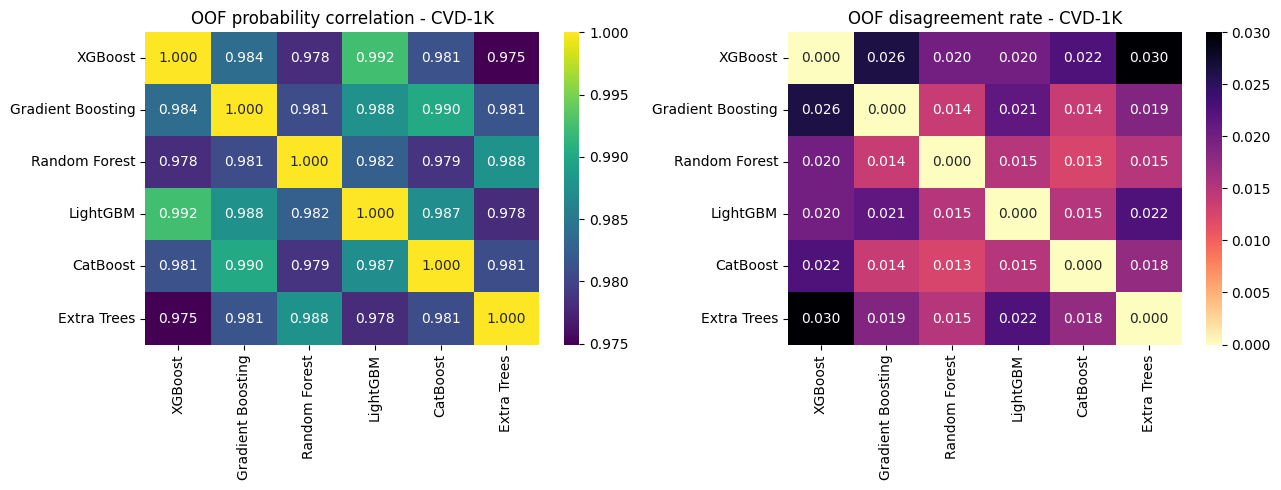

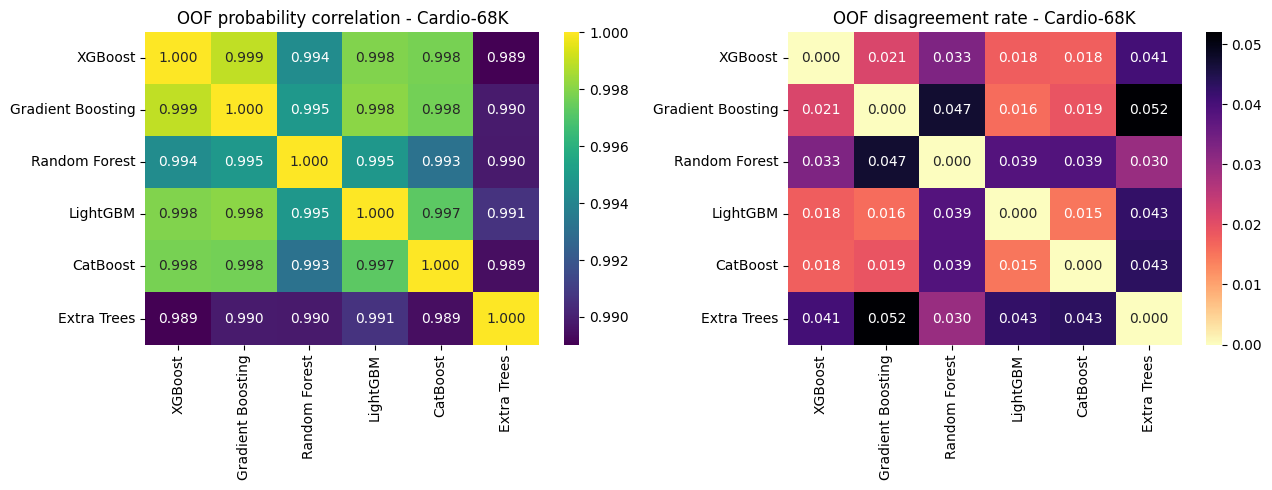

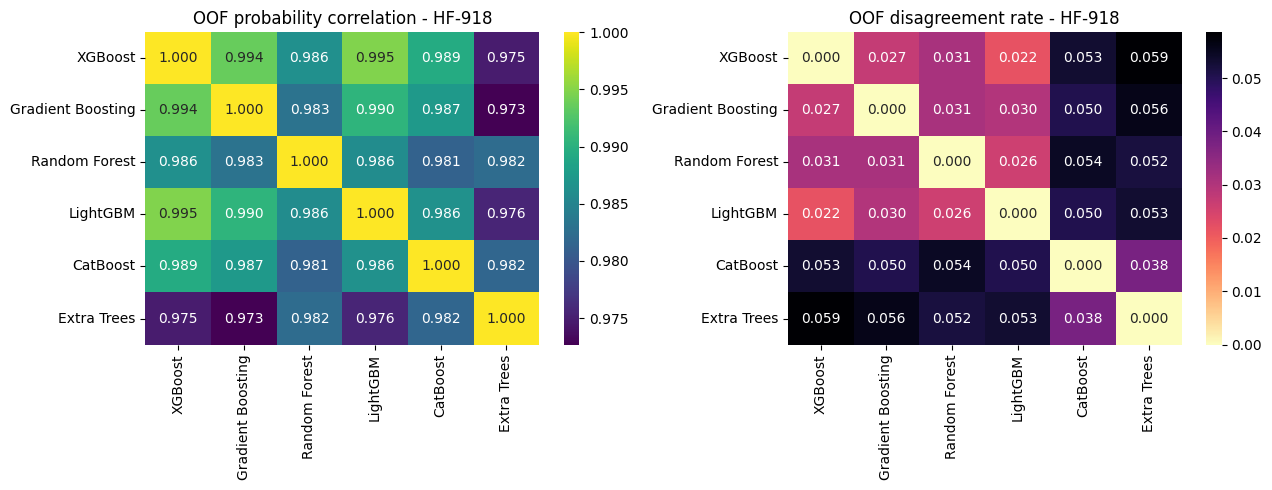

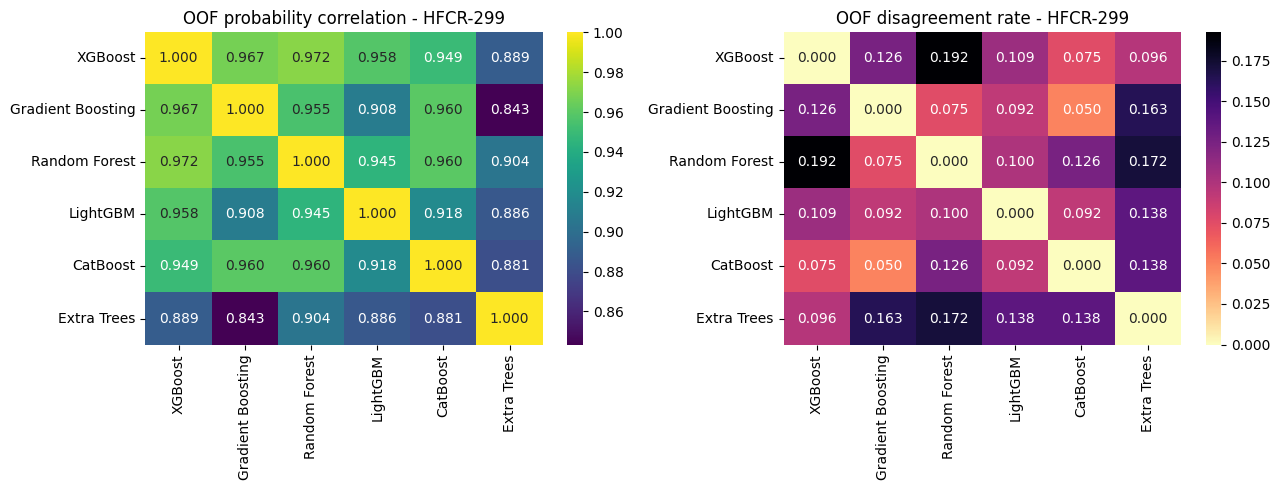

In [36]:
for name in DATA:
    M, y = STORE[name], SPLITS[name]["ytr"]
    oof = np.column_stack([M[m]["oof"] for m in STACK_LEARNERS])
    labels = [FULL_NAME[m] for m in STACK_LEARNERS]
    hard = oof >= np.array([M[m]["thr"] for m in STACK_LEARNERS])
    corr = pd.DataFrame(np.corrcoef(oof.T), index=labels, columns=labels)
    dis = pd.DataFrame([[np.mean(hard[:, i] != hard[:, j]) for j in range(len(labels))] for i in range(len(labels))],
                       index=labels, columns=labels)
    corr.to_csv(OUT / f"oof_correlation_{slug(name)}.csv")
    dis.to_csv(OUT / f"oof_disagreement_{slug(name)}.csv")
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(corr, annot=True, fmt=".3f", cmap="viridis", ax=ax[0])
    sns.heatmap(dis, annot=True, fmt=".3f", cmap="magma_r", ax=ax[1])
    ax[0].set_title(f"OOF probability correlation - {name}")
    ax[1].set_title(f"OOF disagreement rate - {name}")
    savefig(f"diversity_{name}")

## 13. Calibration and decision curve analysis


=== CVD-1K ===


,Model,Brier,Calibration slope,Calibration-in-the-large (obs − pred)
0,LF-Stack,0.0081,1.3486,0.0020
1,CatBoost,0.0064,1.2250,-0.0015
2,Logistic Regression,0.0135,1.4507,-0.0014


,Threshold,Net benefit (model),Net benefit (treat all),Net benefit (treat none)
5,0.1,0.5783,0.5333,0.0
15,0.2,0.5712,0.4750,0.0
25,0.3,0.5707,0.4000,0.0
35,0.4,0.5683,0.3000,0.0
45,0.5,0.5700,0.1600,0.0
55,0.6,0.5675,-0.0500,0.0


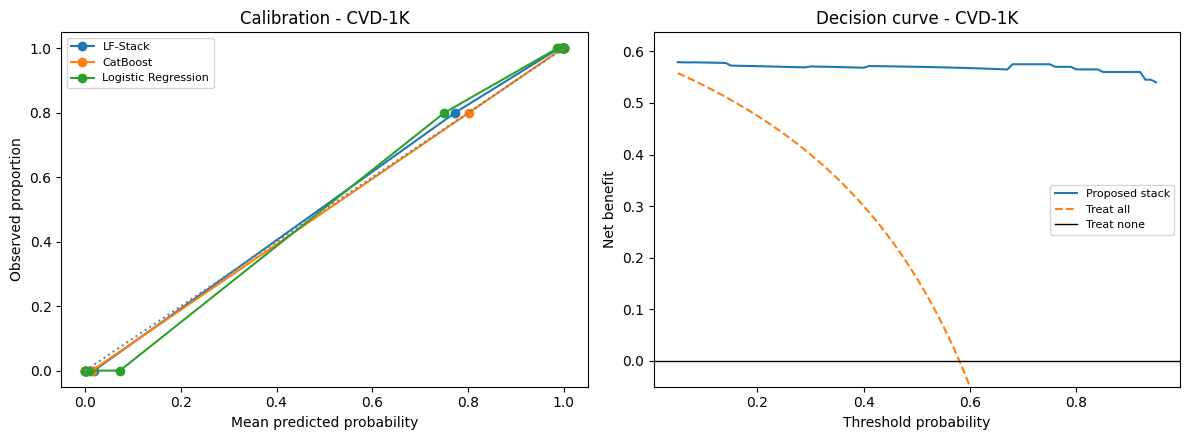


=== Cardio-68K ===


,Model,Brier,Calibration slope,Calibration-in-the-large (obs − pred)
0,LF-Stack,0.1803,0.9964,-0.0066
1,LightGBM,0.1812,1.0943,-0.0060
2,Logistic Regression,0.1870,0.9984,-0.0055


,Threshold,Net benefit (model),Net benefit (treat all),Net benefit (treat none)
5,0.1,0.4391,0.4387,0.0
15,0.2,0.3804,0.3685,0.0
25,0.3,0.3219,0.2783,0.0
35,0.4,0.2765,0.1580,0.0
45,0.5,0.2289,-0.0104,0.0
55,0.6,0.1888,-0.2629,0.0


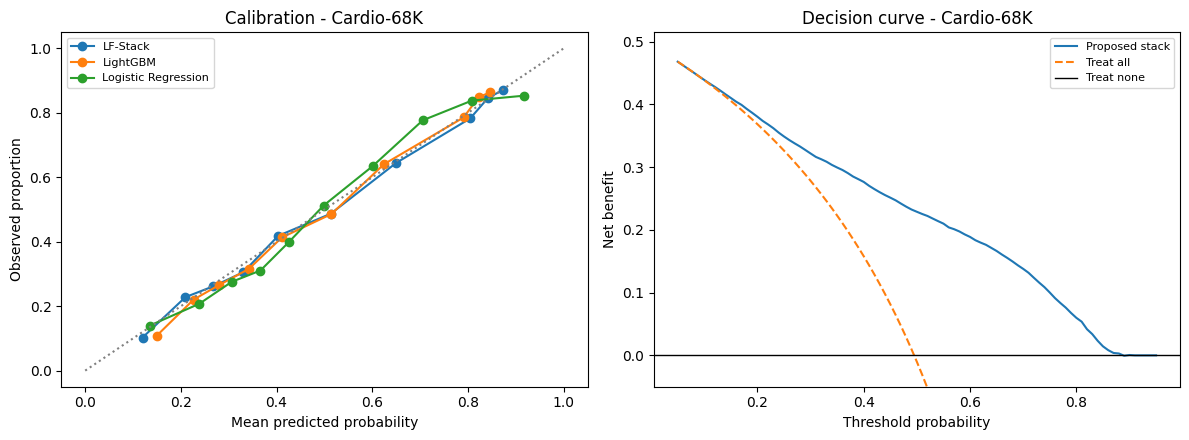


=== HF-918 ===


,Model,Brier,Calibration slope,Calibration-in-the-large (obs − pred)
0,LF-Stack,0.0957,0.9480,0.0177
1,Random Forest,0.1028,1.5113,0.0132
2,Logistic Regression,0.0973,1.0836,0.0212


,Threshold,Net benefit (model),Net benefit (treat all),Net benefit (treat none)
5,0.1,0.5042,0.5048,0.0
15,0.2,0.4878,0.4429,0.0
25,0.3,0.4752,0.3634,0.0
35,0.4,0.4656,0.2572,0.0
45,0.5,0.4457,0.1087,0.0
55,0.6,0.4130,-0.1141,0.0


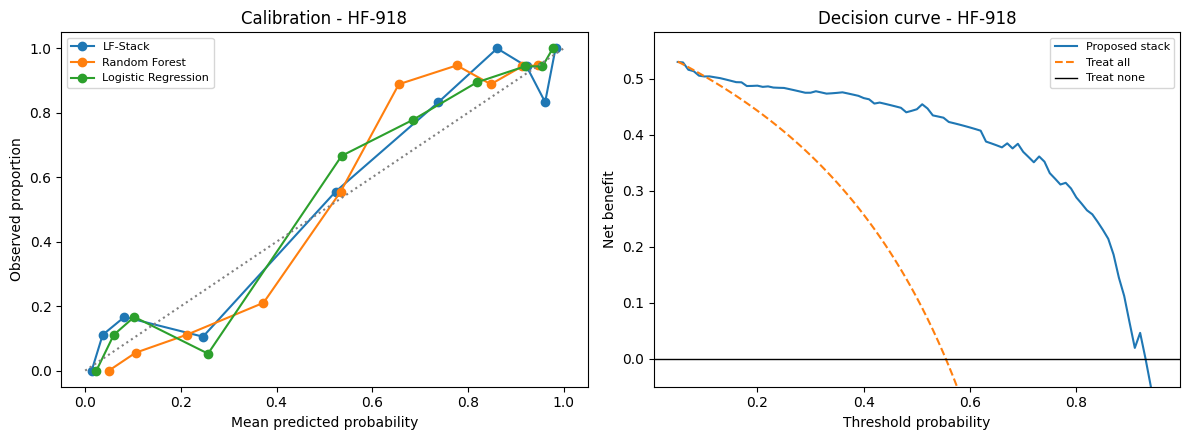


=== HFCR-299 ===


,Model,Brier,Calibration slope,Calibration-in-the-large (obs − pred)
0,LF-Stack,0.1654,0.9831,0.0134
1,XGBoost,0.1769,1.4200,0.0046
2,Logistic Regression,0.1860,0.7273,0.0443


,Threshold,Net benefit (model),Net benefit (treat all),Net benefit (treat none)
5,0.1,0.2463,0.2407,0.0
15,0.2,0.2292,0.1458,0.0
25,0.3,0.1548,0.0238,0.0
35,0.4,0.1278,-0.1389,0.0
45,0.5,0.0833,-0.3667,0.0
55,0.6,0.0083,-0.7083,0.0


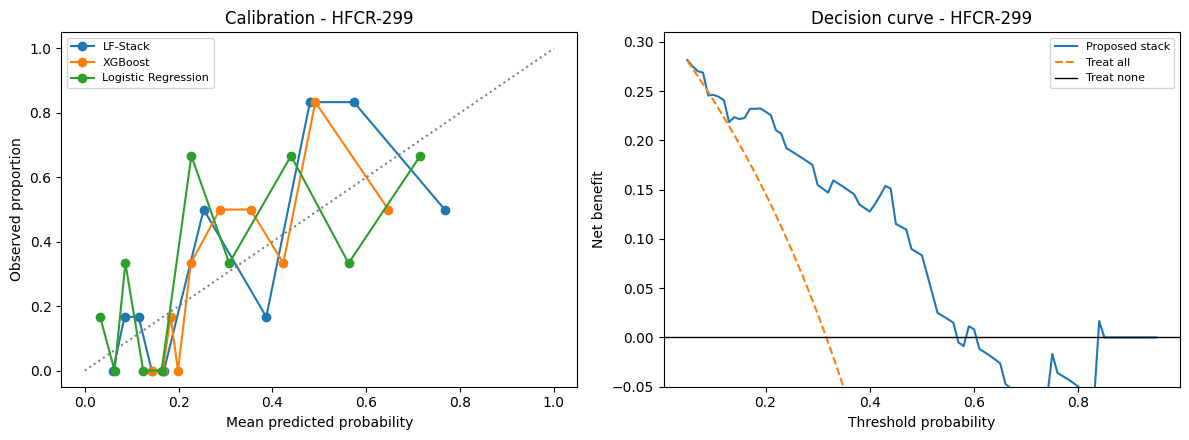

In [37]:
def calibration_summary(y, p):
    lp = logit(p).reshape(-1, 1)
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(lp, y).coef_[0, 0]
    return {"Brier": brier_score_loss(y, p), "Calibration slope": slope, "Calibration-in-the-large (obs − pred)": y.mean() - p.mean()}


def decision_curve(y, p, thresholds=np.round(np.arange(0.05, 0.96, 0.01), 2)):
    n, prev = len(y), y.mean()
    rows = []
    for t in thresholds:
        yhat = p >= t
        tp, fp = np.sum(yhat & (y == 1)), np.sum(yhat & (y == 0))
        rows.append({"Threshold": t, "Net benefit (model)": tp / n - fp / n * t / (1 - t),
                     "Net benefit (treat all)": prev - (1 - prev) * t / (1 - t), "Net benefit (treat none)": 0.0})
    return pd.DataFrame(rows)


CALIBRATION, DCA = {}, {}
for name in DATA:
    y, M = SPLITS[name]["yte"], STORE[name]
    best = HEADLINE.loc[HEADLINE["Dataset"] == name, "Best single model"].iloc[0]
    best_key = next(k for k, v in FULL_NAME.items() if v == best)
    keys = list(dict.fromkeys(["STACK", best_key, "LR"]))
    CALIBRATION[name] = pd.DataFrame([{"Model": FULL_NAME[k], **calibration_summary(y, M[k]["test"])} for k in keys])
    DCA[name] = decision_curve(y, M["STACK"]["test"])
    CALIBRATION[name].to_csv(OUT / f"calibration_{slug(name)}.csv", index=False)
    DCA[name].to_csv(OUT / f"dca_{slug(name)}.csv", index=False)
    print(f"\n=== {name} ===")
    display(CALIBRATION[name].round(4))
    display(DCA[name][DCA[name]["Threshold"].isin([0.1, 0.2, 0.3, 0.4, 0.5, 0.6])].round(4))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for k in keys:
        fy, fx = calibration_curve(y, M[k]["test"], n_bins=10, strategy="quantile")
        ax[0].plot(fx, fy, marker="o", label=FULL_NAME[k])
    ax[0].plot([0, 1], [0, 1], ":", color="grey")
    ax[0].set_xlabel("Mean predicted probability")
    ax[0].set_ylabel("Observed proportion")
    ax[0].set_title(f"Calibration - {name}")
    ax[0].legend(fontsize=8)
    d = DCA[name]
    ax[1].plot(d["Threshold"], d["Net benefit (model)"], label="Proposed stack")
    ax[1].plot(d["Threshold"], d["Net benefit (treat all)"], "--", label="Treat all")
    ax[1].axhline(0, color="black", lw=1, label="Treat none")
    ax[1].set_ylim(-0.05, max(0.05, d["Net benefit (model)"].max() * 1.1))
    ax[1].set_xlabel("Threshold probability")
    ax[1].set_ylabel("Net benefit")
    ax[1].set_title(f"Decision curve - {name}")
    ax[1].legend(fontsize=8)
    savefig(f"calibration_dca_{name}")

## 13b. Threshold rules: accuracy-maximising, Youden, sensitivity-targeted and fixed clinical thresholds


In [38]:
THR_FINE = np.round(np.arange(0.01, 0.991, 0.01), 2)
SENS_TARGET = 0.90
CLINICAL_THR = [0.2, 0.3]


def sens_spec(y, yhat):
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return tp / max(tp + fn, 1), tn / max(tn + fp, 1), tp, fp, tn, fn


def threshold_rules(y_oof, p_oof):
    ss = np.array([sens_spec(y_oof, p_oof >= t)[:2] for t in THR_FINE])
    ok = np.where(ss[:, 0] >= SENS_TARGET)[0]
    rules = {"Accuracy-maximising (0.30–0.70)": best_threshold(y_oof, p_oof),
             "Youden J": float(THR_FINE[(ss[:, 0] + ss[:, 1]).argmax()]),
             f"Sensitivity ≥ {SENS_TARGET:.2f}": float(THR_FINE[ok.max()]) if len(ok) else np.nan}
    rules.update({f"Fixed {t:.1f}": t for t in CLINICAL_THR})
    return rules


THRESHOLD_RULES = []
for name in DATA:
    S, st = SPLITS[name], STORE[name]["STACK"]
    y, p, n, prev = S["yte"], st["test"], len(S["yte"]), S["yte"].mean()
    for rule, t in threshold_rules(S["ytr"], st["oof"]).items():
        if np.isnan(t):
            continue
        sens, spec, tp, fp, tn, fn = sens_spec(y, p >= t)
        nb = tp / n - fp / n * t / (1 - t)
        THRESHOLD_RULES.append({"Dataset": name, "Rule": rule, "Threshold": t, "Accuracy": (tp + tn) / n,
                                "Sensitivity": sens, "Specificity": spec, "PPV": tp / max(tp + fp, 1), "NPV": tn / max(tn + fn, 1),
                                "Flagged per 100": 100 * (tp + fp) / n, "Missed events per 100": 100 * fn / n,
                                "Net benefit": nb, "Net TP per 100 vs treat-all": 100 * (nb - (prev - (1 - prev) * t / (1 - t)))})
THRESHOLD_RULES = pd.DataFrame(THRESHOLD_RULES)
THRESHOLD_RULES.to_csv(OUT / "threshold_rules.csv", index=False)
display(THRESHOLD_RULES.round(3))


,Dataset,Rule,Threshold,Accuracy,Sensitivity,Specificity,PPV,NPV,Flagged per 100,Missed events per 100,Net benefit,Net TP per 100 vs treat-all
0,CVD-1K,Accuracy-maximising (0.30–0.70),0.45,0.990,0.991,0.988,0.991,0.988,58.000,0.500,0.571,33.455
1,CVD-1K,Youden J,0.73,0.995,0.991,1.000,1.000,0.988,57.500,0.500,0.575,113.056
2,CVD-1K,Sensitivity ≥ 0.90,0.95,0.960,0.931,1.000,1.000,0.913,54.000,4.000,0.540,794.000
3,CVD-1K,Fixed 0.2,0.20,0.980,0.991,0.964,0.975,0.988,59.000,0.500,0.571,9.625
4,CVD-1K,Fixed 0.3,0.30,0.985,0.991,0.976,0.983,0.988,58.500,0.500,0.571,17.071
5,Cardio-68K,Accuracy-maximising (0.30–0.70),0.51,0.735,0.689,0.781,0.755,0.719,45.167,15.403,0.225,25.636
6,Cardio-68K,Youden J,0.51,0.735,0.689,0.781,0.755,0.719,45.167,15.403,0.225,25.636
7,Cardio-68K,Sensitivity ≥ 0.90,0.27,0.656,0.906,0.411,0.601,0.816,74.574,4.673,0.338,3.003
8,Cardio-68K,Fixed 0.2,0.20,0.594,0.965,0.232,0.552,0.871,86.565,1.735,0.380,1.190
9,Cardio-68K,Fixed 0.3,0.30,0.678,0.877,0.483,0.624,0.800,69.500,6.101,0.322,4.355


## 14. Split-conformal prediction (target coverage 0.90)

In [39]:
def conformal_sets(p_cal, y_cal, p_eval, alpha=ALPHA):
    s = 1 - np.where(y_cal == 1, p_cal, 1 - p_cal)
    q = np.quantile(s, min(1.0, np.ceil((len(s) + 1) * (1 - alpha)) / len(s)), method="higher")
    return (1 - np.column_stack([1 - p_eval, p_eval])) <= q


CONFORMAL = []
for name in DATA:
    S, st = SPLITS[name], STORE[name]["STACK"]
    sets = conformal_sets(st["oof"], S["ytr"], st["test"])
    size = sets.sum(axis=1)
    rng, cover = np.random.RandomState(SEED), []
    for _ in range(N_CONF_SPLITS):
        perm = rng.permutation(len(S["yte"]))
        cal, ev = perm[: len(perm) // 2], perm[len(perm) // 2:]
        s2 = conformal_sets(st["test"][cal], S["yte"][cal], st["test"][ev])
        cover.append(s2[np.arange(len(ev)), S["yte"][ev]].mean())
    CONFORMAL.append({"Dataset": name, "Target coverage": 1 - ALPHA,
                      "Coverage (calibrated on training OOF)": sets[np.arange(len(S["yte"])), S["yte"]].mean(),
                      "Mean set size": size.mean(), "Singleton rate": np.mean(size == 1),
                      "Coverage (repeated test splits, mean)": np.mean(cover), "Coverage SD": np.std(cover)})
CONFORMAL = pd.DataFrame(CONFORMAL)
CONFORMAL.to_csv(OUT / "conformal.csv", index=False)
display(CONFORMAL.round(4))

,Dataset,Target coverage,Coverage (calibrated on training OOF),Mean set size,Singleton rate,"Coverage (repeated test splits, mean)",Coverage SD
0,CVD-1K,0.9,0.9450,0.9450,0.9450,0.9108,0.0389
1,Cardio-68K,0.9,0.8973,1.4219,0.5781,0.8993,0.0051
2,HF-918,0.9,0.9239,1.0870,0.9130,0.9148,0.0410
3,HFCR-299,0.9,0.8833,1.3500,0.6500,0.9313,0.0701


## 15. Subgroup fairness by sex

In [40]:
FAIRNESS = []
for name in DATA:
    S, st = SPLITS[name], STORE[name]["STACK"]
    g, y, yhat = S["Xte"][DATA[name]["sex_col"]].values, S["yte"], (st["test"] >= st["thr"]).astype(int)
    grp = []
    for lev in np.unique(g):
        m = g == lev
        grp.append({"rate": yhat[m].mean(), "tpr": yhat[m & (y == 1)].mean() if (m & (y == 1)).any() else np.nan,
                    "fpr": yhat[m & (y == 0)].mean() if (m & (y == 0)).any() else np.nan, "acc": accuracy_score(y[m], yhat[m])})
    grp = pd.DataFrame(grp)
    FAIRNESS.append({"Dataset": name, "Demographic parity difference": grp["rate"].max() - grp["rate"].min(),
                     "Equal opportunity difference (TPR)": grp["tpr"].max() - grp["tpr"].min(),
                     "FPR difference": grp["fpr"].max() - grp["fpr"].min(), "Accuracy difference": grp["acc"].max() - grp["acc"].min(),
                     "Outcome prevalence difference": abs(y[g == np.unique(g)[0]].mean() - y[g == np.unique(g)[-1]].mean())})
FAIRNESS = pd.DataFrame(FAIRNESS)
FAIRNESS.to_csv(OUT / "fairness.csv", index=False)
display(FAIRNESS.round(4))

,Dataset,Demographic parity difference,Equal opportunity difference (TPR),FPR difference,Accuracy difference,Outcome prevalence difference
0,CVD-1K,0.0192,0.0111,0.0156,0.0130,0.0192
1,Cardio-68K,0.0084,0.0050,0.0042,0.0003,0.0080
2,HF-918,0.4986,0.0417,0.1600,0.1107,0.4996
3,HFCR-299,0.0706,0.0357,0.1437,0.0822,0.0757


## 15b. Subgroup performance by sex and age


In [41]:
SEX_LABELS = {"Cardio-68K": {1: "Female", 2: "Male"}}


def subgroup_rows(name):
    S, st = SPLITS[name], STORE[name]["STACK"]
    X, y, p, thr = S["Xte"], S["yte"], st["test"], st["thr"]
    cut = float(np.median(S["Xtr"]["age"]))
    sex = X[DATA[name]["sex_col"]].map(SEX_LABELS.get(name, {0: "Female", 1: "Male"})).values
    groups = {**{f"Sex: {s}": sex == s for s in ["Female", "Male"]},
              f"Age < {cut:.0f}": (X["age"] < cut).values, f"Age ≥ {cut:.0f}": (X["age"] >= cut).values}
    rows = []
    for g, m in groups.items():
        ym, pm = y[m], p[m]
        sens, spec = sens_spec(ym, pm >= thr)[:2]
        rows.append({"Dataset": name, "Subgroup": g, "n": int(m.sum()), "Events": int(ym.sum()), "Prevalence": ym.mean(),
                     "Accuracy": accuracy_score(ym, pm >= thr), "Sensitivity": sens, "Specificity": spec,
                     "ROC-AUC": roc_auc_score(ym, pm) if 0 < ym.sum() < len(ym) else np.nan, "Brier": brier_score_loss(ym, pm),
                     "Mean predicted": pm.mean()})
    return rows


SUBGROUPS = pd.DataFrame([r for name in DATA for r in subgroup_rows(name)])
SUBGROUPS.to_csv(OUT / "subgroups_sex_age.csv", index=False)
display(SUBGROUPS.round(3))


,Dataset,Subgroup,n,Events,Prevalence,Accuracy,Sensitivity,Specificity,ROC-AUC,Brier,Mean predicted
0,CVD-1K,Sex: Female,46,26,0.565,1.000,1.000,1.000,1.000,0.001,0.562
1,CVD-1K,Sex: Male,154,90,0.584,0.987,0.989,0.984,0.999,0.010,0.583
2,CVD-1K,Age < 49,100,55,0.550,0.980,0.982,0.978,0.999,0.016,0.550
3,CVD-1K,Age ≥ 49,100,61,0.610,1.000,1.000,1.000,1.000,0.001,0.606
4,Cardio-68K,Sex: Female,9011,4434,0.492,0.735,0.687,0.782,0.801,0.181,0.499
5,Cardio-68K,Sex: Male,4707,2354,0.500,0.735,0.692,0.778,0.803,0.179,0.507
6,Cardio-68K,Age < 54,6950,2754,0.396,0.772,0.605,0.882,0.810,0.165,0.406
7,Cardio-68K,Age ≥ 54,6768,4034,0.596,0.697,0.746,0.625,0.751,0.196,0.600
8,HF-918,Sex: Female,38,6,0.158,0.974,0.833,1.000,0.943,0.056,0.207
9,HF-918,Sex: Male,146,96,0.658,0.863,0.875,0.840,0.908,0.106,0.622


## 16. Robustness: input perturbation, missing inputs, monotonicity

In [42]:
def perturbation(name):
    S, stack = SPLITS[name], STORE[name]["STACK"]["est"]
    rng = np.random.RandomState(SEED)
    Xs = S["Xte"].sample(n=min(N_ROBUST, len(S["Xte"])), random_state=SEED).reset_index(drop=True)
    cont = [c for c in numeric_of(name) if DATA[name]["X"][c].nunique() > 5]
    base = stack.predict(Xs)
    rows = []
    for eps in ROBUST_EPS:
        stable = []
        for _ in range(ROBUST_TRIALS):
            Xp = Xs.copy()
            for c in cont:
                v = Xp[c].values.astype(float)
                Xp[c] = v + rng.uniform(-eps, eps, size=len(v)) * np.abs(v)
            stable.append(np.mean(stack.predict(Xp) == base))
        rows.append({"Dataset": name, "Perturbation": f"±{int(eps * 100)}%", "Prediction stability": np.mean(stable),
                     "SD": np.std(stable), "Patients": len(Xs), "Trials": ROBUST_TRIALS})
    return rows


ROBUST = pd.DataFrame([r for n in DATA for r in perturbation(n)])
ROBUST.to_csv(OUT / "robustness_perturbation.csv", index=False)
display(ROBUST.round(4))

,Dataset,Perturbation,Prediction stability,SD,Patients,Trials
0,CVD-1K,±1%,0.9965,0.0023,200,10
1,CVD-1K,±3%,0.9965,0.0023,200,10
2,CVD-1K,±5%,0.9940,0.0044,200,10
3,Cardio-68K,±1%,0.9698,0.0033,500,10
4,Cardio-68K,±3%,0.9576,0.0106,500,10
5,Cardio-68K,±5%,0.9468,0.0069,500,10
6,HF-918,±1%,0.9880,0.0033,184,10
7,HF-918,±3%,0.9832,0.0071,184,10
8,HF-918,±5%,0.9793,0.0063,184,10
9,HFCR-299,±1%,0.9850,0.0090,60,10


In [43]:
def missing_inputs(name):
    S, stack = SPLITS[name], STORE[name]["STACK"]["est"]
    p0 = stack.predict_proba(S["Xte"])
    rows = []
    for c in cols_of(name):
        Xm = S["Xte"].copy()
        Xm[c] = np.nan
        p = stack.predict_proba(Xm)
        rows.append({"Dataset": name, "Feature withheld": c, "Accuracy": accuracy_score(S["yte"], p >= STORE[name]["STACK"]["thr"]),
                     "ROC-AUC": roc_auc_score(S["yte"], p), "ΔAUC": roc_auc_score(S["yte"], p) - roc_auc_score(S["yte"], p0)})
    return pd.DataFrame(rows).sort_values("ΔAUC").head(5)


MISSING = pd.concat([missing_inputs(n) for n in DATA], ignore_index=True)
MISSING.to_csv(OUT / "robustness_missing_inputs.csv", index=False)
display(MISSING.round(4))

,Dataset,Feature withheld,Accuracy,ROC-AUC,ΔAUC
0,CVD-1K,slope,0.7550,0.9769,-0.0228
1,CVD-1K,chestpain,0.9800,0.9962,-0.0035
2,CVD-1K,restingBP,0.9750,0.9970,-0.0027
3,CVD-1K,oldpeak,0.9800,0.9976,-0.0021
4,CVD-1K,gender,0.9750,0.9986,-0.0011
5,Cardio-68K,ap_hi,0.6578,0.7656,-0.0359
6,Cardio-68K,age,0.7297,0.7832,-0.0184
7,Cardio-68K,cholesterol,0.7214,0.7910,-0.0105
8,Cardio-68K,map,0.7341,0.7980,-0.0036
9,Cardio-68K,gluc,0.7338,0.7994,-0.0022


In [44]:
def refresh_engineered(X):
    X = X.copy()
    c = set(X.columns)
    if {"age", "maxheartrate", "hr_reserve"} <= c:
        X["hr_reserve"] = (220 - X["age"]) - X["maxheartrate"]
    if {"restingBP", "maxheartrate", "rate_pressure_product"} <= c:
        X["rate_pressure_product"] = X["restingBP"] * X["maxheartrate"] / 100
    if {"serumcholestrol", "age", "chol_age_ratio"} <= c:
        X["chol_age_ratio"] = X["serumcholestrol"] / X["age"]
    if {"weight", "height", "bmi"} <= c:
        X["bmi"] = X["weight"] / (X["height"] / 100) ** 2
    if {"ap_hi", "ap_lo", "map"} <= c:
        X["map"] = X["ap_lo"] + (X["ap_hi"] - X["ap_lo"]) / 3
    if {"ap_hi", "ap_lo", "pulse_pressure"} <= c:
        X["pulse_pressure"] = X["ap_hi"] - X["ap_lo"]
    return X


def monotonicity(name):
    S, stack = SPLITS[name], STORE[name]["STACK"]["est"]
    Xs = S["Xte"].sample(n=min(N_ROBUST, len(S["Xte"])), random_state=SEED).reset_index(drop=True)
    p0 = stack.predict_proba(Xs)
    rows = []
    for c in [f for f in MONO_FEATURES if f in cols_of(name)]:
        ok = Xs[c].notna().to_numpy()
        levels = np.sort(DATA[name]["X"][c].dropna().unique())
        Xp = Xs.copy()
        if len(levels) <= 5:
            Xp[c] = np.minimum(Xs[c] + 1, levels.max())
            ok = ok & (Xs[c] < levels.max()).to_numpy()
            step = "+1 level"
        else:
            d = MONO_STEP_SD * S["Xtr"][c].std()
            Xp[c] = Xs[c] + d
            step = f"+{MONO_STEP_SD} SD"
        dp = stack.predict_proba(refresh_engineered(Xp)) - p0
        rows.append({"Dataset": name, "Feature": c, "Step": step, "Patients": int(ok.sum()),
                     "Pass rate (risk non-decreasing)": float(np.mean(dp[ok] >= -1e-6)) if ok.any() else np.nan,
                     "Mean change in risk": float(dp[ok].mean()) if ok.any() else np.nan})
    return rows


MONO = pd.DataFrame([r for n in DATA for r in monotonicity(n)])
MONO.to_csv(OUT / "monotonicity.csv", index=False)
display(MONO.round(4))

,Dataset,Feature,Step,Patients,Pass rate (risk non-decreasing),Mean change in risk
0,CVD-1K,age,+0.5 SD,200,0.5650,-0.0005
1,CVD-1K,restingBP,+0.5 SD,200,0.6150,0.0137
2,CVD-1K,serumcholestrol,+0.5 SD,190,0.7263,0.0083
3,CVD-1K,oldpeak,+0.5 SD,200,0.3750,-0.0084
4,Cardio-68K,age,+0.5 SD,500,0.8600,0.0341
5,Cardio-68K,ap_hi,+0.5 SD,500,0.9780,0.0504
6,Cardio-68K,cholesterol,+1 level,442,0.9819,0.0752
7,Cardio-68K,gluc,+1 level,465,0.4710,-0.0033
8,Cardio-68K,weight,+0.5 SD,500,0.9040,0.0141
9,HF-918,age,+0.5 SD,184,0.5761,0.0080


## 17. SHAP explanations (global, local, consistency)

PermutationExplainer explainer: 201it [03:38,  1.11s/it]                         


=== CVD-1K ===


,Feature,Mean |SHAP|
10,slope,0.2972
3,restingBP,0.0691
2,chestpain,0.0593
9,oldpeak,0.0408
6,restingrelectro,0.0313
1,gender,0.0296
4,serumcholestrol,0.0239
11,noofmajorvessels,0.0179
7,maxheartrate,0.0130
5,fastingbloodsugar,0.0101


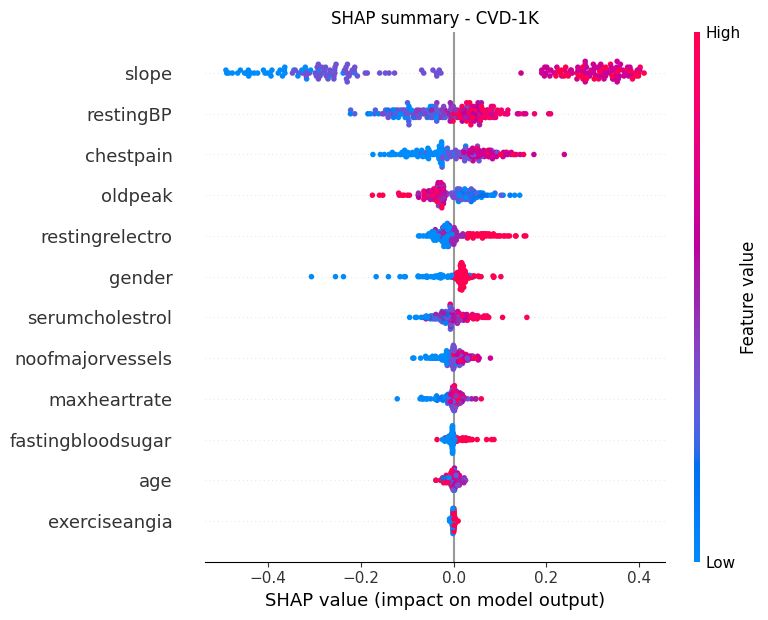

PermutationExplainer explainer: 201it [03:09,  1.00it/s]                         


=== Cardio-68K ===


,Feature,Mean |SHAP|
4,ap_hi,0.1419
6,cholesterol,0.0517
0,age,0.0454
12,map,0.0404
11,bmi,0.0136
10,active,0.0133
3,weight,0.0082
13,pulse_pressure,0.0082
7,gluc,0.0071
5,ap_lo,0.0059


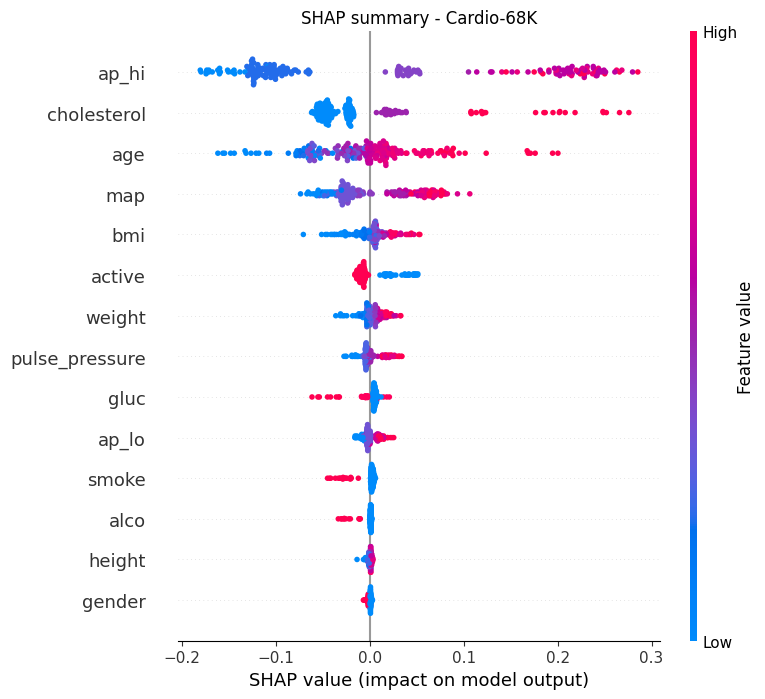

PermutationExplainer explainer: 185it [03:24,  1.17s/it]                         


=== HF-918 ===


,Feature,Mean |SHAP|
10,slope,0.1981
2,chestpain,0.1035
1,gender,0.0549
8,exerciseangia,0.0404
9,oldpeak,0.0391
7,maxheartrate,0.0346
4,serumcholestrol,0.0326
5,fastingbloodsugar,0.0304
0,age,0.0173
3,restingBP,0.0158


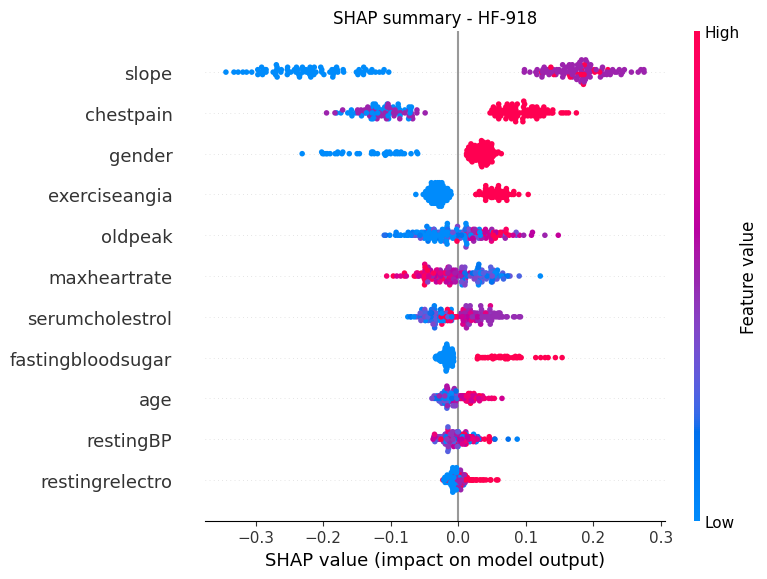

PermutationExplainer explainer: 61it [00:49,  1.04s/it]                        


=== HFCR-299 ===


,Feature,Mean |SHAP|
4,ejection_fraction,0.0932
7,serum_creatinine,0.0744
0,age,0.0605
8,serum_sodium,0.0275
5,high_blood_pressure,0.0264
1,anaemia,0.0188
3,diabetes,0.0106
6,platelets,0.0079
2,creatinine_phosphokinase,0.0066
10,smoking,0.0051


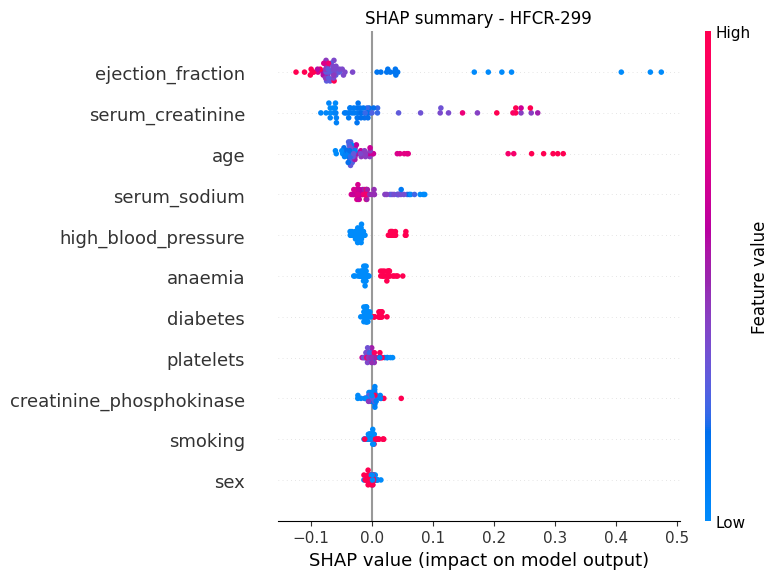

In [45]:
def shap_explain(name):
    S, stack = SPLITS[name], STORE[name]["STACK"]["est"]
    cols = cols_of(name)
    med = S["Xtr"][cols].median(numeric_only=True)
    bg = S["Xtr"][cols].fillna(med).sample(n=min(N_SHAP_BG, len(S["Xtr"])), random_state=SEED)
    idx = S["Xte"].sample(n=min(N_SHAP, len(S["Xte"])), random_state=SEED).index.values
    Xs = S["Xte"].loc[idx, cols].fillna(med)
    f = lambda A: stack.predict_proba(pd.DataFrame(A, columns=cols))
    explainer = shap.PermutationExplainer(f, shap.maskers.Independent(bg.values, max_samples=len(bg)), seed=SEED)
    sv = explainer(Xs.values, max_evals=4 * len(cols) + 2)
    sv.feature_names = cols
    return {"sv": sv, "idx": idx}


SHAP = {}
for name in DATA:
    SHAP[name], s, c = cached(f"{name}_shap", lambda: shap_explain(name))
    log_time(name, "STACK", "SHAP", s, c)
    sv = SHAP[name]["sv"]
    imp = pd.DataFrame({"Feature": sv.feature_names, "Mean |SHAP|": np.abs(sv.values).mean(axis=0)}).sort_values("Mean |SHAP|", ascending=False)
    imp.to_csv(OUT / f"shap_importance_{slug(name)}.csv", index=False)
    print(f"\n=== {name} ===")
    display(imp.head(10).round(4))
    shap.plots.beeswarm(sv, max_display=15, show=False)
    plt.title(f"SHAP summary - {name}")
    savefig(f"shap_summary_{name}")

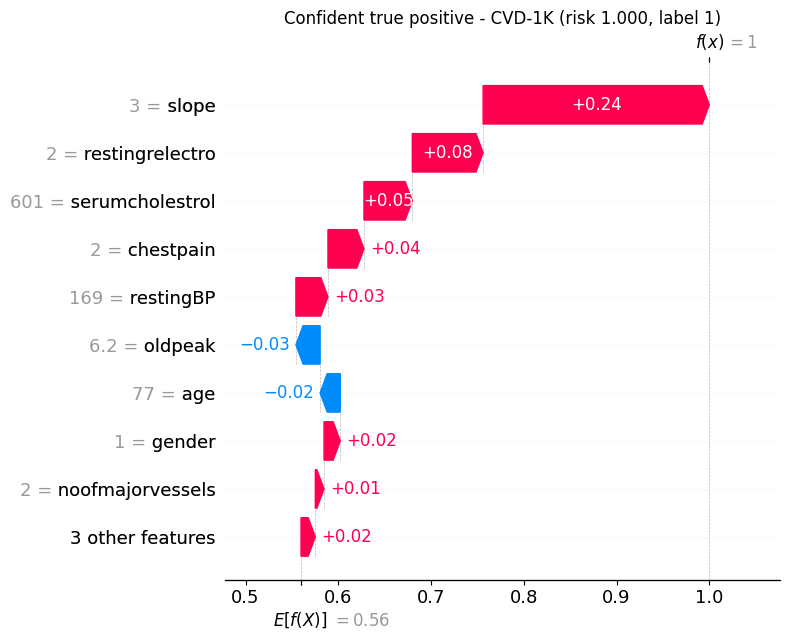

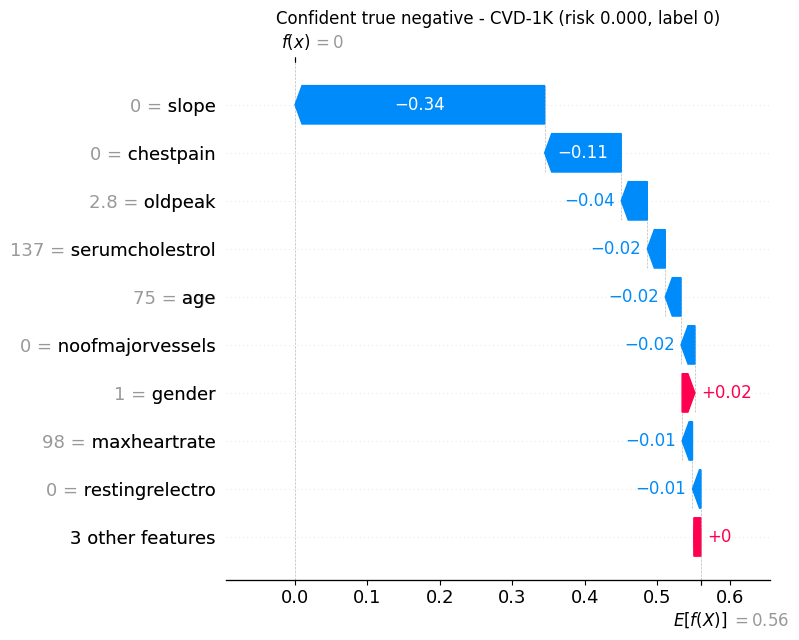

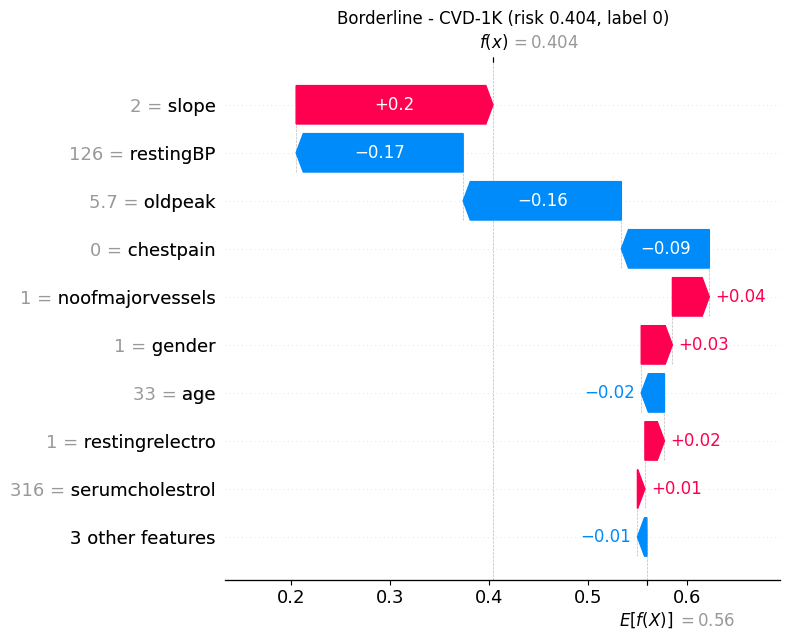

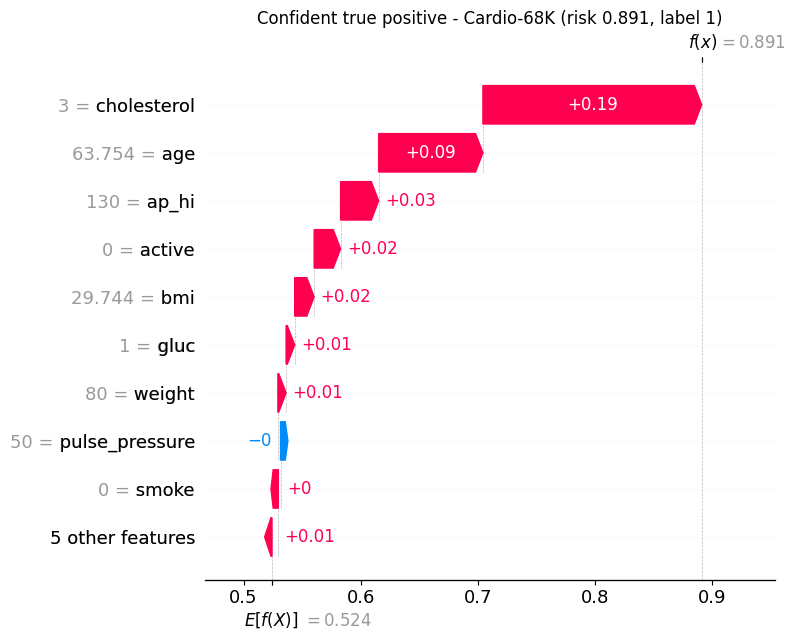

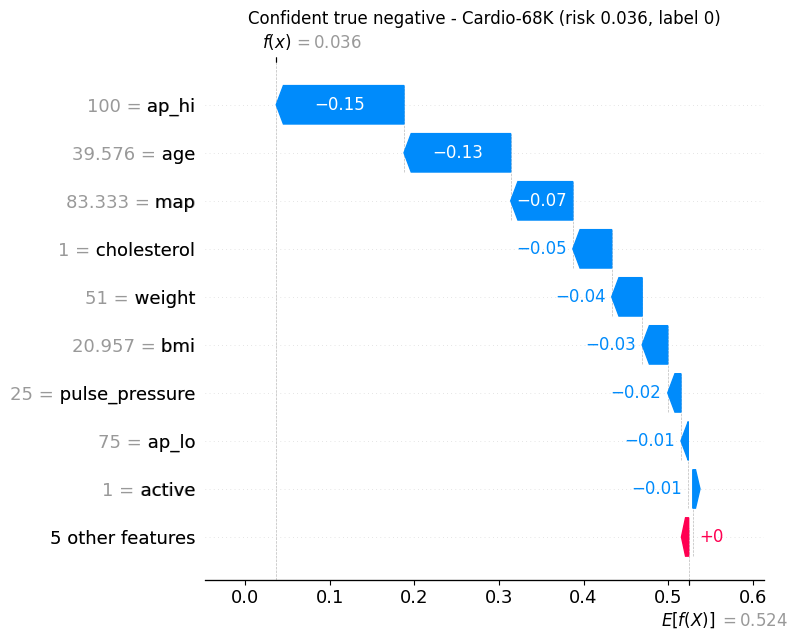

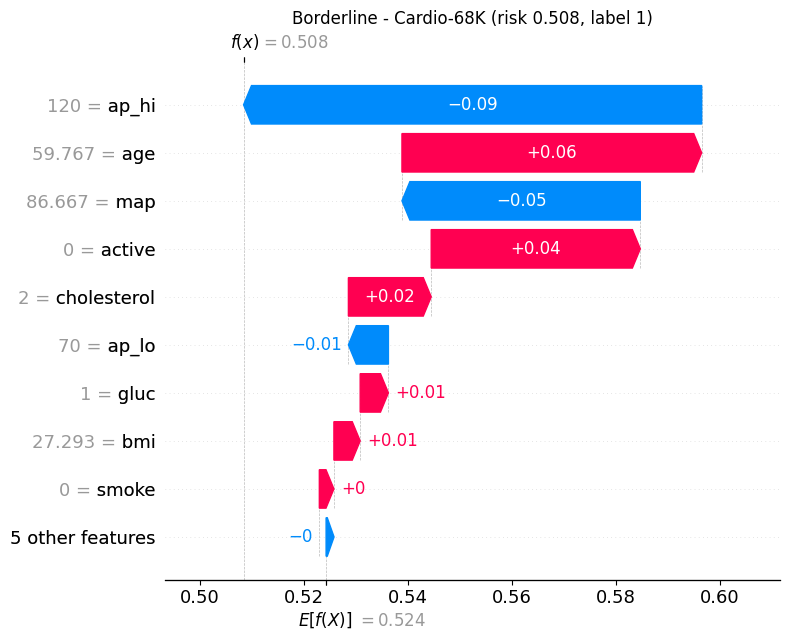

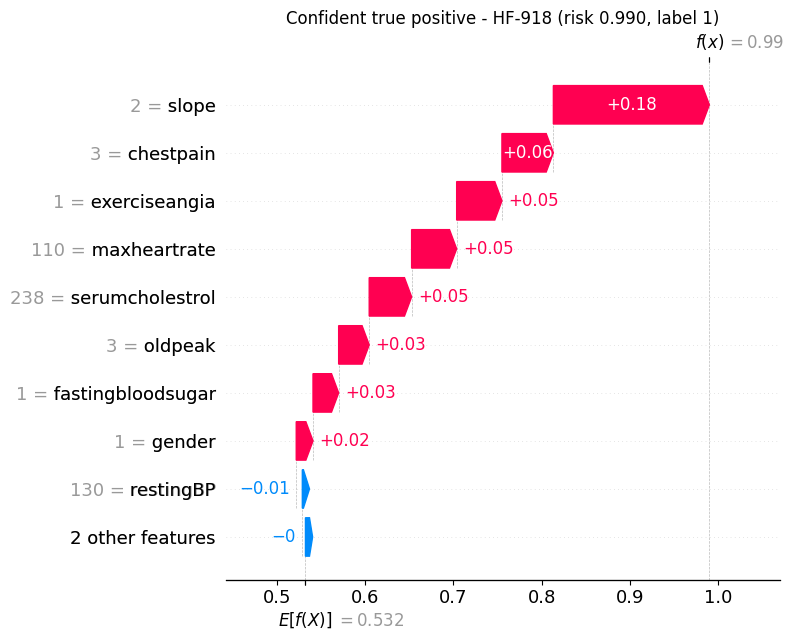

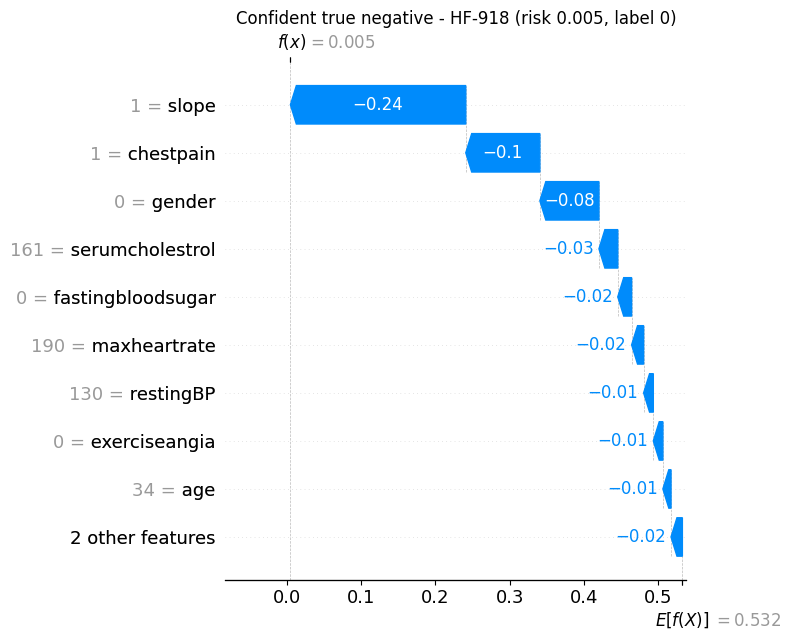

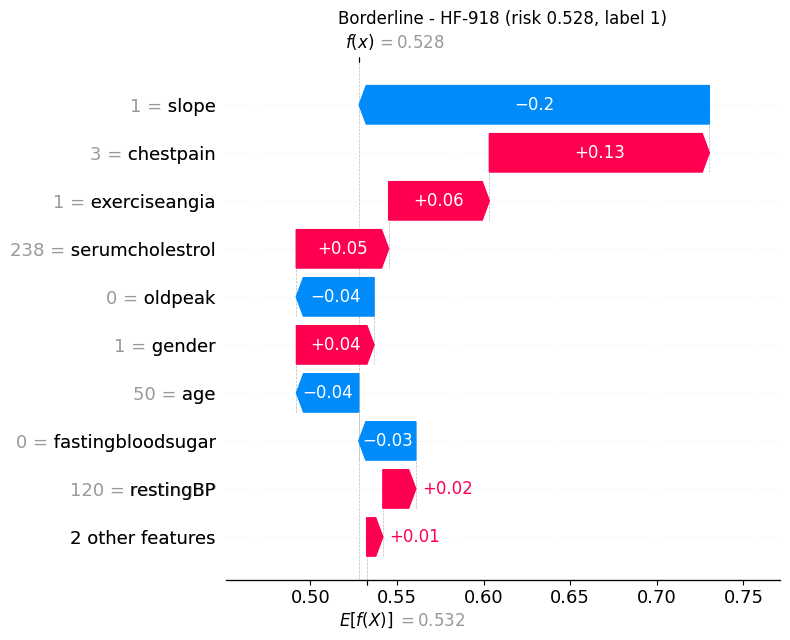

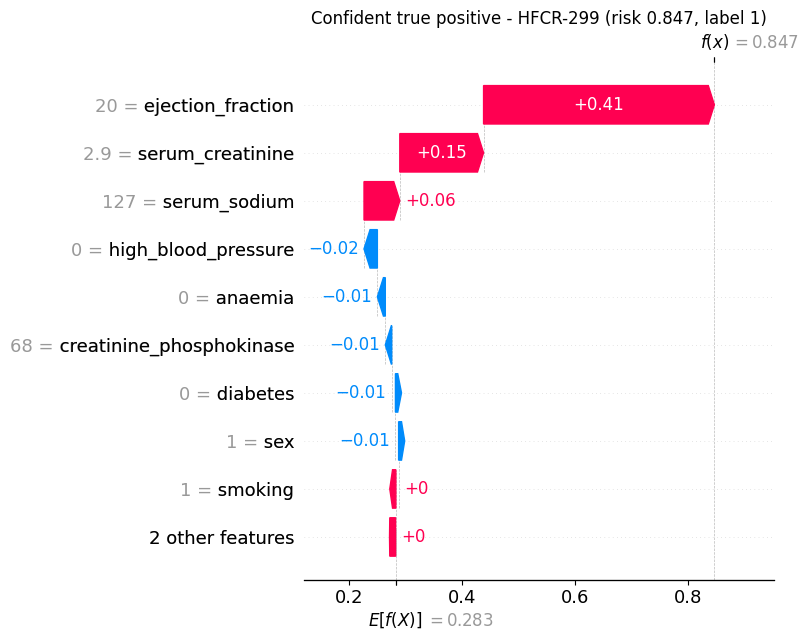

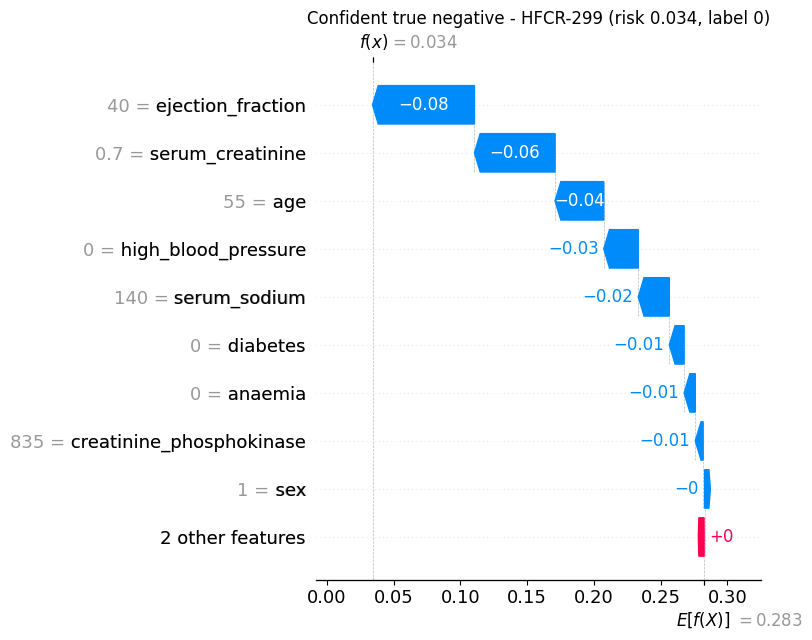

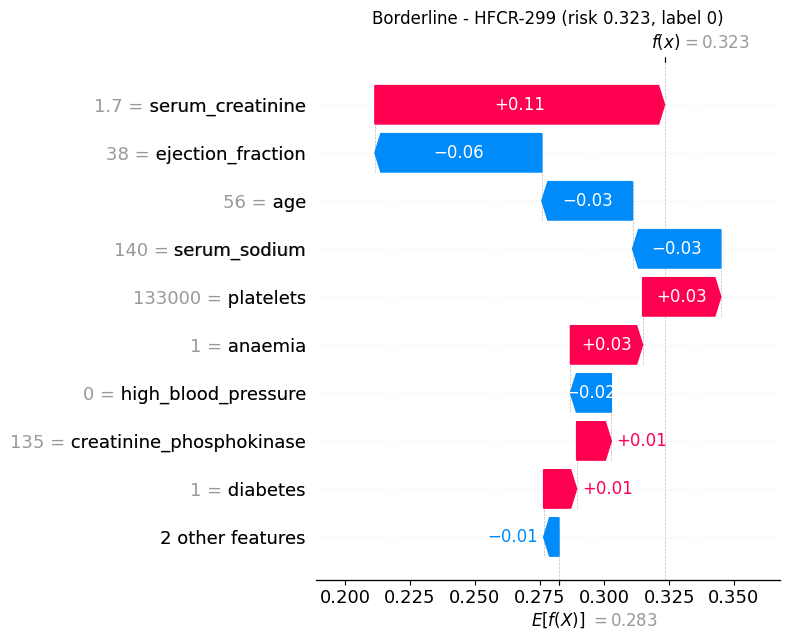

,Dataset,Case,Test row,Predicted risk,True label
0,CVD-1K,Confident true positive,26,0.9999,1
1,CVD-1K,Confident true negative,195,0.0000,0
2,CVD-1K,Borderline,110,0.4044,0
3,Cardio-68K,Confident true positive,6790,0.8913,1
4,Cardio-68K,Confident true negative,7820,0.0365,0
5,Cardio-68K,Borderline,12848,0.5084,1
6,HF-918,Confident true positive,28,0.9898,1
7,HF-918,Confident true negative,103,0.0047,0
8,HF-918,Borderline,101,0.5282,1
9,HFCR-299,Confident true positive,33,0.8472,1


In [46]:
LOCAL = []
for name in DATA:
    sv, idx = SHAP[name]["sv"], SHAP[name]["idx"]
    st, y = STORE[name]["STACK"], SPLITS[name]["yte"][idx]
    p = st["est"].predict_proba(pd.DataFrame(sv.data, columns=sv.feature_names))
    yhat = (p >= st["thr"]).astype(int)
    pos, neg = np.where((y == 1) & (yhat == 1))[0], np.where((y == 0) & (yhat == 0))[0]
    cases = {"Confident true positive": pos[np.argmax(p[pos])] if len(pos) else None,
             "Confident true negative": neg[np.argmin(p[neg])] if len(neg) else None,
             "Borderline": int(np.argmin(np.abs(p - st["thr"])))}
    for label, i in cases.items():
        if i is None:
            continue
        LOCAL.append({"Dataset": name, "Case": label, "Test row": int(idx[i]), "Predicted risk": p[i], "True label": int(y[i])})
        shap.plots.waterfall(sv[i], max_display=10, show=False)
        plt.title(f"{label} - {name} (risk {p[i]:.3f}, label {y[i]})")
        savefig(f"shap_local_{name}_{label}")
LOCAL = pd.DataFrame(LOCAL)
LOCAL.to_csv(OUT / "shap_local_cases.csv", index=False)
display(LOCAL.round(4))

In [47]:
def shap_consistency(name):
    sv, stack, S = SHAP[name]["sv"], STORE[name]["STACK"]["est"], SPLITS[name]
    cols = list(sv.feature_names)
    med = S["Xtr"][cols].median(numeric_only=True)
    Xs = pd.DataFrame(sv.data, columns=cols)
    p0 = stack.predict_proba(Xs)
    occ = np.column_stack([np.abs(stack.predict_proba(Xs.assign(**{c: med[c]})) - p0) for c in cols])
    A, r = np.abs(sv.values), np.arange(len(Xs))
    top, bot = A.argmax(axis=1), A.argmin(axis=1)
    return {"Dataset": name, "Patients": len(Xs), "Top-vs-bottom consistency": float(np.mean(occ[r, top] >= occ[r, bot])),
            "Top-feature agreement": float(np.mean(top == occ.argmax(axis=1))),
            "Mean Spearman (|SHAP| vs occlusion)": float(np.nanmean([stats.spearmanr(A[i], occ[i]).correlation for i in r]))}


SHAP_CONS = pd.DataFrame([shap_consistency(n) for n in DATA])
SHAP_CONS.to_csv(OUT / "shap_consistency.csv", index=False)
display(SHAP_CONS.round(4))

,Dataset,Patients,Top-vs-bottom consistency,Top-feature agreement,Mean Spearman (|SHAP| vs occlusion)
0,CVD-1K,200,0.7500,0.4200,0.4355
1,Cardio-68K,200,0.7550,0.5050,0.4280
2,HF-918,184,0.6957,0.4457,0.2855
3,HFCR-299,60,0.9000,0.4667,0.4780


## 18. External validation (CVD-1K and HF-918, harmonised features)

In [48]:
EXT_COLS = ["age", "gender", "chestpain", "restingBP", "serumcholestrol", "fastingbloodsugar", "restingrelectro",
            "maxheartrate", "exerciseangia", "oldpeak", "slope"]


def external(src, tgt):
    cols = [c for c in EXT_COLS if c in DATA[src]["X"].columns and c in DATA[tgt]["X"].columns]
    nom = [c for c in DATA[src]["nom_cols"] if c in cols]
    num = [c for c in cols if c not in nom]
    Xs, ys, Xt, yt = DATA[src]["X"][cols], DATA[src]["y"], DATA[tgt]["X"][cols], DATA[tgt]["y"]
    mk = lambda m: Pipeline([("prep", make_prep(num, nom, False, False)), ("clf", make_estimator(m, STORE[src][m]["params"]))])
    folds = np.zeros(len(ys), dtype=int)
    for k, (_, va) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(Xs, ys)):
        folds[va] = k
    oof, test = np.zeros((len(ys), len(STACK_LEARNERS))), np.zeros((len(yt), len(STACK_LEARNERS)))
    for j, m in enumerate(STACK_LEARNERS):
        for k in range(N_FOLDS):
            tr, va = folds != k, folds == k
            oof[va, j] = mk(m).fit(Xs[tr], ys[tr]).predict_proba(Xs[va])[:, 1]
        test[:, j] = mk(m).fit(Xs, ys).predict_proba(Xt)[:, 1]
    meta = meta_learner().fit(oof, ys)
    thr = best_threshold(ys, cross_fit_meta(oof, ys, folds))
    p = meta.predict_proba(test)[:, 1]
    xgb_p, xgb_thr = test[:, STACK_LEARNERS.index("XGB")], best_threshold(ys, oof[:, STACK_LEARNERS.index("XGB")])
    sets = conformal_sets(cross_fit_meta(oof, ys, folds), ys, p)
    return {"Evaluation": f"{src} to {tgt}", "Shared features": len(cols), "Target n": len(yt),
            "Stack accuracy": accuracy_score(yt, p >= thr), "Stack AUC": roc_auc_score(yt, p),
            "XGBoost accuracy": accuracy_score(yt, xgb_p >= xgb_thr), "XGBoost AUC": roc_auc_score(yt, xgb_p),
            "McNemar p (stack vs XGBoost)": mcnemar_pvalue(yt, p, thr, xgb_p, xgb_thr),
            "Conformal coverage (target 0.90)": sets[np.arange(len(yt)), yt].mean(),
            "pred": {"y": yt, "STACK": (p, thr), "XGB": (xgb_p, xgb_thr)}}


EXTERNAL, EXT_PRED = [], {}
for src, tgt in (("CVD-1K", "HF-918"), ("HF-918", "CVD-1K")):
    if src in DATA and tgt in DATA:
        r, s, c = cached(f"external_v2_{src}_{tgt}", lambda: external(src, tgt))
        r = dict(r)
        EXT_PRED[f"{src} to {tgt}"] = r.pop("pred")
        log_time(f"{src} to {tgt}", "STACK", "External validation", s, c)
        EXTERNAL.append(r)
EXTERNAL = pd.DataFrame(EXTERNAL)
EXTERNAL.to_csv(OUT / "external_validation.csv", index=False)
display(EXTERNAL.round(4))

,Evaluation,Shared features,Target n,Stack accuracy,Stack AUC,XGBoost accuracy,XGBoost AUC,McNemar p (stack vs XGBoost),Conformal coverage (target 0.90)
0,CVD-1K to HF-918,11,918,0.7124,0.8337,0.7211,0.8609,0.2912,0.5741
1,HF-918 to CVD-1K,11,1000,0.7300,0.8106,0.7960,0.8589,0.0000,0.8520


## 18b. External validation: calibration, net benefit and intercept recalibration


In [49]:
def recalibrate_intercept(y, p, n_folds=N_FOLDS):
    lp, out = logit(p), np.zeros(len(y))
    for tr, va in StratifiedKFold(n_folds, shuffle=True, random_state=SEED).split(lp, y):
        a = brentq(lambda a: np.sum(y[tr] - expit(lp[tr] + a)), -20, 20)
        out[va] = expit(lp[va] + a)
    return out


EXT_CAL, EXT_DCA = [], {}
for ev, d in EXT_PRED.items():
    y = d["y"]
    for m in ("STACK", "XGB"):
        p, thr = d[m]
        for label, q in (("Original", p), ("Intercept-recalibrated (5-fold, target)", recalibrate_intercept(y, p))):
            dc = decision_curve(y, q)
            EXT_DCA[(ev, m, label)] = dc
            nb = dc.set_index("Threshold")["Net benefit (model)"]
            EXT_CAL.append({"Evaluation": ev, "Model": FULL_NAME[m], "Probabilities": label,
                            "Accuracy (source threshold)": accuracy_score(y, q >= thr), "ROC-AUC": roc_auc_score(y, q),
                            **calibration_summary(y, q), **{f"NB @ {t}": nb.loc[t] for t in (0.2, 0.3, 0.4, 0.5)}})
EXT_CAL = pd.DataFrame(EXT_CAL)
EXT_CAL.to_csv(OUT / "external_calibration_recalibration.csv", index=False)
display(EXT_CAL.round(4))


,Evaluation,Model,Probabilities,Accuracy (source threshold),ROC-AUC,Brier,Calibration slope,Calibration-in-the-large (obs − pred),NB @ 0.2,NB @ 0.3,NB @ 0.4,NB @ 0.5
0,CVD-1K to HF-918,LF-Stack,Original,0.7124,0.8337,0.2445,0.3675,-0.2417,0.4679,0.4152,0.3537,0.2680
1,CVD-1K to HF-918,LF-Stack,"Intercept-recalibrated (5-fold, target)",0.7930,0.8328,0.1708,0.3688,-0.0001,0.4564,0.4262,0.3914,0.3464
2,CVD-1K to HF-918,XGBoost,Original,0.7211,0.8609,0.2404,0.3807,-0.2330,0.4684,0.4213,0.3595,0.2745
3,CVD-1K to HF-918,XGBoost,"Intercept-recalibrated (5-fold, target)",0.8137,0.8603,0.1555,0.3890,-0.0002,0.4646,0.4374,0.4049,0.3660
4,HF-918 to CVD-1K,LF-Stack,Original,0.7300,0.8106,0.1829,1.0254,0.0834,0.4745,0.4016,0.3493,0.2990
5,HF-918 to CVD-1K,LF-Stack,"Intercept-recalibrated (5-fold, target)",0.7230,0.8100,0.1786,1.0221,0.0001,0.4783,0.4176,0.3437,0.2880
6,HF-918 to CVD-1K,XGBoost,Original,0.7960,0.8589,0.1602,1.3665,0.0685,0.4748,0.4256,0.3953,0.3740
7,HF-918 to CVD-1K,XGBoost,"Intercept-recalibrated (5-fold, target)",0.7550,0.8587,0.1578,1.3615,0.0000,0.4802,0.4187,0.3827,0.3530


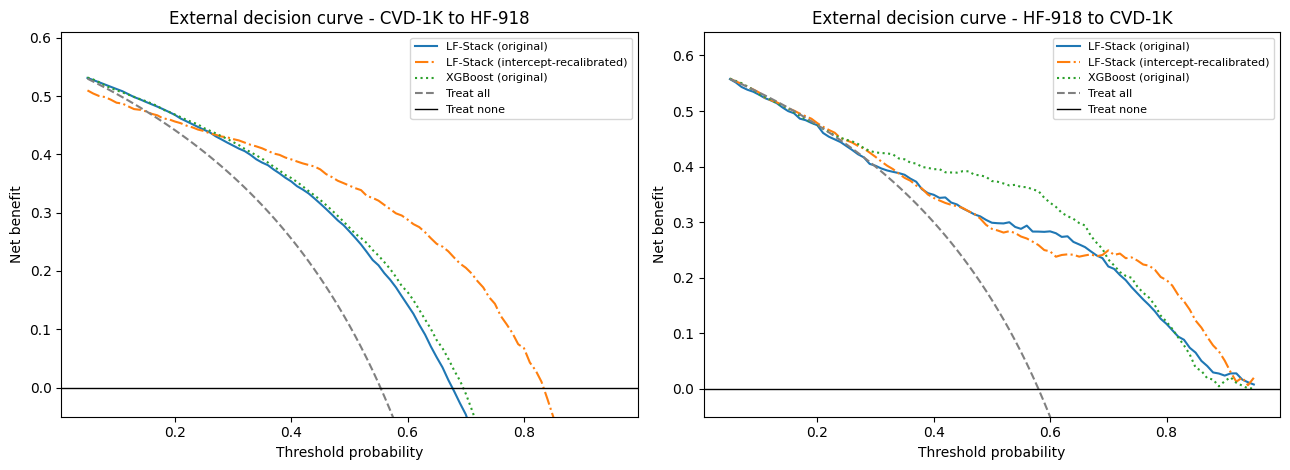

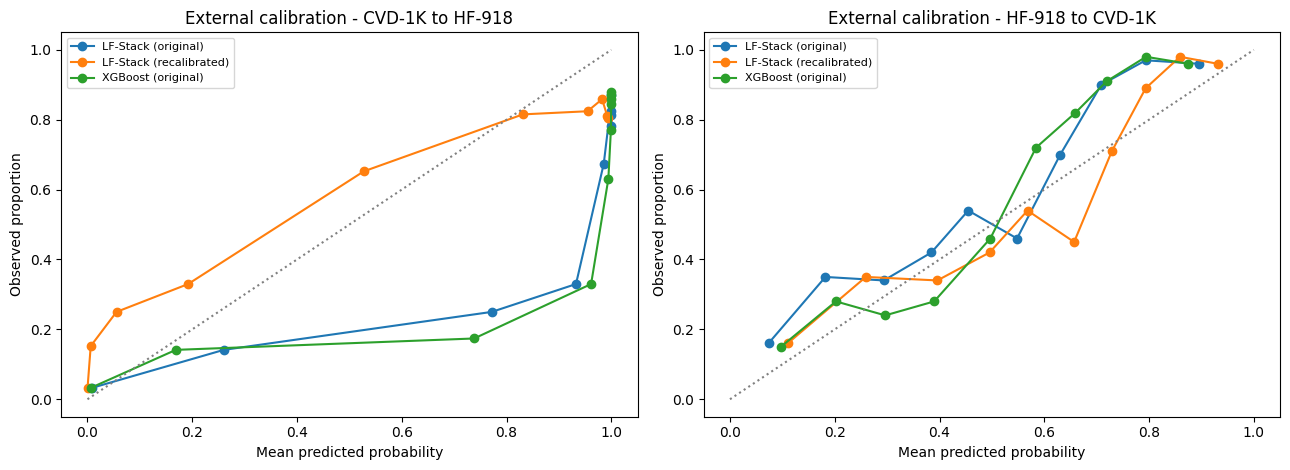

In [50]:
fig, axes = plt.subplots(1, len(EXT_PRED), figsize=(6.5 * len(EXT_PRED), 4.8))
for ax, ev in zip(np.atleast_1d(axes), EXT_PRED):
    for (m, label), style in {("STACK", "Original"): "-", ("STACK", "Intercept-recalibrated (5-fold, target)"): "-.",
                              ("XGB", "Original"): ":"}.items():
        d = EXT_DCA[(ev, m, label)]
        ax.plot(d["Threshold"], d["Net benefit (model)"], style, label=f"{FULL_NAME[m]} ({label.split(' (')[0].lower()})")
    ax.plot(d["Threshold"], d["Net benefit (treat all)"], "--", color="grey", label="Treat all")
    ax.axhline(0, color="black", lw=1, label="Treat none")
    ax.set_ylim(-0.05, max(0.05, d["Net benefit (treat all)"].max() * 1.15))
    ax.set_xlabel("Threshold probability")
    ax.set_ylabel("Net benefit")
    ax.set_title(f"External decision curve - {ev}")
    ax.legend(fontsize=8)
savefig("external_decision_curves")

fig, axes = plt.subplots(1, len(EXT_PRED), figsize=(6.5 * len(EXT_PRED), 4.8))
for ax, ev in zip(np.atleast_1d(axes), EXT_PRED):
    y = EXT_PRED[ev]["y"]
    for m, label, q in (("STACK", "LF-Stack (original)", EXT_PRED[ev]["STACK"][0]),
                        ("STACK", "LF-Stack (recalibrated)", recalibrate_intercept(y, EXT_PRED[ev]["STACK"][0])),
                        ("XGB", "XGBoost (original)", EXT_PRED[ev]["XGB"][0])):
        fy, fx = calibration_curve(y, q, n_bins=10, strategy="quantile")
        ax.plot(fx, fy, marker="o", label=label)
    ax.plot([0, 1], [0, 1], ":", color="grey")
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed proportion")
    ax.set_title(f"External calibration - {ev}")
    ax.legend(fontsize=8)
savefig("external_calibration_curves")


## 18c. CVD-1K sensitivity analysis: records with undocumented ST-slope code 0 excluded


In [51]:
def slope0_sensitivity(name="CVD-1K"):
    S, cols = SPLITS[name], cols_of(name)
    ktr, kte = (S["Xtr"]["slope"] != 0).values, (S["Xte"]["slope"] != 0).values
    Xtr, ytr = S["Xtr"].loc[ktr, cols].reset_index(drop=True), S["ytr"][ktr]
    Xte, yte = S["Xte"].loc[kte, cols].reset_index(drop=True), S["yte"][kte]
    folds = np.zeros(len(ytr), dtype=int)
    for k, (_, va) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(Xtr, ytr)):
        folds[va] = k
    oofs, preds = {}, {}
    for m in SINGLE:
        oof = np.zeros(len(ytr))
        for k in range(N_FOLDS):
            tr, va = folds != k, folds == k
            oof[va] = build(m, name, STORE[name][m]["params"]).fit(Xtr[tr], ytr[tr]).predict_proba(Xtr[va])[:, 1]
        oofs[m] = oof
        preds[m] = (build(m, name, STORE[name][m]["params"]).fit(Xtr, ytr).predict_proba(Xte)[:, 1], best_threshold(ytr, oof))
    O, T = np.column_stack([oofs[m] for m in STACK_LEARNERS]), np.column_stack([preds[m][0] for m in STACK_LEARNERS])
    preds["STACK"] = (meta_learner().fit(O, ytr).predict_proba(T)[:, 1], best_threshold(ytr, cross_fit_meta(O, ytr, folds)))
    return {"yte": yte, "preds": preds, "excluded_train": int((~ktr).sum()), "excluded_test": int((~kte).sum()),
            "n_train": len(ytr), "n_test": len(yte)}


if "CVD-1K" in DATA:
    SLOPE0, s, c = cached("cvd1k_slope0_sensitivity", slope0_sensitivity)
    log_time("CVD-1K", "STACK", "ST-slope code 0 sensitivity", s, c)
    y, ref = SLOPE0["yte"], SLOPE0["preds"]["STACK"]
    rows = []
    for k in ["STACK"] + SINGLE:
        p, t = SLOPE0["preds"][k]
        r = {"Model": FULL_NAME[k], "Threshold": t, **metrics(y, p, t)}
        if k != "STACK":
            r["DeLong p"], r["McNemar p"] = delong_pvalue(y, ref[0], p), mcnemar_pvalue(y, ref[0], ref[1], p, t)
        rows.append(r)
    SLOPE0_TABLE = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
    SLOPE0_TABLE.to_csv(OUT / "cvd1k_slope0_excluded.csv", index=False)
    display(pd.DataFrame([{k: SLOPE0[k] for k in ("n_train", "n_test", "excluded_train", "excluded_test")}]))
    display(SLOPE0_TABLE.round(4))


,n_train,n_test,excluded_train,excluded_test
0,656,164,144,36


,Model,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,Kappa,MCC,Brier,NPV,FPR,FNR,FDR,Misclassification rate,DeLong p,McNemar p
0,LF-Stack,0.54,0.9878,0.9914,0.9914,0.9792,0.9914,0.9995,0.9705,0.9705,0.0088,0.9792,0.0208,0.0086,0.0086,0.0122,NaN,NaN
1,CatBoost,0.66,0.9878,0.9914,0.9914,0.9792,0.9914,0.9995,0.9705,0.9705,0.0103,0.9792,0.0208,0.0086,0.0086,0.0122,1.0000,1.0000
2,Random Forest,0.56,0.9878,0.9914,0.9914,0.9792,0.9914,0.9993,0.9705,0.9705,0.0159,0.9792,0.0208,0.0086,0.0086,0.0122,0.4795,1.0000
3,LightGBM,0.67,0.9878,0.9914,0.9914,0.9792,0.9914,0.9995,0.9705,0.9705,0.0077,0.9792,0.0208,0.0086,0.0086,0.0122,1.0000,1.0000
4,XGBoost,0.32,0.9878,0.9914,0.9914,0.9792,0.9914,0.9995,0.9705,0.9705,0.0095,0.9792,0.0208,0.0086,0.0086,0.0122,1.0000,1.0000
5,Extra Trees,0.53,0.9817,0.9829,0.9914,0.9583,0.9871,0.9990,0.9555,0.9557,0.0146,0.9787,0.0417,0.0086,0.0171,0.0183,0.2815,1.0000
6,Logistic Regression,0.47,0.9817,0.9913,0.9828,0.9792,0.9870,0.9980,0.9561,0.9562,0.0164,0.9592,0.0208,0.0172,0.0087,0.0183,0.3816,1.0000
7,Gradient Boosting,0.30,0.9817,0.9748,1.0000,0.9375,0.9872,0.9995,0.9550,0.9560,0.0113,1.0000,0.0625,0.0000,0.0252,0.0183,1.0000,1.0000
8,SVM (RBF),0.48,0.9756,0.9746,0.9914,0.9375,0.9829,0.9962,0.9404,0.9408,0.0203,0.9783,0.0625,0.0086,0.0254,0.0244,0.1396,0.5000
9,Naive Bayes,0.30,0.9451,0.9820,0.9397,0.9583,0.9604,0.9912,0.8714,0.8736,0.0540,0.8679,0.0417,0.0603,0.0180,0.0549,0.0590,0.0156


## 19. Repeated-split evaluation for the small datasets (mean ± SD over random splits)

In [52]:
def repeated_split(name, seed):
    spec = DATA[name]
    cols = cols_of(name)
    Xtr, Xte, ytr, yte = train_test_split(spec["X"][cols], spec["y"], test_size=TEST_SIZE, stratify=spec["y"], random_state=seed)
    folds = np.zeros(len(ytr), dtype=int)
    for k, (_, va) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed).split(Xtr, ytr)):
        folds[va] = k
    res, oofs, tests = {}, {}, {}
    for m in SINGLE:
        oof = np.zeros(len(ytr))
        for k in range(N_FOLDS):
            tr, va = folds != k, folds == k
            oof[va] = build(m, name, STORE[name][m]["params"]).fit(Xtr[tr], ytr[tr]).predict_proba(Xtr[va])[:, 1]
        p = build(m, name, STORE[name][m]["params"]).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
        t = best_threshold(ytr, oof)
        oofs[m], tests[m] = oof, p
        res[m] = (accuracy_score(yte, p >= t), roc_auc_score(yte, p))
    O, T = np.column_stack([oofs[m] for m in STACK_LEARNERS]), np.column_stack([tests[m] for m in STACK_LEARNERS])
    meta = meta_learner().fit(O, ytr)
    t = best_threshold(ytr, cross_fit_meta(O, ytr, folds))
    p = meta.predict_proba(T)[:, 1]
    res["STACK"] = (accuracy_score(yte, p >= t), roc_auc_score(yte, p))
    chosen = max(SINGLE, key=lambda m: roc_auc_score(ytr, oofs[m]))
    res["CV_SELECT"] = res[chosen]
    res["CV_SELECT_NAME"] = chosen
    return res


REPEATED = []
for name in DATA:
    if len(DATA[name]["y"]) > REPEAT_MAX_ROWS:
        continue
    runs = []
    for seed in range(N_REPEATS):
        r, s, c = cached(f"repeat2_{name}_{seed}", lambda: repeated_split(name, seed))
        log_time(name, "STACK", f"Repeated split {seed}", s, c)
        runs.append(r)
    for k in ["STACK", "CV_SELECT"] + SINGLE:
        acc, auc = np.array([r[k][0] for r in runs]), np.array([r[k][1] for r in runs])
        REPEATED.append({"Dataset": name, "Model": FULL_NAME[k], "Accuracy mean": acc.mean(), "Accuracy SD": acc.std(),
                         "AUC mean": auc.mean(), "AUC SD": auc.std(), "Splits": N_REPEATS})
    picks = pd.Series([FULL_NAME[r["CV_SELECT_NAME"]] for r in runs]).value_counts()
    print(f"{name}: model chosen by training CV across splits -> " + ", ".join(f"{k} ({v})" for k, v in picks.items()))
REPEATED = pd.DataFrame(REPEATED).sort_values(["Dataset", "Accuracy mean"], ascending=[True, False])
REPEATED.to_csv(OUT / "repeated_splits.csv", index=False)
display(REPEATED.round(4))

CVD-1K: model chosen by training CV across splits -> CatBoost (7), Extra Trees (1), LightGBM (1), Random Forest (1)
HF-918: model chosen by training CV across splits -> CatBoost (4), LightGBM (4), Gradient Boosting (1), XGBoost (1)
HFCR-299: model chosen by training CV across splits -> Random Forest (7), Gradient Boosting (2), SVM (RBF) (1)


,Dataset,Model,Accuracy mean,Accuracy SD,AUC mean,AUC SD,Splits
0,CVD-1K,LF-Stack,0.9820,0.0084,0.9982,0.0017,10
11,CVD-1K,CatBoost,0.9815,0.0074,0.9981,0.0019,10
9,CVD-1K,XGBoost,0.9795,0.0085,0.9965,0.0027,10
1,CVD-1K,CV-selected single model,0.9780,0.0110,0.9975,0.0028,10
10,CVD-1K,LightGBM,0.9775,0.0112,0.9968,0.0028,10
7,CVD-1K,Extra Trees,0.9775,0.0119,0.9977,0.0016,10
6,CVD-1K,Random Forest,0.9760,0.0102,0.9963,0.0028,10
8,CVD-1K,Gradient Boosting,0.9740,0.0124,0.9961,0.0028,10
2,CVD-1K,Logistic Regression,0.9655,0.0104,0.9937,0.0035,10
5,CVD-1K,SVM (RBF),0.9625,0.0105,0.9936,0.0059,10


## 20. Figures: ROC curves, confusion matrices, model comparison

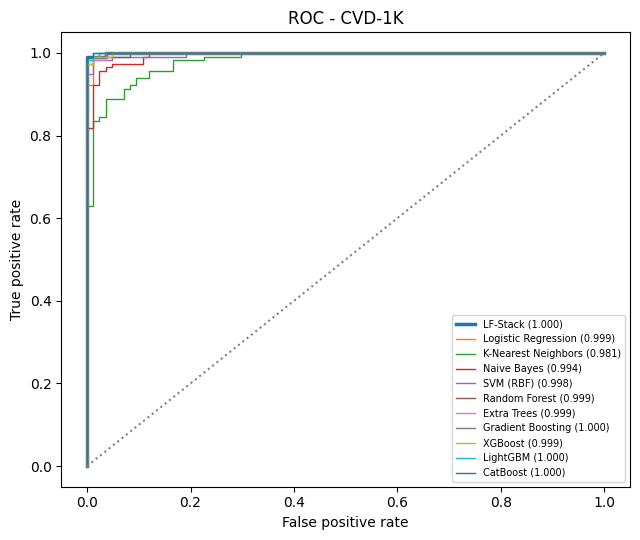

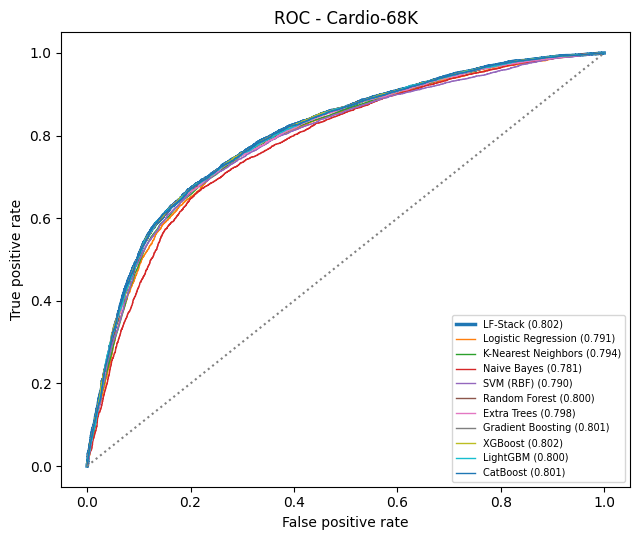

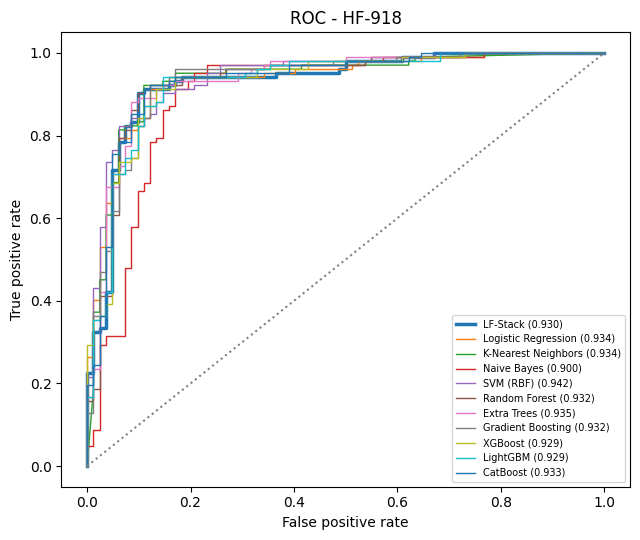

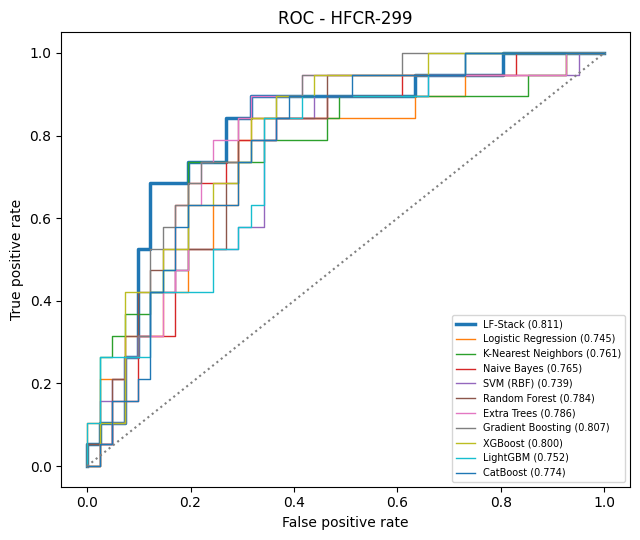

In [53]:
for name in DATA:
    y, M = SPLITS[name]["yte"], STORE[name]
    plt.figure(figsize=(6.5, 5.5))
    for k in ["STACK"] + SINGLE:
        fpr, tpr, _ = roc_curve(y, M[k]["test"])
        plt.plot(fpr, tpr, lw=2.5 if k == "STACK" else 1, label=f"{FULL_NAME[k]} ({roc_auc_score(y, M[k]['test']):.3f})")
    plt.plot([0, 1], [0, 1], ":", color="grey")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"ROC - {name}")
    plt.legend(fontsize=7)
    savefig(f"roc_{name}")

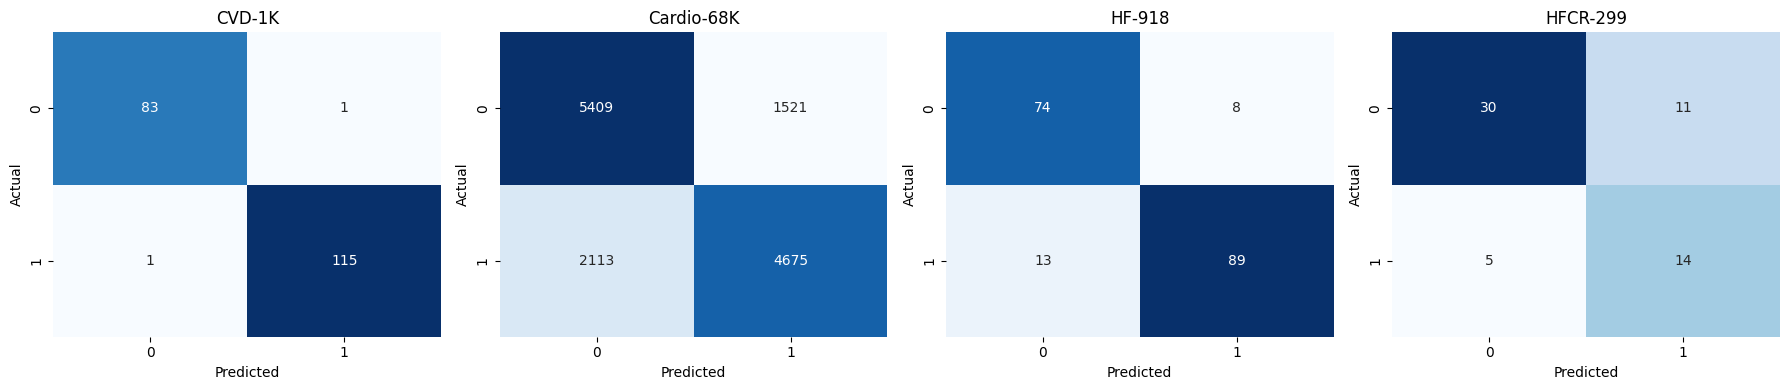

In [54]:
fig, axes = plt.subplots(1, len(DATA), figsize=(4.5 * len(DATA), 4))
for ax, name in zip(np.atleast_1d(axes), DATA):
    st = STORE[name]["STACK"]
    cm = confusion_matrix(SPLITS[name]["yte"], (st["test"] >= st["thr"]).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
savefig("confusion_matrices")

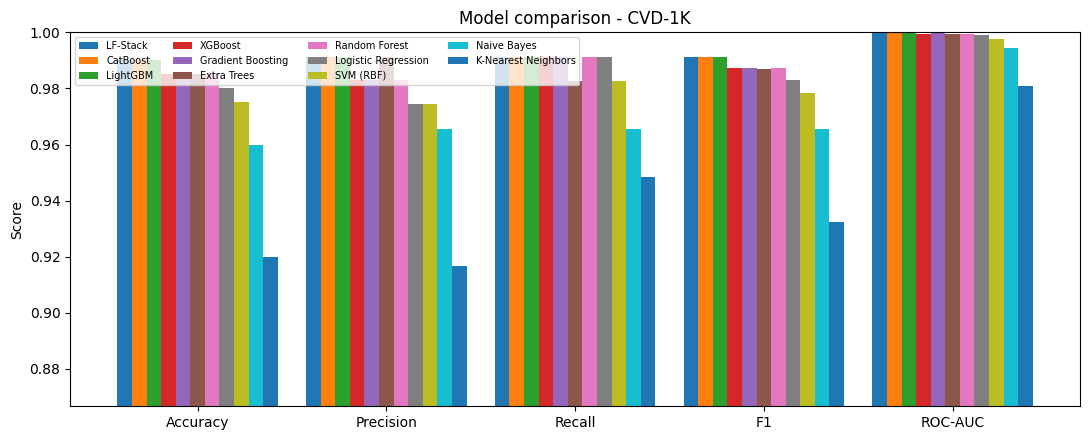

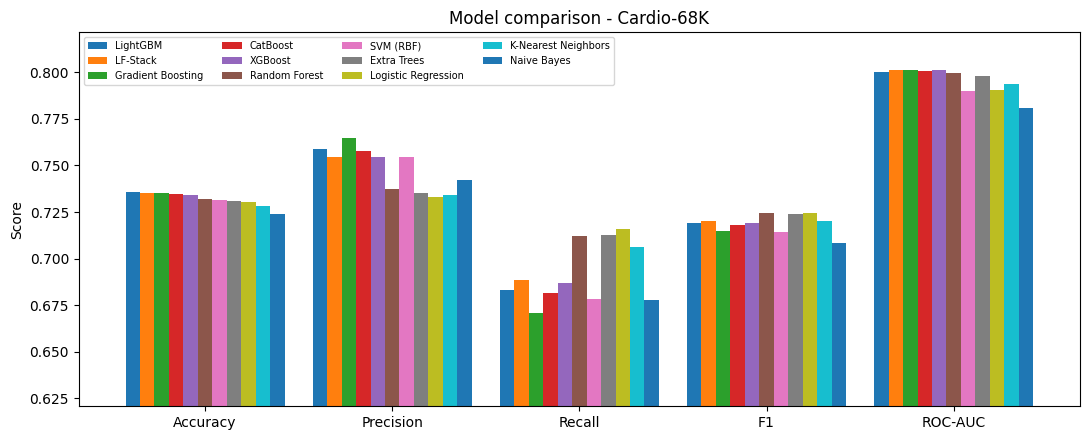

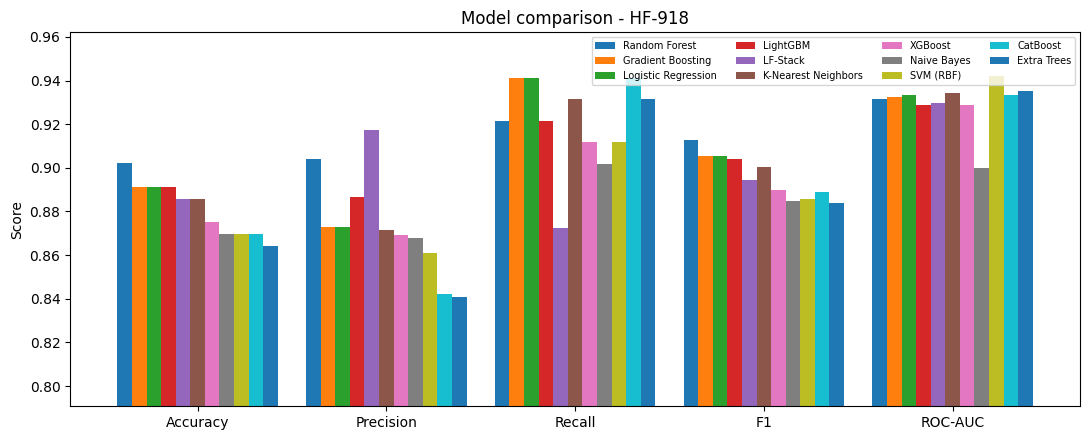

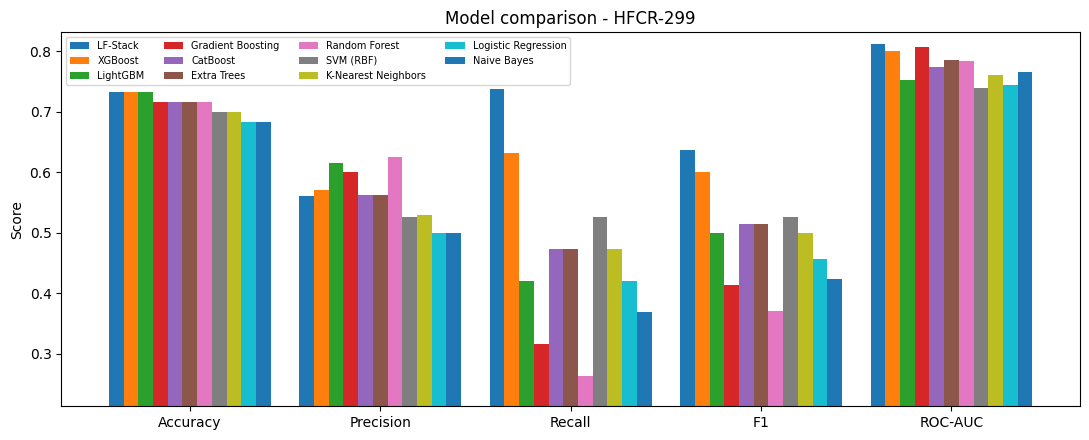

In [55]:
for name in DATA:
    t = COMPARISON[name].set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
    ax = t.T.plot(kind="bar", figsize=(11, 4.5), width=0.85, rot=0)
    ax.set_ylim(max(0, t.values.min() - 0.05), min(1.0, t.values.max() + 0.02))
    ax.set_ylabel("Score")
    ax.set_title(f"Model comparison - {name}")
    ax.legend(fontsize=7, ncol=4)
    savefig(f"model_comparison_{name}")

## 20b. Effect of duplicate records (leaky versus leakage-free protocol)
Same stacking architecture under two protocols. Leaky: duplicates kept, preprocessing fitted on all records before the split. Clean: duplicates removed, zeros in BP/cholesterol treated as missing, preprocessing fitted on training data only. Original features only, one-hot encoding for all models, threshold 0.5. Small datasets: ten random splits; the large dataset: one split.

In [56]:
LK_SOURCES = {"HDDC-1190": ("sid321axn/heart-statlog-cleveland-hungary-final", "heart_statlog_cleveland_hungary_final.csv", "ST slope"),
              "UHDD-1025": ("johnsmith88/heart-disease-dataset", "heart.csv", "trestbps"),
              "Cardio-70K": ("sulianova/cardiovascular-disease-dataset", "cardio_train.csv", "ap_hi")}


def lk_find(fname, slug, must_have):
    def ok(p):
        try:
            head = open(p, encoding="utf-8", errors="ignore").readline()
            return must_have in head
        except OSError:
            return False
    for root in ["/kaggle/input", str(WORK)]:
        if Path(root).exists():
            for p in sorted(Path(root).rglob(fname)):
                if ok(p):
                    return p
    try:
        import kagglehub
        for p in sorted(Path(kagglehub.dataset_download(slug)).rglob(fname)):
            if ok(p):
                return p
    except Exception as e:
        print(f"{fname}: download failed ({type(e).__name__})")
    return None


def lk_load(name, p):
    if name == "HDDC-1190":
        d = pd.read_csv(p)
        d.columns = [c.strip() for c in d.columns]
        d = d.rename(columns={"chest pain type": "cp", "resting bp s": "bp", "cholesterol": "chol", "fasting blood sugar": "fbs",
                              "resting ecg": "ecg", "max heart rate": "maxhr", "exercise angina": "angina", "ST slope": "slope"})
        return d, ["cp", "ecg", "slope"]
    if name == "UHDD-1025":
        d = pd.read_csv(p).rename(columns={"trestbps": "bp", "restecg": "ecg", "thalach": "maxhr", "exang": "angina"})
        return d, ["cp", "ecg", "slope", "thal"]
    d = pd.read_csv(p, sep=";").drop(columns=["id"]).rename(columns={"cardio": "target"})
    d["age"] = (d["age"] / 365.25).round(1)
    ok = (d.ap_hi.between(80, 250) & d.ap_lo.between(40, 200) & (d.ap_hi >= d.ap_lo)
          & d.height.between(120, 220) & d.weight.between(30, 200))
    return d[ok].reset_index(drop=True), []


LK_DATA = {}
for name, (lk_slug, fname, col) in LK_SOURCES.items():
    if name == "Cardio-70K" and not LK_RUN_LARGE:
        continue
    p = lk_find(fname, lk_slug, col)
    if p is None:
        print(f"{name}: not found, skipped")
        continue
    df, nominal = lk_load(name, p)
    LK_DATA[name] = {"df": df, "nominal": nominal}

display(pd.DataFrame([{"Dataset": n, "Rows": len(d["df"]), "Duplicate rows": int(d["df"].duplicated().sum()),
                       "Unique rows": int(len(d["df"]) - d["df"].duplicated().sum()), "Positive rate": round(d["df"]["target"].mean(), 3)}
                      for n, d in LK_DATA.items()]))

,Dataset,Rows,Duplicate rows,Unique rows,Positive rate
0,HDDC-1190,1190,272,918,0.529
1,UHDD-1025,1025,723,302,0.513
2,Cardio-70K,68613,674,67939,0.495


In [57]:
def lk_prepare(name, protocol):
    df = LK_DATA[name]["df"].copy()
    if protocol == "clean":
        df = df.drop_duplicates().reset_index(drop=True)
        for c in ("bp", "chol"):
            if c in df.columns:
                df.loc[df[c] == 0, c] = np.nan
    return df.drop(columns="target"), df["target"].astype(int).values


def lk_split(X, y, seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    Xtr, Xte = Xtr.reset_index(drop=True), Xte.reset_index(drop=True)
    h = lambda A, b: pd.util.hash_pandas_object(A.assign(_y=b), index=False).values
    return Xtr, Xte, ytr, yte, float(np.isin(h(Xte, yte), h(Xtr, ytr)).mean())


def lk_model(m, p, protocol, cols, nominal):
    est = make_estimator(m, p)
    if protocol == "clean":
        return Pipeline([("prep", make_prep([c for c in cols if c not in nominal], nominal, True, False)), ("clf", est)])
    return est


def lk_data(protocol, Xtr, Xte, nominal):
    if protocol == "clean":
        return Xtr, Xte
    prep = make_prep([c for c in Xtr.columns if c not in nominal], nominal, True, False).fit(pd.concat([Xtr, Xte]))
    return prep.transform(Xtr), prep.transform(Xte)


def lk_take(X, idx):
    return X.iloc[idx] if isinstance(X, pd.DataFrame) else X[idx]


def lk_tune(name, protocol, m):
    X, y = lk_prepare(name, protocol)
    Xtr, Xte, ytr, _, _ = lk_split(X, y, SEED)
    cols, nominal = list(Xtr.columns), LK_DATA[name]["nominal"]
    Atr, _ = lk_data(protocol, Xtr, Xte, nominal)
    idx = np.arange(len(ytr))
    if len(ytr) > TUNE_MAX_ROWS:
        idx, _ = train_test_split(idx, train_size=TUNE_MAX_ROWS, stratify=ytr, random_state=SEED)
    Xs, ys = lk_take(Atr, idx), ytr[idx]
    large = len(ytr) > LARGE_ROWS
    n = N_TRIALS_LARGE if large else N_TRIALS
    n = max(8, n // 3) if m in ("LR", "NB", "SVM", "KNN") else n
    cv = StratifiedKFold(3 if large else N_FOLDS, shuffle=True, random_state=SEED)
    obj = lambda t: cross_val_score(lk_model(m, suggest(m, t), protocol, cols, nominal), Xs, ys, cv=cv, scoring="roc_auc").mean()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(obj, n_trials=n)
    return study.best_params

In [58]:
def lk_run(name, protocol, seed, params):
    X, y = lk_prepare(name, protocol)
    Xtr, Xte, ytr, yte, overlap = lk_split(X, y, seed)
    cols, nominal = list(Xtr.columns), LK_DATA[name]["nominal"]
    Atr, Ate = lk_data(protocol, Xtr, Xte, nominal)
    skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed)
    test, oof, ins = {}, {}, {}
    for m in SINGLE:
        est = lk_model(m, params[m], protocol, cols, nominal).fit(Atr, ytr)
        test[m] = est.predict_proba(Ate)[:, 1]
        if m in STACK_LEARNERS:
            ins[m] = est.predict_proba(Atr)[:, 1]
            o = np.zeros(len(ytr))
            for tr, va in skf.split(Atr, ytr):
                o[va] = lk_model(m, params[m], protocol, cols, nominal).fit(lk_take(Atr, tr), ytr[tr]).predict_proba(lk_take(Atr, va))[:, 1]
            oof[m] = o
    T = np.column_stack([test[m] for m in STACK_LEARNERS])
    O = np.column_stack([oof[m] for m in STACK_LEARNERS])
    I = np.column_stack([ins[m] for m in STACK_LEARNERS])
    test["STACK"] = meta_learner().fit(O, ytr).predict_proba(T)[:, 1]
    test["STACK_NAIVE"] = meta_learner().fit(I, ytr).predict_proba(T)[:, 1]
    acc = {k: accuracy_score(yte, p >= LK_THRESHOLD) for k, p in test.items()}
    auc = {k: roc_auc_score(yte, p) for k, p in test.items()}
    return {"acc": acc, "auc": auc, "overlap": overlap, "n_train": len(ytr), "n_test": len(yte)}


LK_RUNS = {}
for name in LK_DATA:
    for protocol in ("leaky", "clean"):
        params = {}
        for m in SINGLE:
            params[m], s, c = cached(f"lk_{name}_{protocol}_{m}_tune", lambda: lk_tune(name, protocol, m))
            log_time(f"{name} ({protocol})", m, "Leakage tuning", s, c)
        seeds = [SEED] if len(LK_DATA[name]["df"]) > REPEAT_MAX_ROWS else list(range(N_REPEATS))
        runs = []
        for seed in seeds:
            r, s, c = cached(f"lk_{name}_{protocol}_seed{seed}", lambda: lk_run(name, protocol, seed, params))
            log_time(f"{name} ({protocol})", "STACK", f"Leakage split {seed}", s, c)
            runs.append(r)
        LK_RUNS[(name, protocol)] = runs

In [59]:
LK_NAMES = {**FULL_NAME, "STACK": "LF-Stack (OOF)", "STACK_NAIVE": "Naive stacking"}
LK_SUMMARY, LK_DETAIL = [], []
for (name, protocol), runs in LK_RUNS.items():
    keys = list(runs[0]["acc"])
    for k in keys:
        a = np.array([r["acc"][k] for r in runs])
        LK_DETAIL.append({"Dataset": name, "Protocol": protocol, "Model": LK_NAMES[k], "Accuracy mean": a.mean(), "Accuracy SD": a.std(),
                          "AUC mean": np.mean([r["auc"][k] for r in runs]), "Splits": len(runs)})
    single_means = {k: np.mean([r["acc"][k] for r in runs]) for k in SINGLE}
    best = max(single_means, key=single_means.get)
    st = np.array([r["acc"]["STACK"] for r in runs])
    LK_SUMMARY.append({"Dataset": name, "Protocol": protocol, "Splits": len(runs), "Test n": runs[0]["n_test"],
                       "Test records also in training (mean)": np.mean([r["overlap"] for r in runs]),
                       "LF-Stack accuracy mean": st.mean(), "LF-Stack accuracy SD": st.std(),
                       "Naive stacking accuracy mean": np.mean([r["acc"]["STACK_NAIVE"] for r in runs]),
                       "Best single model": FULL_NAME[best], "Best single accuracy mean": single_means[best]})
LK_SUMMARY, LK_DETAIL = pd.DataFrame(LK_SUMMARY), pd.DataFrame(LK_DETAIL)

LK_TEST = []
for name in LK_DATA:
    a = np.array([r["acc"]["STACK"] for r in LK_RUNS[(name, "leaky")]])
    b = np.array([r["acc"]["STACK"] for r in LK_RUNS[(name, "clean")]])
    p = float(stats.ttest_ind(a, b, equal_var=False).pvalue) if len(a) > 1 and len(b) > 1 else np.nan
    LK_TEST.append({"Dataset": name, "Accuracy leaky (mean)": a.mean(), "Accuracy clean (mean)": b.mean(),
                    "Difference (leaky − clean)": a.mean() - b.mean(), "Welch t-test p": p})
LK_TEST = pd.DataFrame(LK_TEST)

LK_SUMMARY.to_csv(OUT / "leakage_summary.csv", index=False)
LK_DETAIL.to_csv(OUT / "leakage_all_models.csv", index=False)
LK_TEST.to_csv(OUT / "leakage_test.csv", index=False)
display(LK_SUMMARY.round(4))
display(LK_TEST.round(4))
display(LK_DETAIL.sort_values(["Dataset", "Protocol", "Accuracy mean"], ascending=[True, True, False]).round(4))

,Dataset,Protocol,Splits,Test n,Test records also in training (mean),LF-Stack accuracy mean,LF-Stack accuracy SD,Naive stacking accuracy mean,Best single model,Best single accuracy mean
0,HDDC-1190,leaky,10,238,0.3685,0.9286,0.0148,0.9324,XGBoost,0.9294
1,HDDC-1190,clean,10,184,0.0000,0.8685,0.0168,0.8538,CatBoost,0.8717
2,UHDD-1025,leaky,10,205,0.9805,0.9966,0.0069,0.9985,Extra Trees,1.0000
3,UHDD-1025,clean,10,61,0.0000,0.8246,0.0549,0.8000,Random Forest,0.8426
4,Cardio-70K,leaky,1,13723,0.0172,0.7364,0.0000,0.7299,XGBoost,0.7361
5,Cardio-70K,clean,1,13588,0.0000,0.7365,0.0000,0.7291,XGBoost,0.7367


,Dataset,Accuracy leaky (mean),Accuracy clean (mean),Difference (leaky − clean),Welch t-test p
0,HDDC-1190,0.9286,0.8685,0.0601,0.0
1,UHDD-1025,0.9966,0.8246,0.1720,0.0
2,Cardio-70K,0.7364,0.7365,-0.0000,NaN


,Dataset,Protocol,Model,Accuracy mean,Accuracy SD,AUC mean,Splits
67,Cardio-70K,clean,XGBoost,0.7367,0.0000,0.8011,1
70,Cardio-70K,clean,LF-Stack (OOF),0.7365,0.0000,0.8017,1
69,Cardio-70K,clean,CatBoost,0.7362,0.0000,0.8016,1
66,Cardio-70K,clean,Gradient Boosting,0.7354,0.0000,0.8008,1
68,Cardio-70K,clean,LightGBM,0.7353,0.0000,0.8003,1
...,...,...,...,...,...,...,...
32,UHDD-1025,leaky,LightGBM,0.9971,0.0050,0.9999,10
34,UHDD-1025,leaky,LF-Stack (OOF),0.9966,0.0069,1.0000,10
27,UHDD-1025,leaky,SVM (RBF),0.9907,0.0101,0.9999,10
24,UHDD-1025,leaky,Logistic Regression,0.8493,0.0192,0.9193,10


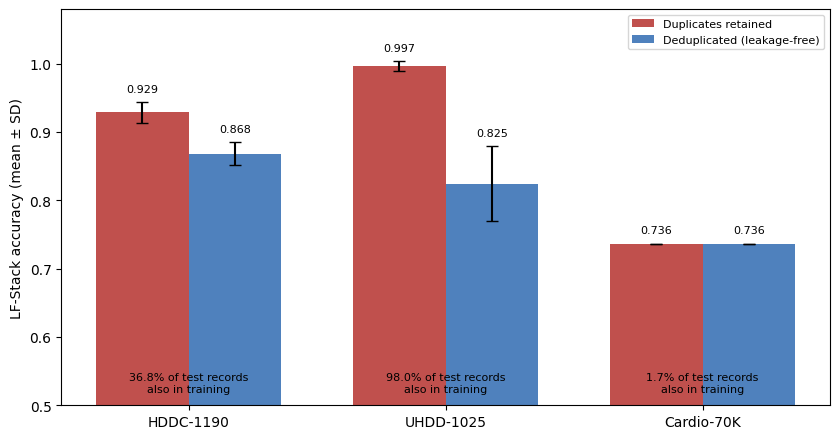

In [60]:
names = list(LK_DATA)
x = np.arange(len(names))
get = lambda n, pr, col: LK_SUMMARY[(LK_SUMMARY.Dataset == n) & (LK_SUMMARY.Protocol == pr)][col].iloc[0]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for off, pr, colr, lab in ((-0.18, "leaky", "#c0504d", "Duplicates retained"), (0.18, "clean", "#4f81bd", "Deduplicated (leakage-free)")):
    m = [get(n, pr, "LF-Stack accuracy mean") for n in names]
    e = [get(n, pr, "LF-Stack accuracy SD") for n in names]
    bars = ax.bar(x + off, m, 0.36, yerr=e, capsize=4, color=colr, label=lab)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=6)
for i, n in enumerate(names):
    ax.text(x[i], 0.52, f"{100 * get(n, 'leaky', 'Test records also in training (mean)'):.1f}% of test records\nalso in training", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0.5, 1.08)
ax.set_ylabel("LF-Stack accuracy (mean ± SD)")
ax.legend(fontsize=8, loc="upper right")
savefig("leakage_effect")

## 20c. Supplementary tables (single workbook)


In [61]:
SUPP = {"S1 Hyperparameters": globals().get("HYPERPARAMS"), "S4 Threshold rules": globals().get("THRESHOLD_RULES"),
        "S5 Subgroups": globals().get("SUBGROUPS"), "S6 Fairness by sex": globals().get("FAIRNESS"),
        "S7 External calibration": globals().get("EXT_CAL"), "S8 CVD-1K slope0 excluded": globals().get("SLOPE0_TABLE")}
for name in DATA:
    SUPP[f"S2 Characteristics {name}"] = TABLE1[name]
    SUPP[f"S3 Ablation {name}"] = ABLATION[name]
with pd.ExcelWriter(OUT / "supplementary_tables.xlsx") as w:
    for sheet, df in sorted(SUPP.items(), key=lambda kv: int(kv[0].split()[0][1:])):
        if isinstance(df, pd.DataFrame):
            df.to_excel(w, sheet_name=sheet[:31], index=False)
sorted(k for k, v in SUPP.items() if isinstance(v, pd.DataFrame))


['S1 Hyperparameters',
 'S2 Characteristics CVD-1K',
 'S2 Characteristics Cardio-68K',
 'S2 Characteristics HF-918',
 'S2 Characteristics HFCR-299',
 'S3 Ablation CVD-1K',
 'S3 Ablation Cardio-68K',
 'S3 Ablation HF-918',
 'S3 Ablation HFCR-299',
 'S4 Threshold rules',
 'S5 Subgroups',
 'S6 Fairness by sex',
 'S7 External calibration',
 'S8 CVD-1K slope0 excluded']

## 21. Running time

Training time (stack row = meta-learner + its six base learners)


Dataset,CVD-1K,Cardio-68K,HF-918,HFCR-299,Total (s),Total (min)
Model,,,,,,
LF-Stack,582.61,701.04,557.58,408.47,2249.70,37.49
SVM (RBF),4.71,822.73,4.17,1.11,832.72,13.88
Random Forest,200.63,176.40,210.89,169.65,757.57,12.63
Gradient Boosting,127.11,294.82,101.15,44.07,567.15,9.45
Extra Trees,132.93,78.93,139.09,92.93,443.88,7.40
CatBoost,79.08,96.61,72.93,76.32,324.94,5.42
LightGBM,24.75,31.96,14.88,11.64,83.23,1.39
XGBoost,18.04,21.46,18.55,13.78,71.83,1.20
K-Nearest Neighbors,1.46,50.05,1.54,1.47,54.52,0.91


Training time by stage, all datasets


Stage,Final fit,Meta-learner,OOF predictions,Tuning
Model,,,,
CatBoost,3.70,0.0,16.44,304.80
Extra Trees,5.19,0.0,20.64,418.05
Gradient Boosting,25.98,0.0,104.69,436.48
K-Nearest Neighbors,20.04,0.0,15.58,18.90
LF-Stack,0.00,1.1,0.00,0.00
LightGBM,1.27,0.0,4.56,77.40
Logistic Regression,0.47,0.0,1.96,5.70
Naive Bayes,0.18,0.0,0.64,3.69
Random Forest,15.14,0.0,60.95,681.48


Analysis time


,Dataset,Stage,Seconds
0,CVD-1K,Repeated split,235.05
1,CVD-1K,SHAP,218.54
2,CVD-1K,ST-slope code 0 sensitivity,23.10
3,CVD-1K to HF-918,External validation,23.59
4,Cardio-68K,SHAP,189.78
5,Cardio-70K (clean),Leakage split,136.16
6,Cardio-70K (clean),Leakage tuning,925.65
7,Cardio-70K (leaky),Leakage split,165.42
8,Cardio-70K (leaky),Leakage tuning,939.93
9,HDDC-1190 (clean),Leakage split,213.26


Total recorded time: 161.1 min


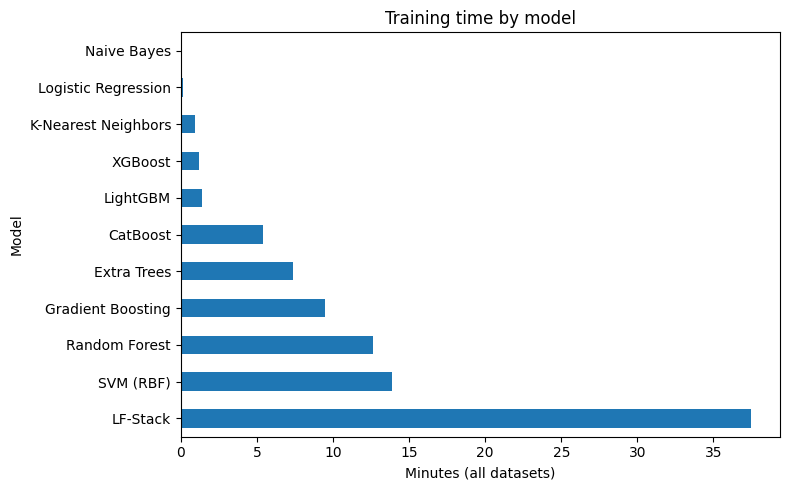

In [62]:
RUNTIME = times_table()
RUNTIME.to_csv(OUT / "running_time_detailed.csv", index=False)
TRAIN = RUNTIME[RUNTIME["Stage"].isin(["Tuning", "OOF predictions", "Final fit", "Meta-learner"])]
BY_MODEL = TRAIN.pivot_table(index="Model", columns="Dataset", values="Seconds", aggfunc="sum").fillna(0)
learners = [FULL_NAME[m] for m in STACK_LEARNERS]
BY_MODEL.loc[FULL_NAME["STACK"]] = BY_MODEL.loc[[FULL_NAME["STACK"]] + learners].sum()
BY_MODEL["Total (s)"] = BY_MODEL.sum(axis=1)
BY_MODEL["Total (min)"] = BY_MODEL["Total (s)"] / 60
BY_MODEL = BY_MODEL.sort_values("Total (s)", ascending=False)
BY_MODEL.to_csv(OUT / "running_time_training.csv")
BY_STAGE = TRAIN.pivot_table(index="Model", columns="Stage", values="Seconds", aggfunc="sum").fillna(0)
BY_STAGE.to_csv(OUT / "running_time_by_stage.csv")
ANALYSIS = RUNTIME[~RUNTIME.index.isin(TRAIN.index)].assign(Stage=lambda d: d["Stage"].str.replace(r" \d+$", "", regex=True))
ANALYSIS = ANALYSIS.groupby(["Dataset", "Stage"], as_index=False)["Seconds"].sum()
ANALYSIS.to_csv(OUT / "running_time_analyses.csv", index=False)
print("Training time (stack row = meta-learner + its six base learners)")
display(BY_MODEL.round(2))
print("Training time by stage, all datasets")
display(BY_STAGE.round(2))
print("Analysis time")
display(ANALYSIS.round(2))
print(f"Total recorded time: {RUNTIME['Seconds'].sum() / 60:.1f} min")

ax = BY_MODEL["Total (min)"].plot(kind="barh", figsize=(8, 5))
ax.set_xlabel("Minutes (all datasets)")
ax.set_title("Training time by model")
savefig("running_time")

## 22. Reproducibility record and output archive

In [63]:
versions = {"python_seed": SEED, "sklearn": sklearn.__version__, "xgboost": xgb.__version__, "optuna": optuna.__version__,
            "shap": shap.__version__, "numpy": np.__version__, "pandas": pd.__version__}
from importlib.metadata import version
versions.update(lightgbm=version("lightgbm"), catboost=version("catboost"))
config = {"config": {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list, bool))},
          "versions": versions, "features": CONFIG,
          "hyperparameters": {n: {m: STORE[n][m]["params"] for m in SINGLE} for n in DATA}}
(OUT / "environment_and_config.json").write_text(json.dumps(config, indent=2, default=str))
shutil.make_archive(str(WORK / "final_outputs"), "zip", OUT)
shutil.make_archive(str(WORK / "final_cache_backup"), "zip", CACHE)
display(pd.DataFrame([versions]))
sorted(p.name for p in OUT.iterdir())

,python_seed,sklearn,xgboost,optuna,shap,numpy,pandas,lightgbm,catboost
0,42,1.6.1,3.4.1,5.0.0,0.52.0,2.1.3,2.3.3,4.6.0,1.2.10


['ablation_CVD_1K.csv',
 'ablation_Cardio_68K.csv',
 'ablation_HFCR_299.csv',
 'ablation_HF_918.csv',
 'attribute_information_Cardio_68K.csv',
 'attribute_information_HFCR_299.csv',
 'attribute_information_Heart_disease_datasets_CVD_1K_HF_918.csv',
 'calibration_CVD_1K.csv',
 'calibration_Cardio_68K.csv',
 'calibration_HFCR_299.csv',
 'calibration_HF_918.csv',
 'comparison_CVD_1K.csv',
 'comparison_Cardio_68K.csv',
 'comparison_HFCR_299.csv',
 'comparison_HF_918.csv',
 'conformal.csv',
 'cvd1k_slope0_excluded.csv',
 'dataset_summary.csv',
 'dca_CVD_1K.csv',
 'dca_Cardio_68K.csv',
 'dca_HFCR_299.csv',
 'dca_HF_918.csv',
 'environment_and_config.json',
 'external_calibration_recalibration.csv',
 'external_validation.csv',
 'fairness.csv',
 'feature_decision.csv',
 'figures',
 'headline.csv',
 'leakage_all_models.csv',
 'leakage_summary.csv',
 'leakage_test.csv',
 'literature_comparison.csv',
 'model_CAT.csv',
 'model_ET.csv',
 'model_GB.csv',
 'model_KNN.csv',
 'model_LGBM.csv',
 'model_

In [67]:
def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(adj)
    out[order] = adj
    return out


for name in DATA:
    T = COMPARISON[name]
    rows = T["Model"] != "LF-Stack"
    for col in ("DeLong p", "McNemar p"):
        T.loc[rows, f"{col} (Holm)"] = holm(T.loc[rows, col])
    T.to_csv(OUT / f"comparison_{slug(name)}.csv", index=False)
    display(T[["Model", "DeLong p", "DeLong p (Holm)", "McNemar p", "McNemar p (Holm)"]].round(4))

,Model,DeLong p,DeLong p (Holm),McNemar p,McNemar p (Holm)
0,LF-Stack,NaN,NaN,NaN,NaN
1,CatBoost,0.4133,1.0000,1.0000,1.0000
2,LightGBM,0.7246,1.0000,1.0000,1.0000
3,XGBoost,0.3409,1.0000,1.0000,1.0000
4,Gradient Boosting,0.7901,1.0000,1.0000,1.0000
5,Extra Trees,0.2816,1.0000,1.0000,1.0000
6,Random Forest,0.3694,1.0000,1.0000,1.0000
7,Logistic Regression,0.3816,1.0000,0.6250,1.0000
8,SVM (RBF),0.1634,1.0000,0.2500,1.0000
9,Naive Bayes,0.0604,0.5436,0.0312,0.2812


,Model,DeLong p,DeLong p (Holm),McNemar p,McNemar p (Holm)
0,LightGBM,0.0124,0.0495,0.5423,1.0000
1,LF-Stack,NaN,NaN,NaN,NaN
2,Gradient Boosting,0.2775,0.5549,0.9506,1.0000
3,CatBoost,0.0124,0.0495,0.8103,1.0000
4,XGBoost,0.9350,0.9350,0.3594,1.0000
5,Random Forest,0.0027,0.0137,0.0596,0.3223
6,SVM (RBF),0.0000,0.0000,0.0537,0.3223
7,Extra Trees,0.0000,0.0000,0.0112,0.0896
8,Logistic Regression,0.0000,0.0000,0.0311,0.2179
9,K-Nearest Neighbors,0.0000,0.0000,0.0015,0.0134


,Model,DeLong p,DeLong p (Holm),McNemar p,McNemar p (Holm)
0,Random Forest,0.7105,1.0000,0.4531,1.0
1,Gradient Boosting,0.7381,1.0000,1.0000,1.0
2,Logistic Regression,0.6031,1.0000,1.0000,1.0
3,LightGBM,0.9109,1.0000,1.0000,1.0
4,LF-Stack,NaN,NaN,NaN,NaN
5,K-Nearest Neighbors,0.7414,1.0000,1.0000,1.0
6,XGBoost,0.8602,1.0000,0.7539,1.0
7,Naive Bayes,0.0800,0.8003,0.6636,1.0
8,SVM (RBF),0.1763,1.0000,0.5811,1.0
9,CatBoost,0.3915,1.0000,0.6291,1.0


,Model,DeLong p,DeLong p (Holm),McNemar p,McNemar p (Holm)
0,LF-Stack,NaN,NaN,NaN,NaN
1,XGBoost,0.6747,1.0000,1.0000,1.0
2,LightGBM,0.2119,1.0000,1.0000,1.0
3,Gradient Boosting,0.8919,1.0000,1.0000,1.0
4,CatBoost,0.2220,1.0000,1.0000,1.0
5,Extra Trees,0.3224,1.0000,1.0000,1.0
6,Random Forest,0.2893,1.0000,1.0000,1.0
7,SVM (RBF),0.0420,0.4197,0.7266,1.0
8,K-Nearest Neighbors,0.1727,1.0000,0.7266,1.0
9,Logistic Regression,0.1141,1.0000,0.5078,1.0


In [68]:
FULL_TUNE_MODELS = ["LGBM", "XGB"]
CARDIO = next(n for n in DATA if "Cardio" in n)


def full_tune_check(model, name=CARDIO):
    global TUNE_MAX_ROWS
    keep, TUNE_MAX_ROWS = TUNE_MAX_ROWS, 10**9
    try:
        tuned = tune(model, name)
    finally:
        TUNE_MAX_ROWS = keep
    S = SPLITS[name]
    oof = oof_predict(model, name, tuned["params"])
    fit = fit_full(model, name, tuned["params"])
    thr = best_threshold(S["ytr"], oof)
    ref, y = STORE[name][model], S["yte"]
    return {"Model": FULL_NAME[model], "Tuning records": len(S["ytr"]),
            "AUC (15,000-record tuning)": roc_auc_score(y, ref["test"]),
            "AUC (full-split tuning)": roc_auc_score(y, fit["test"]),
            "DeLong p": delong_pvalue(y, ref["test"], fit["test"]),
            "Accuracy (15,000-record tuning)": accuracy_score(y, ref["test"] >= ref["thr"]),
            "Accuracy (full-split tuning)": accuracy_score(y, fit["test"] >= thr),
            "McNemar p": mcnemar_pvalue(y, ref["test"], ref["thr"], fit["test"], thr)}


rows = []
for m in FULL_TUNE_MODELS:
    r, s, c = cached(f"{CARDIO}_{m}_fulltune_check", lambda: full_tune_check(m))
    log_time(CARDIO, m, "Full-split tuning check", s, c)
    rows.append(r)
FULL_TUNE = pd.DataFrame(rows)
FULL_TUNE.to_csv(OUT / "full_split_tuning_check.csv", index=False)
FULL_TUNE.round(4)

,Model,Tuning records,"AUC (15,000-record tuning)",AUC (full-split tuning),DeLong p,"Accuracy (15,000-record tuning)",Accuracy (full-split tuning),McNemar p
0,LightGBM,54871,0.8004,0.802,0.0003,0.7358,0.7343,0.3638
1,XGBoost,54871,0.8015,0.802,0.2969,0.7343,0.7352,0.5520


In [70]:
EXT_COLS = ["age", "gender", "chestpain", "restingBP", "serumcholestrol", "fastingbloodsugar", "restingrelectro",
            "maxheartrate", "exerciseangia", "oldpeak", "slope"]


def external(src, tgt):
    cols = [c for c in EXT_COLS if c in DATA[src]["X"].columns and c in DATA[tgt]["X"].columns]
    nom = [c for c in DATA[src]["nom_cols"] if c in cols]
    num = [c for c in cols if c not in nom]
    Xs, ys, Xt, yt = DATA[src]["X"][cols], DATA[src]["y"], DATA[tgt]["X"][cols], DATA[tgt]["y"]
    mk = lambda m: Pipeline([("prep", make_prep(num, nom, False, False)), ("clf", make_estimator(m, STORE[src][m]["params"]))])
    folds = np.zeros(len(ys), dtype=int)
    for k, (_, va) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(Xs, ys)):
        folds[va] = k
    oof, test = np.zeros((len(ys), len(STACK_LEARNERS))), np.zeros((len(yt), len(STACK_LEARNERS)))
    for j, m in enumerate(STACK_LEARNERS):
        for k in range(N_FOLDS):
            tr, va = folds != k, folds == k
            oof[va, j] = mk(m).fit(Xs[tr], ys[tr]).predict_proba(Xs[va])[:, 1]
        test[:, j] = mk(m).fit(Xs, ys).predict_proba(Xt)[:, 1]
    meta = meta_learner().fit(oof, ys)
    thr = best_threshold(ys, cross_fit_meta(oof, ys, folds))
    p = meta.predict_proba(test)[:, 1]
    xgb_p, xgb_thr = test[:, STACK_LEARNERS.index("XGB")], best_threshold(ys, oof[:, STACK_LEARNERS.index("XGB")])
    return {"Evaluation": f"{src} to {tgt}", "Shared features": len(cols), "Target n": len(yt),
            "Stack accuracy": accuracy_score(yt, p >= thr), "Stack AUC": roc_auc_score(yt, p),
            "XGBoost accuracy": accuracy_score(yt, xgb_p >= xgb_thr), "XGBoost AUC": roc_auc_score(yt, xgb_p),
            "McNemar p (stack vs XGBoost)": mcnemar_pvalue(yt, p, thr, xgb_p, xgb_thr),
            "pred": {"y": yt, "STACK": (p, thr), "XGB": (xgb_p, xgb_thr)}}


EXTERNAL, EXT_PRED = [], {}
for src, tgt in (("CVD-1K", "HF-918"), ("HF-918", "CVD-1K")):
    if src in DATA and tgt in DATA:
        r, s, c = cached(f"external_v3_{src}_{tgt}", lambda: external(src, tgt))
        r = dict(r)
        EXT_PRED[f"{src} to {tgt}"] = r.pop("pred")
        log_time(f"{src} to {tgt}", "STACK", "External validation", s, c)
        EXTERNAL.append(r)
EXTERNAL = pd.DataFrame(EXTERNAL)
EXTERNAL.to_csv(OUT / "external_validation.csv", index=False)
display(EXTERNAL.round(4))

,Evaluation,Shared features,Target n,Stack accuracy,Stack AUC,XGBoost accuracy,XGBoost AUC,McNemar p (stack vs XGBoost)
0,CVD-1K to HF-918,11,918,0.7124,0.8337,0.7211,0.8609,0.2912
1,HF-918 to CVD-1K,11,1000,0.7300,0.8106,0.7960,0.8589,0.0000
